# EritroFase
## Corrección del fondo en imágenes de fase de eritrocitos mediante redes neuronales informadas por la física

**Curso:** SI3014 · Redes Neuronales y Aprendizaje Profundo · Universidad EAFIT
**Grupo 1:** Juan José Escobar · Emmanuel Hernández · Mateo Lopera
**Entrega:** 11 de noviembre de 2026
**Repositorio:** https://github.com/Jjes07/DeepLearning-Final

Este notebook es **autocontenido**: todo el código del proyecto (utilidades, modelo, pérdidas, métricas, líneas base y figuras) está aquí, explicado en markdown. Se entrega **ejecutado y con todas sus salidas**, para que cada afirmación de la presentación pueda verificarse sin volver a correr nada.

## 0. Guía de lectura

### 0.1 Cómo ejecutar
- Ejecutar las celdas **en orden**, de arriba abajo. Cada sección solo depende de las anteriores.
- Dependencias externas: el dataset descomprimido en `data/raw/RBCs_Holograms/` y la selección congelada en `data/selection/` (lista `seleccion.csv` y las 30 imágenes elegidas; ver sección 3.6).
- Las semillas se fijan en la sección 2.2. Cada corrida guarda su configuración y sus métricas en `results/runs/<id>/`.
- Hardware, versiones y tiempos de ejecución se registran en las secciones 2.3 y 8.
- Las figuras y tablas que se guardan en `results/` son exactamente las que muestra el notebook.
- **Interruptor `RECALCULAR` (sección 2.1).** Los pasos costosos guardan su resultado en `results/cache/`. Con `RECALCULAR = False` (modo desarrollo) se cargan de ahí si ya existen, para poder retomar el trabajo con *Ejecutar todas las celdas anteriores* en segundos. **La ejecución que se entrega se hace con `RECALCULAR = True` y *Restart & Run All***, de modo que todas las salidas provienen de una sola ejecución completa.

### 0.2 Correspondencia con el contenido mínimo exigido
| Lineamiento del profesor | Sección del notebook | Componente de la rúbrica (peso) |
|---|---|---|
| A. Problema, justificación, objetivos | 1 | 1. Problema y objetivos (8) |
| B. Modelo, referencia y modificaciones | 4, 7 | 2. Arquitectura (13) |
| B. Base de datos y preprocesamiento | 3 | 3. Datos y preprocesamiento (13) |
| B. Hiperparámetros y equipo de cómputo | 2.3, 8 | 4. Entrenamiento (13) |
| C. Curvas de aprendizaje, sobreajuste/subajuste | 8 | 4. Entrenamiento (13) |
| C. Resultados cuantitativos e interpretación | 5, 6, 9 | 5. Resultados (13) |
| D. Datos no vistos y generalización | 10 | 6. Generalización (13) |
| E. Hallazgos, cumplimiento, limitaciones | 11, 12 | 7. Conclusiones (9) |

### 0.3 Criterios de rigor que sigue este trabajo
1. Cada experimento declara su **hipótesis antes** de ejecutarse, con un criterio de aceptación fijado de antemano, y la contrasta **después** con las salidas.
2. Se distingue lo que el diseño experimental **permite concluir** de lo que no: semillas, variantes que cambian varias cosas a la vez, diferencias dentro del ruido.
3. **Entrenamiento, validación y prueba están separados** y no comparten adquisiciones (sección 3.6). Umbrales e hiperparámetros se eligen con validación; la prueba se usa una sola vez, al final.
4. Las comparaciones son **justas**: mismo conjunto, misma métrica, misma máscara de referencia y presupuesto declarado.
5. Toda cifra citada en el texto proviene de una salida visible del notebook.
6. Las figuras llevan ejes rotulados con unidades. Si una figura no aporta, se reemplaza por una tabla.
7. El lenguaje se ajusta a la evidencia: "es consistente con", no "demuestra".

### 0.4 Registro de hipótesis
| ID | Etapa | Resumen | Resultado | Sección |
|---|---|---|---|---|
| H1.1–H1.9 | E1 · Datos | Formato, estructura del dataset, envolvimiento, fondo y calidad | 5 se cumplen, 3 se rechazan, 1 se reformula | 3.0 y 3.12 |
| H2.1–H2.7 | E2 · Código guía | Desenvolvimiento, compensación del fondo y extracción de la muestra con el código guía | 1 se cumple, 6 se rechazan | 4.0 y 4.7 |
| H6.1–H6.3 | Métricas · líneas base | Preservación y fondo lento de L2 (Zernike) y L3 (SIREN) del código guía, con las métricas definitivas | 3 se cumplen | 6.0 y 6.6 |

### 0.5 Registro de decisiones
| Decisión | Alternativas consideradas | Evidencia que la sustenta | Sección |
|---|---|---|---|
| Notebook autocontenido | Módulos en `src/` | Un solo archivo con código, explicación y salidas facilita la evaluación | 0 |
| Desenvolver la fase antes de modelar | Trabajar sobre la imagen envuelta | El fondo y las células presentan envolvimiento; desenvolver cuesta ~10 ms por imagen | 3.4, 3.5, 3.8 |
| Unidad de independencia = adquisición | Recorte o campo | Los 4 campos de una adquisición son la misma escena rotada; la partición original tiene fuga | 3.3 |
| Desarrollo (12/5/5) del 29/01 y generalización del 28/01 | Partición original del dataset | Cero adquisiciones compartidas y cero pares con contenido idéntico entre conjuntos | 3.6 |
| Desenvolver con `unwrap_phase` y no con SPINR | `spinr_unwrap` del código guía | `unwrap_phase` es exacto en el caso sintético y ~2.650 veces más rápido; SPINR deja errores de ~$2\pi$ | 4.5, 4.6 |
| Métrica de preservación local (célula frente a su anillo de fondo) | Altura global $h_C$ | La altura global se confunde con la pendiente del fondo bajo las células | 4.6 |
| Usar las máscaras de referencia y no `extract_sample_phase` | Máscara heurística del código guía | Sobresegmenta (Dice 0,76–0,82) | 4.6 |
| Líneas base sin máscaras de referencia ni datos de prueba, con hiperparámetros fijados de antemano (salvo el grado del polinomio, elegido en validación) | Ajustarlas mirando la referencia o la prueba | Comparación justa (0.3, criterio 4). El polinomio de grado 2 comparte el ajuste con la referencia y se reporta solo como referencia | 5.0, 5.1 |
| Métrica principal del fondo: RMS del fondo lento residual (Definición 13) | $\mathrm{RMS}_B/\sigma_{\text{ruido}}$ de 4.6 | Un fondo suave no puede quitar el ruido blanco, y $\sigma_{\text{ruido}}$ depende de un ajuste que no siempre converge y cambia ~20 % con el grado | 6.0–6.3 |
| Preservación: altura local con medias sobre la célula y su anillo (Definición 14) | Altura global; medianas | Con medias, un error afín del fondo no cambia la altura si el anillo es simétrico (Proposición 5; caso C4) | 6.1, 6.2 |
| Correlación de perfiles solo como métrica descriptiva | Métrica principal de forma | No cambia ante una absorción proporcional y compara con una imagen que todavía tiene fondo (casos C1 y C3) | 6.1, 6.2 |
| Línea base polinomial de grado 3 | Grados 1 y 2 | Es el único que cumple la regla de parsimonia fijada en 6.4 | 6.4 |

### 0.6 Decisiones revisables

Las decisiones de 0.5 están fundamentadas, pero no son las únicas posibles. Esta tabla reúne las que se revisarían si el modelo no supera a las líneas base, con la forma de evaluarlas.

**Reglas para revisarlas:**
- Solo se revisan con entrenamiento y validación.
- Todo cambio se anota en 0.5 con su motivo.
- Un cambio hecho después de mirar el conjunto de prueba se declara explícitamente, y la prueba deja de ser una evaluación final independiente.

| # | Decisión | Valor actual | Fundamento y su límite | Alternativas | Cómo se evaluaría | Sección |
|---|---|---|---|---|---|---|
| 1 | Modelo del fondo que define la referencia (máscaras 3.10 y $\sigma_{\text{ruido}}$ 3.9) | Polinomio robusto de grado 2 | Modelo mínimo con inclinación y curvatura. **Revisado en 6.3:** las máscaras son robustas al grado (Dice ≥ 0,90); $\sigma_{\text{ruido}}$ no lo es (±20 %); el grado 2 no basta en 3 de 17 imágenes | Grado 3 o Zernike | Consistencia y Dice entre grados (6.3) | 6 |
| 2 | Parámetros de las máscaras de referencia | Umbral $4\sigma$, apertura de 2 iteraciones, margen de 6 px | Elegidos por inspección visual (3.10) | $3\sigma$–$5\sigma$; margen de 4–10 px; descartar regiones de menos de ~300 px | Sensibilidad de las métricas a cada parámetro | 6 |
| 3 | Grado del polinomio como línea base | 1, 2 y 3 | Rango habitual de los ajustes de baja frecuencia | Grado ≥ 4 | Validación, con la métrica del modelo | 6 |
| 4 | Hiperparámetros de L2 (Zernike) y L3 (SIREN) | Los del código guía | No ajustarlos evita favorecerlas; pero si el modelo se ajusta en validación y ellas no, la comparación favorece al modelo | Número de términos, $\omega_0$, iteraciones, fracción $\rho$ | Ajustarlas en validación con el mismo presupuesto, si el modelo las supera por poco | 6, 9 |
| 5 | Tamaño de la imagen | Recortes de 256×256 | Unidad del dataset | Campo completo de 1024×1024, armando el mosaico (90 % de los campos son continuos, H1.3) | El fondo es lento a escala del campo: un recorte ve solo un trozo y en él las células pesan más | 7 (si el modelo no mejora) |
| 6 | Algoritmo de desenvolvimiento | `unwrap_phase` (Herráez et al., 2002) | Exacto en el caso sintético y rápido (4.5); reversible (3.11.2) | Algoritmos guiados por calidad o por mínimos cuadrados | Saltos residuales (3.11, 3.11.2) | Solo si quedan saltos que afecten a las células (en generalización, mediana 0,5) |
| 7 | Arquitectura de la INR | SIREN o características de Fourier (propuesta) | Objetivo general | $\omega_0$, $\sigma$, ancho y profundidad; Zernike más una INR residual | Validación | 7, 8 |
| 8 | Esquema de entrenamiento | Por definir: A (por imagen), B (U-Net) o C (coeficientes o hiperred) | Sección 7 | — | Validación y costo | 7 |
| 9 | Pérdidas y sus pesos (supuestos S1–S4) | Por definir | Supuestos físicos de 4.2 | Quitar o agregar términos; pesos $\lambda$ | Ablación en validación | 8 |
| 10 | Normalización de la entrada | Por definir | Pendiente desde 3.11 | Por imagen o global | Validación | 7, 8 |
| 11 | Número de imágenes | 12/5/5 y 8 | ~20 según la propuesta | Más adquisiciones (una imagen por adquisición, misma prueba de fuga de 3.6) | Si la variación entre imágenes no permite concluir | 9, 10 |
| 12 | Algoritmo del ajuste robusto de la referencia | 8 iteraciones; $\hat\sigma$ = MAD de los píxeles retenidos; recorte en $2{,}5\hat\sigma$ | En 3 de 17 imágenes deja fondo sin explicar (consistencia > 1,5; 6.3). **No se cambia por ahora:** M1 y M2 no dependen de $\sigma_{\text{ruido}}$ | Iterar hasta converger; estimar $\hat\sigma$ con todos los residuos; usar grado 3 | Consistencia del ajuste (6.3) | 6 |

**No son revisables después de mirar el conjunto de prueba:** las métricas, el criterio de éxito y la partición. Se fijan en la sección 6 y en 3.6.

## 1. Planteamiento del problema y objetivos  *(lineamiento A)*

### 1.1 Contexto: microscopía holográfica digital e imagen de fase cuantitativa

Los eritrocitos son casi transparentes: absorben muy poca luz y en una imagen de intensidad apenas se distinguen. Lo que sí modifican es el **retraso** de la onda que los atraviesa, es decir, su **fase**. Una cámara solo registra intensidad, por lo que la fase se recupera indirectamente: la **microscopía holográfica digital (DHM)** hace interferir la onda que atravesó la muestra con una onda de referencia, registra el patrón de interferencia (holograma) y reconstruye numéricamente el campo complejo $U = A\,e^{i\varphi}$.

> **Proposición 1 (desfase por camino óptico).** Una muestra de índice de refracción $n_s$ y espesor $t(x,y)$, inmersa en un medio de índice $n_m$ e iluminada con longitud de onda $\lambda$, introduce la fase
> $$\varphi(x,y) = \frac{2\pi\,(n_s - n_m)\,t(x,y)}{\lambda}.$$

Por eso la fase es un mapa del espesor y del contenido de la célula: con ella se estiman volumen, masa seca y morfología sin tinciones (*imagen de fase cuantitativa*, QPI). El dataset usado (Castañeda, Trujillo y Doblas, 2024) proviene de un DHM fuera de eje y telecéntrico con láser de 532 nm y objetivo 40×/0,65 NA.

En la práctica la fase reconstruida no vale cero fuera de las células: inclinaciones residuales del haz de referencia, curvatura y otras **aberraciones** del sistema óptico, más un desplazamiento constante arbitrario, dejan un **fondo** que se suma a la señal de la muestra. Además, el ángulo de un número complejo solo se conoce en $(-\pi, \pi]$: si la fase total sale de ese intervalo aparecen saltos artificiales de $2\pi$ (**envolvimiento**), que en estas imágenes se ven como manchas o anillos negros (sección 3.4).

### 1.2 Problema

Dada una imagen de fase de eritrocitos, se busca **estimar y eliminar el fondo** para que la región sin células quede en cero (negro en la visualización), **sin alterar** los valores de fase dentro de las células.

> **Definición 1 (modelo de formación de la imagen).** Para la fase medida $\varphi_{\text{obs}}$ (ya desenvuelta),
> $$\varphi_{\text{obs}}(x,y) = \varphi_{\text{cel}}(x,y) + b(x,y) + \varepsilon(x,y),$$
> con $\varphi_{\text{cel}}$ la contribución de las células, $b$ el fondo y $\varepsilon$ el ruido. El objetivo es estimar $\hat b$ y entregar $\varphi_{\text{corr}} = \varphi_{\text{obs}} - \hat b$.

La dificultad central es que la descomposición **no es única**: para cualquier función $h$, el par $(\varphi_{\text{cel}} + h,\; b - h)$ explica la medida igual de bien; en particular $\hat b = \varphi_{\text{obs}}$ la reproduce perfectamente y borra las células. Solo los supuestos físicos (fondo suave, muestra compacta y esparsa, signo de la fase celular) seleccionan una solución con sentido (sección 4).

### 1.3 Justificación y pertinencia del deep learning

**Por qué importa.** Todas las medidas cuantitativas de la célula (altura de fase, volumen, masa seca) se calculan **respecto al nivel del fondo**; un fondo inclinado o curvo introduce un sesgo que cambia de un punto a otro de la imagen. Un fondo en cero también es requisito para segmentar y comparar células entre imágenes.

**Por qué no basta un ajuste clásico.** El método habitual ajusta polinomios (por ejemplo, de Zernike) por mínimos cuadrados. Ese ajuste se sesga hacia las células salvo que se excluyan con una máscara, cuya construcción es otro problema, o que las células sean una perturbación pequeña (Tang et al., 2023; Huang y Cao, 2023). Por eso se evaluará como **línea base** (sección 5).

**Por qué una red informada por la física.**
1. **No hay etiquetas**: no existen versiones "limpias" de las imágenes. Una red cuya pérdida se construye con el modelo de formación y con supuestos físicos se entrena **sin etiquetas**; por eso basta un conjunto pequeño de imágenes, como indicó el profesor.
2. Las **representaciones neuronales implícitas** (SIREN, Sitzmann et al., 2020; características de Fourier, Tancik et al., 2020) representan el fondo como una función continua de las coordenadas cuyo **ancho de banda se controla** con un parámetro, lo que permite imponer suavidad de forma explícita.
3. Una red entrenada sobre varias imágenes puede **amortizar** la estimación y aplicarse a imágenes nuevas sin reoptimizar (Xu et al., 2025), algo que el ajuste por imagen no ofrece.

Si la red mejora o no a la línea base no se supone: es una pregunta empírica que responden las secciones 7 a 10.

### 1.4 Objetivos (según la propuesta enviada el 31/10/2026)

**Objetivo general.** Desarrollar y entrenar una red neuronal informada por la física, basada en representaciones implícitas, para estimar y compensar el fondo en imágenes de fase de eritrocitos, reducir su fase residual hacia cero y obtener una visualización con fondo negro, preservando la morfología y el perfil de fase de las células.

**Objetivos específicos.**
1. Analizar los fundamentos matemáticos y físicos de las representaciones neuronales implícitas con activaciones sinusoidales y su relación con la codificación de Fourier, vinculándolos con la fase óptica y las aberraciones del sistema, para definir una arquitectura y restricciones de entrenamiento adecuadas para la estimación del fondo.
2. Caracterizar y seleccionar un conjunto representativo de imágenes de eritrocitos de la base de datos de fase, considerando su calidad, resolución, unidades, variación del fondo y disponibilidad de regiones sin células, para establecer los conjuntos de desarrollo y evaluación del modelo.
3. Validar cuantitativamente la reducción del fondo y la conservación del perfil de fase de los eritrocitos mediante métricas del fondo residual, errores de fase en la región celular y comparación de perfiles transversales, utilizando referencias disponibles o simulaciones con valores conocidos.

### 1.5 Alcance y ajustes respecto a la propuesta

La caracterización de los datos (sección 3) obliga a precisar el alcance. Cada punto remite a la evidencia correspondiente.

| Tema | Propuesta | Ajuste | Evidencia |
|---|---|---|---|
| Unidades | Métricas en radianes | Los PNG son de 8 bits, sin calibración explícita. Los datos son consistentes con que el gris sea la fase **envuelta** escalada linealmente, $\varphi = 2\pi g/255 - \pi$. Se trabaja en **niveles de gris equivalentes**, $u = 255\,\varphi/(2\pi)$ (1 nivel ≈ 0,0246 rad). Así se respeta la indicación de trabajar con intensidades de gris, y la conversión a radianes queda condicionada a esa hipótesis | 3.4 |
| Envolvimiento | "Si los datos están envueltos, se verificará su desenvolvimiento" | Los datos **sí** están envueltos; se desenvuelven como paso de preprocesamiento | 3.4, 3.8 |
| Signo | Proposición 1: la célula suma fase | En este dataset las células quedan **por debajo** del fondo tras desenvolver (convención de signo de la reconstrucción); se invierte el signo para que la célula sea positiva | 3.5, 3.11 |
| Número de imágenes | Máximo ~20 | 22 para desarrollo (12 de entrenamiento, 5 de validación, 5 de prueba) y 8 adicionales solo para evaluar la generalización | 3.6 |
| Referencia | "Referencias disponibles o simulaciones" | No hay verdad conocida en las imágenes reales; las imágenes sintéticas se usarán solo si hacen falta para sustentar la generalización | 6, 10 |

## 2. Entorno de ejecución, reproducibilidad y utilidades generales

Esta sección prepara todo lo que usan las demás: librerías, rutas, semillas, dispositivo de cómputo y un reporte del equipo, que el lineamiento B exige presentar.

### 2.1 Importaciones y rutas del proyecto

Las rutas se construyen a partir de la carpeta donde está este notebook (`Path.cwd()`), así funcionan igual en Windows y en Mac. La celda falla con un mensaje claro si el dataset no está donde se espera.

In [1]:
# 2.1 Importaciones y rutas del proyecto
import os
import sys
import re
import json
import time
import random
import itertools
import platform
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
import scipy
from scipy import ndimage as ndi
import skimage
from skimage.restoration import unwrap_phase
import torch

# Raíz del proyecto = carpeta que contiene este notebook
ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "raw" / "RBCs_Holograms"
PHASE_DIR = DATA_DIR / "Phase"
SELECTION_DIR = ROOT / "data" / "selection"
FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"
RUNS_DIR = ROOT / "results" / "runs"
CACHE_DIR = ROOT / "results" / "cache"

# Interruptor global de recálculo de los pasos costosos (ver en_cache, sección 2.4):
#   True  -> se recalcula todo. OBLIGATORIO en la ejecución final que se entrega.
#   False -> se reutiliza lo guardado en results/cache/ (modo desarrollo, para retomar rápido).
RECALCULAR = False

for carpeta in (FIG_DIR, TAB_DIR, RUNS_DIR, CACHE_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

assert PHASE_DIR.exists(), (
    f"No se encontró {PHASE_DIR}. Descomprima el dataset en data/raw/RBCs_Holograms (ver README)."
)
assert (SELECTION_DIR / "seleccion.csv").exists(), f"Falta {SELECTION_DIR / 'seleccion.csv'}"
print("Raíz del proyecto :", ROOT)
print("Carpeta de fases  :", PHASE_DIR)
print("Subcarpetas       :", sorted(p.name for p in PHASE_DIR.iterdir() if p.is_dir()))
print("Modo              :", "RECÁLCULO COMPLETO" if RECALCULAR else "desarrollo (se reutiliza results/cache/ si existe)")

Raíz del proyecto : c:\Universidad EAFIT - Ing. de Sistemas\Redes Neuronales\Final\DeepLearning-Final
Carpeta de fases  : c:\Universidad EAFIT - Ing. de Sistemas\Redes Neuronales\Final\DeepLearning-Final\data\raw\RBCs_Holograms\Phase
Subcarpetas       : ['Training', 'Validation']
Modo              : desarrollo (se reutiliza results/cache/ si existe)


### 2.2 Semillas y determinismo

`fijar_semillas` fija las semillas de Python, NumPy y PyTorch (CPU y GPU). Además se desactiva la búsqueda automática de algoritmos de cuDNN (`benchmark = False`) y se le pide usar los deterministas: el entrenamiento es algo más lento, pero dos ejecuciones con la misma semilla dan los mismos números. Cuando un experimento se repita con varias semillas, se llamará a `fijar_semillas(s)` antes de cada repetición.

In [2]:
# 2.2 Semillas y determinismo
SEED = 42

def fijar_semillas(seed: int = SEED) -> None:
    """Fija las semillas de Python, NumPy y PyTorch para que los resultados sean repetibles."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

fijar_semillas(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Semilla global:", SEED)

Semilla global: 42


### 2.3 Dispositivo de cómputo y reporte del equipo

`seleccionar_dispositivo` usa la GPU NVIDIA (CUDA) si existe, si no la GPU de Apple (MPS) y, en último caso, la CPU. `reporte_entorno` arma una tabla con sistema operativo, procesador, RAM, GPU y versiones de las librerías, y la guarda en `results/tables/entorno.csv`. Esa tabla es la que se cita en la presentación.

In [3]:
# 2.3 Dispositivo de cómputo y reporte del equipo
def seleccionar_dispositivo() -> torch.device:
    """Devuelve CUDA si está disponible; si no, MPS (Mac); si no, CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = seleccionar_dispositivo()

def reporte_entorno() -> pd.DataFrame:
    """Tabla con el hardware y las versiones de software usadas en la ejecución."""
    filas = {
        "Sistema operativo": f"{platform.system()} {platform.release()}",
        "Procesador": platform.processor() or platform.machine(),
        "Núcleos lógicos de CPU": os.cpu_count(),
        "Python": sys.version.split()[0],
        "PyTorch": torch.__version__,
        "NumPy": np.__version__,
        "SciPy": scipy.__version__,
        "scikit-image": skimage.__version__,
        "Pandas": pd.__version__,
        "Matplotlib": matplotlib.__version__,
        "Pillow": PIL.__version__,
        "Dispositivo usado": str(DEVICE),
    }
    try:
        import psutil
        filas["RAM total (GB)"] = round(psutil.virtual_memory().total / 1024**3, 1)
    except ImportError:
        filas["RAM total (GB)"] = "no disponible (instale psutil)"
    if DEVICE.type == "cuda":
        props = torch.cuda.get_device_properties(0)
        filas["GPU"] = props.name
        filas["Memoria de la GPU (GB)"] = round(props.total_memory / 1024**3, 1)
        filas["CUDA (versión de PyTorch)"] = torch.version.cuda
    return pd.DataFrame.from_dict(filas, orient="index", columns=["Valor"])

entorno = reporte_entorno()
entorno.to_csv(TAB_DIR / "entorno.csv")
entorno

,Valor
Sistema operativo,Windows 11
Procesador,"AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD"
Núcleos lógicos de CPU,16
Python,3.13.14
PyTorch,2.13.0+cu126
NumPy,2.4.2
SciPy,1.17.1
scikit-image,0.26.0
Pandas,3.0.1
Matplotlib,3.10.8


### 2.4 Utilidades generales: estilo de figuras y guardado de resultados

- Un estilo común de matplotlib (tamaños de fuente, resolución, escala de grises por defecto).
- `guardar_figura(fig, etapa, nombre)`: guarda en `results/figures/<etapa>/<nombre>.png` **la misma figura que se acaba de mostrar**, de modo que todo lo que hay en `results/` proviene del notebook.
- `guardar_tabla(df, nombre)`: guarda una tabla en `results/tables/<nombre>.csv`.
- `barra_color(im, ax, etiqueta)`: añade una barra de color con su unidad.
- `en_cache(nombre, calcular)`: si `RECALCULAR = False` y existe `results/cache/<nombre>.pkl`, carga el resultado guardado; si no, ejecuta `calcular()`, guarda el resultado y lo devuelve. Se usa solo en los pasos costosos. Cada uso va acompañado de una comprobación de que lo cargado corresponde a los datos actuales; si una función cambia, hay que recalcular ese paso (`en_cache(..., recalcular=True)` o borrar su archivo de la caché).

In [4]:
# 2.4 Utilidades generales: estilo de figuras, guardado de resultados y caché
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "image.cmap": "gray",
})

def guardar_figura(fig, etapa: str, nombre: str) -> None:
    """Guarda una figura ya mostrada en results/figures/<etapa>/<nombre>.png."""
    carpeta = FIG_DIR / etapa
    carpeta.mkdir(parents=True, exist_ok=True)
    fig.savefig(carpeta / f"{nombre}.png", bbox_inches="tight")

def guardar_tabla(df: pd.DataFrame, nombre: str, index: bool = False) -> None:
    """Guarda una tabla en results/tables/<nombre>.csv."""
    df.to_csv(TAB_DIR / f"{nombre}.csv", index=index)

def barra_color(im, ax, etiqueta: str):
    """Barra de color con la unidad indicada en 'etiqueta'."""
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(etiqueta)
    return cb

def en_cache(nombre: str, calcular, recalcular: bool = None):
    """Devuelve el resultado guardado en results/cache/<nombre>.pkl si existe y no se pide recalcular;
    si no, ejecuta calcular(), guarda el resultado y lo devuelve."""
    recalcular = RECALCULAR if recalcular is None else recalcular
    ruta = CACHE_DIR / f"{nombre}.pkl"
    if ruta.exists() and not recalcular:
        print(f"[caché] '{nombre}' cargado de results/cache/ (no se recalculó)")
        return pd.read_pickle(ruta)
    t0 = time.perf_counter()
    valor = calcular()
    pd.to_pickle(valor, ruta)
    print(f"[calculado] '{nombre}' en {time.perf_counter() - t0:.1f} s y guardado en results/cache/")
    return valor

print("Utilidades generales listas.")

Utilidades generales listas.


## 3. Base de datos y preprocesamiento  *(lineamiento B · objetivo específico 2 · etapa E1)*

### 3.0 Hipótesis de la etapa

Las hipótesis H1.1 a H1.8 se fijaron el 6/11/2026, **antes** de analizar los datos de forma sistemática, y se conservan tal como se escribieron. Una exploración preliminar (7–8/11) mostró que la estructura del dataset era distinta de la supuesta; de ahí surgió **H1.9**, que se marca como formulada **después** de esa exploración. Esta sección contrasta todas con el dataset completo o con muestras aleatorias fijadas por semilla.

Definiciones usadas:
- **Recorte**: imagen PNG de 256×256 del dataset.
- **Variante**: la imagen base y sus versiones `-A` y `-B`.
- **Campo**: los recortes con la misma marca de tiempo y el mismo índice $X$ del nombre `Image__<fecha>__<hora>_<X>-<Y>[-A|-B]`.
- **Adquisición**: la marca de tiempo `<fecha>__<hora>`, que agrupa 4 campos.

| ID | Hipótesis | Criterio de aceptación (fijado de antemano) | Sección |
|---|---|---|---|
| H1.1 | Todos los PNG de fase son de 8 bits, un canal y 256×256 píxeles | 100 % de las imágenes revisadas cumplen (se revisan los 36.864 archivos) | 3.2 |
| H1.2 | `-A` y `-B` son volteos exactos (vertical y horizontal) de la imagen base; hay 12.288 recortes distintos | Diferencia = 0 en el 100 % de 300 recortes aleatorios | 3.3 |
| H1.3 | Los 16 recortes $Y$ de un campo forman una cuadrícula contigua de 4×4 (1024×1024 píxeles) | Salto medio en las costuras ≤ 1,5 × el salto medio en el interior, en ≥ 95 % de 50 campos | 3.3 |
| H1.4 | La partición original `Training`/`Validation` comparte recortes | ≥ 1 recorte presente en ambas carpetas | 3.3 |
| H1.5 | La escala 0–255 se fijó por campo o imagen completa, no por recorte; por eso los niveles de gris son comparables dentro de un campo pero no necesariamente entre campos | H1.3 se cumple **y** los niveles medios del fondo difieren entre campos más que dentro de un campo | 3.4 |
| H1.6 | La fase no está envuelta: no hay saltos tipo $2\pi$ dentro de las células | < 0,1 % de pares de píxeles vecinos dentro de células con salto > 128 niveles, y perfiles continuos en las células de centro oscuro | 3.8 |
| H1.7 | El fondo tiene una componente de baja frecuencia mayor que el ruido | $\sigma_{\text{fondo}}/\sigma_{\text{ruido}} > 2$ en la mayoría de las imágenes seleccionadas | 3.9 |
| H1.8 | Hay variabilidad de calidad suficiente para separar un grupo de desarrollo y uno de generalización | El índice de calidad del fondo muestra una cola identificable | 3.5 |
| H1.9 *(posterior a la exploración)* | Los 4 campos de una adquisición son la misma escena rotada 90°, 180° y 270° | Correlación máxima entre campos de la misma adquisición claramente mayor que entre adquisiciones distintas, en 10 adquisiciones aleatorias | 3.3 |

Una hipótesis que no se cumple **no se elimina**: se reporta como rechazada y se discuten sus consecuencias (sección 3.12).

### 3.1 Origen y características del dataset

Castañeda, Trujillo y Doblas (2024), *Data in Brief* 54, 110424. Datos públicos en OSF (doi 10.17605/OSF.IO/8P7BA).

| Característica | Valor según el artículo |
|---|---|
| Sistema | DHM fuera de eje, telecéntrico, interferómetro de Mach–Zehnder en transmisión |
| Iluminación | Láser de 532 nm |
| Óptica | Objetivo 40×/0,65 NA y lente de tubo de 200 mm |
| Cámara | 1920×1200 píxeles de 5,86 µm (≈ 0,15 µm por píxel en la muestra) |
| Reconstrucción | Método de Trujillo et al.: filtrado del orden +1 en Fourier y búsqueda automática de la mejor compensación |
| Muestras | Eritrocitos humanos; hasta 9 células por campo |
| Tamaño | 300 hologramas, recortados en parches de 256×256 y aumentados con rotaciones de 90° o 180° y volteos; tras eliminar recortes sin células o mal compensados quedan 36.864 pares holograma–fase |
| Formato | PNG; carpetas `Holograms` y `Phase`, cada una con 80 % / 20 % para entrenamiento y prueba |

El artículo no indica cómo se convirtió la fase a niveles de gris ni cómo se nombran los archivos. Las secciones 3.2 a 3.4 lo determinan a partir de los datos.

### 3.2 Inventario del dataset completo: estructura, conteos, nomenclatura y formato (H1.1)

**Utilidades de lectura.**
- `parsear_nombre(nombre)` extrae del nombre la adquisición, $X$, $Y$ y la variante. Los nombres tienen dos formatos: en `Phase/Training` llevan la extensión repetida (`…_1-5.png-A.png.png`) y en `Validation` no (`…_1-5-A.png`).
- `inventario(tipo)` recorre las carpetas sin abrir las imágenes y devuelve una tabla con un archivo por fila.
- `INDICE_FASE` asocia cada (adquisición, $X$, $Y$, variante) a su ruta, y `leer_recorte` lee cualquier recorte de fase a partir de esa identificación.

In [5]:
# 3.2.1 Utilidades de lectura del dataset
PATRON_NOMBRE = re.compile(
    r"Image__(?P<adq>\d{4}-\d\d-\d\d__\d\d-\d\d-\d\d)_(?P<X>\d+)-(?P<Y>\d+)(?:\.png)?(?:-(?P<var>[AB]))?"
)

def parsear_nombre(nombre: str) -> dict:
    """Extrae adquisición, índice X, índice Y y variante (base, A o B) del nombre de un archivo."""
    m = PATRON_NOMBRE.match(nombre)
    if m is None:
        raise ValueError(f"Nombre de archivo inesperado: {nombre}")
    d = m.groupdict()
    return {"adq": d["adq"], "X": int(d["X"]), "Y": int(d["Y"]), "variante": d["var"] or "base"}

def inventario(tipo: str = "Phase") -> pd.DataFrame:
    """Lista los archivos de Holograms o Phase con su partición y los campos del nombre."""
    filas = []
    for particion in ("Training", "Validation"):
        for entrada in os.scandir(DATA_DIR / tipo / particion):
            filas.append({"tipo": tipo, "particion": particion, "archivo": entrada.name,
                          **parsear_nombre(entrada.name)})
    return pd.DataFrame(filas)

def leer_png(ruta) -> np.ndarray:
    """Lee un PNG en escala de grises como arreglo float64 con valores 0–255."""
    return np.asarray(Image.open(ruta), dtype=np.float64)

inv_fase = inventario("Phase")
inv_holo = inventario("Holograms")
INDICE_FASE = {(r.adq, r.X, r.Y, r.variante): PHASE_DIR / r.particion / r.archivo
               for r in inv_fase.itertuples()}

def leer_recorte(adq: str, X: int, Y: int, variante: str = "base") -> np.ndarray:
    """Lee el recorte de fase identificado por (adquisición, X, Y, variante)."""
    return leer_png(INDICE_FASE[(adq, X, Y, variante)])

print(f"Archivos de fase: {len(inv_fase)} | archivos de holograma: {len(inv_holo)}")

Archivos de fase: 36864 | archivos de holograma: 36864


In [6]:
# 3.2.2 Conteos, estructura y nomenclatura
conteos = (pd.concat([inv_holo, inv_fase]).groupby(["tipo", "particion"]).size()
           .unstack().assign(Total=lambda t: t.sum(axis=1)))
display(conteos)

claves = ["adq", "X", "Y", "variante"]
misma_lista = set(map(tuple, inv_holo[claves].values)) == set(map(tuple, inv_fase[claves].values))
por_recorte = inv_fase.groupby(["adq", "X", "Y"])
adq_por_dia = inv_fase.drop_duplicates("adq").adq.str[:10].value_counts().sort_index()
estructura = pd.DataFrame({"Valor": {
    "Recortes distintos (adq, X, Y)": por_recorte.ngroups,
    "Variantes por recorte": str({int(k): int(v) for k, v in por_recorte.size().value_counts().items()}),
    "Variantes presentes": str(sorted(inv_fase.variante.unique())),
    "Adquisiciones (fecha y hora)": inv_fase.adq.nunique(),
    "Adquisiciones por día": str({k: int(v) for k, v in adq_por_dia.items()}),
    "Valores de X": str(sorted(inv_fase.X.unique().tolist())),
    "Valores de Y": f"{inv_fase.Y.min()} a {inv_fase.Y.max()}",
    "Campos (adq, X)": inv_fase.groupby(["adq", "X"]).ngroups,
    "Hologramas y fases tienen los mismos recortes": misma_lista,
}})
guardar_tabla(estructura.reset_index(names="Aspecto"), "E1_estructura_dataset")
estructura

particion,Training,Validation,Total
tipo,,,
Holograms,29491,7373,36864
Phase,29491,7373,36864


,Valor
"Recortes distintos (adq, X, Y)",12288
Variantes por recorte,{3: 12288}
Variantes presentes,"['A', 'B', 'base']"
Adquisiciones (fecha y hora),192
Adquisiciones por día,"{'2021-01-28': 5, '2021-01-29': 187}"
Valores de X,"[1, 2, 3, 4]"
Valores de Y,1 a 16
"Campos (adq, X)",768
Hologramas y fases tienen los mismos recortes,True


In [7]:
# 3.2.3 Formato de los PNG de fase (H1.1): se leen solo los encabezados de los 36.864 archivos
def _leer_formatos() -> Counter:
    formatos = Counter()
    for ruta in INDICE_FASE.values():
        with Image.open(ruta) as im:
            formatos[(im.mode, im.size)] += 1
    return formatos

formatos = en_cache("E1_formatos_png", _leer_formatos)
assert sum(formatos.values()) == len(INDICE_FASE), "La caché no corresponde al inventario actual"
tabla_formatos = pd.DataFrame([
    {"Modo PIL": modo, "Ancho × alto (px)": f"{tam[0]}×{tam[1]}", "Archivos": n}
    for (modo, tam), n in formatos.items()
])
display(tabla_formatos)
H1_1 = (len(formatos) == 1) and (("L", (256, 256)) in formatos)
print("Modo 'L' = 8 bits, un canal")
print("H1.1 (todos 8 bits, un canal, 256×256):", "SE CUMPLE" if H1_1 else "NO SE CUMPLE")

[caché] 'E1_formatos_png' cargado de results/cache/ (no se recalculó)


,Modo PIL,Ancho × alto (px),Archivos
0,L,256×256,36864


Modo 'L' = 8 bits, un canal
H1.1 (todos 8 bits, un canal, 256×256): SE CUMPLE


**Lectura de la salida (3.2).**
- `Holograms` y `Phase` tienen **36.864 archivos cada una** (29.491 en `Training` y 7.373 en `Validation`), con la misma lista de recortes: cada fase tiene su holograma. El artículo llama `Testing` a la segunda carpeta; en los datos se llama `Validation`.
- Hay **12.288 recortes distintos**, cada uno en exactamente **3 variantes** (base, `-A`, `-B`): $12.288 \times 3 = 36.864$.
- Los recortes salen de **192 adquisiciones** (5 del 28/01/2021 y 187 del 29/01/2021), con 4 campos $X$ por adquisición y 16 recortes $Y$ por campo: $192 \times 4 \times 16 = 12.288$. El artículo habla de 300 hologramas; con los archivos no es posible reconstruir esa cifra, y el resto del análisis se basa en lo que muestran los datos.
- **H1.1 se cumple:** los 36.864 PNG son de modo `L` (8 bits, un canal) y 256×256 píxeles. Cada píxel toma un valor entero entre 0 y 255: la resolución de la fase es de 256 niveles.

### 3.3 Estructura del dataset y fuga de información en la partición original (H1.2, H1.3, H1.4, H1.9)

Antes de elegir imágenes hay que saber **qué recortes son realmente independientes**. Si dos recortes contienen las mismas células (porque uno es el volteo o la rotación del otro), ponerlos en conjuntos distintos permitiría que el modelo se evalúe sobre datos que ya vio.

Se comprueban cuatro cosas:
1. **Volteos (H1.2):** si `-A` y `-B` son copias volteadas de la base.
2. **Cuadrícula (H1.3):** si los 16 recortes de un campo encajan como un mosaico continuo. La diferencia entre píxeles vecinos se mide como **diferencia circular**: dos grises cerca de 0 y de 255 se tratan como vecinos, porque (sección 3.4) los grises se comportan como una fase envuelta.
3. **Rotaciones (H1.9):** si los 4 campos de una adquisición son la misma escena rotada. Para cada par de campos se busca la transformación (8 rotaciones y volteos) y el desplazamiento que maximizan la correlación, calculada con la FFT sobre $e^{i\,2\pi g/255}$ para que el envolvimiento no la afecte. Como referencia se compara con campos de adquisiciones distintas.
4. **Partición original (H1.4):** cuántos recortes aparecen a la vez en `Training` y `Validation`.

In [8]:
# 3.3.1 Volteos (H1.2): ¿-A y -B son volteos exactos de la imagen base?
rng_e1 = np.random.default_rng(SEED)
lista_recortes = sorted(set(zip(inv_fase.adq, inv_fase.X, inv_fase.Y)))
muestra_recortes = [lista_recortes[i] for i in rng_e1.choice(len(lista_recortes), 300, replace=False)]
iguales_A = iguales_B = 0
for adq, X, Y in muestra_recortes:
    base = leer_recorte(adq, X, Y)
    iguales_A += np.array_equal(leer_recorte(adq, X, Y, "A"), np.flipud(base))
    iguales_B += np.array_equal(leer_recorte(adq, X, Y, "B"), np.fliplr(base))
print(f"-A = volteo vertical exacto  : {iguales_A}/300")
print(f"-B = volteo horizontal exacto: {iguales_B}/300")
H1_2 = (iguales_A == 300) and (iguales_B == 300) and (len(lista_recortes) == 12288)
print("H1.2:", "SE CUMPLE" if H1_2 else "NO SE CUMPLE", f"| recortes distintos = {len(lista_recortes)}")

-A = volteo vertical exacto  : 300/300
-B = volteo horizontal exacto: 300/300
H1.2: SE CUMPLE | recortes distintos = 12288


In [9]:
# 3.3.2 Cuadrícula (H1.3): ¿los 16 recortes de un campo forman un mosaico continuo de 1024×1024?
def campo_gris(adq: str, X: int) -> np.ndarray:
    """Une los 16 recortes base de un campo en orden de filas (Y = 1..4 primera fila, etc.)."""
    m = np.zeros((1024, 1024))
    for Y in range(1, 17):
        f, c = divmod(Y - 1, 4)
        m[f*256:(f+1)*256, c*256:(c+1)*256] = leer_recorte(adq, X, Y)
    return m

def diferencia_circular(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """|a - b| en niveles de gris, tratando 0 y 255 como vecinos (diferencia de fase envuelta)."""
    d = (a - b) * 2*np.pi/255
    return np.abs(np.angle(np.exp(1j*d))) * 255/(2*np.pi)

lista_campos = sorted(set(zip(inv_fase.adq, inv_fase.X)))
muestra_campos = [lista_campos[i] for i in rng_e1.choice(len(lista_campos), 50, replace=False)]
costuras = np.zeros(1023, bool); costuras[[255, 511, 767]] = True   # pares de columnas/filas (255,256), ...
filas = []
for adq, X in muestra_campos:
    m = campo_gris(adq, X)
    dh = diferencia_circular(m[:, 1:], m[:, :-1])
    dv = diferencia_circular(m[1:, :], m[:-1, :])
    salto_costura = np.r_[dh[:, costuras].ravel(), dv[costuras, :].ravel()].mean()
    salto_interior = np.r_[dh[:, ~costuras].ravel(), dv[~costuras, :].ravel()].mean()
    filas.append({"adq": adq, "X": X, "salto_costura": salto_costura, "salto_interior": salto_interior,
                  "razon": salto_costura / salto_interior})
cuadricula = pd.DataFrame(filas)
guardar_tabla(cuadricula, "E1_continuidad_costuras")
display(cuadricula[["salto_costura", "salto_interior", "razon"]].describe().loc[["mean", "50%", "min", "max"]].round(3))
frac_ok = (cuadricula.razon <= 1.5).mean()
H1_3 = frac_ok >= 0.95
print(f"Campos con razón ≤ 1,5: {frac_ok*100:.0f} %  →  H1.3:", "SE CUMPLE" if H1_3 else "NO SE CUMPLE")

,salto_costura,salto_interior,razon
mean,2.906,2.287,1.348
50%,2.371,2.254,1.074
min,1.702,1.648,0.788
max,12.537,3.058,7.607


Campos con razón ≤ 1,5: 90 %  →  H1.3: NO SE CUMPLE


In [10]:
# 3.3.3 Rotaciones (H1.9): ¿los 4 campos de una adquisición son la misma escena rotada?
TRANSFORMACIONES = {
    "identidad": lambda a: a, "rot90": lambda a: np.rot90(a, 1), "rot180": lambda a: np.rot90(a, 2),
    "rot270": lambda a: np.rot90(a, 3), "volteo_h": np.fliplr, "volteo_v": np.flipud,
    "transpuesta": lambda a: a.T, "antitranspuesta": lambda a: np.rot90(a, 2).T,
}

def campo_complejo(adq: str, X: int) -> np.ndarray:
    """Campo como fasor e^{i 2π g/255}: así la correlación no se ve afectada por el envolvimiento."""
    return np.exp(1j * 2*np.pi * campo_gris(adq, X) / 255)

def correlacion_maxima(a: np.ndarray, b: np.ndarray):
    """Máxima correlación circular normalizada entre a y b sobre todos los desplazamientos (vía FFT)."""
    a0, b0 = a - a.mean(), b - b.mean()
    cc = np.abs(np.fft.ifft2(np.fft.fft2(a0) * np.conj(np.fft.fft2(b0))))
    cc /= np.sqrt((np.abs(a0)**2).sum() * (np.abs(b0)**2).sum())
    k = np.unravel_index(cc.argmax(), cc.shape)
    return float(cc[k]), (int(k[0]), int(k[1]))

def mejor_transformacion(a: np.ndarray, b: np.ndarray):
    """Transformación de a (rotación o volteo) que mejor coincide con b, con su correlación y desplazamiento."""
    res = {nombre: correlacion_maxima(t(a), b) for nombre, t in TRANSFORMACIONES.items()}
    nombre = max(res, key=lambda n: res[n][0])
    return nombre, res[nombre][0], res[nombre][1]

lista_adq = sorted(inv_fase.adq.unique())
muestra_adq = [lista_adq[i] for i in rng_e1.choice(len(lista_adq), 10, replace=False)]
def _calcular_rotaciones() -> pd.DataFrame:
    filas = []
    for adq in muestra_adq:
        F1 = campo_complejo(adq, 1)
        for X in (2, 3, 4):
            t, r, k = mejor_transformacion(F1, campo_complejo(adq, X))
            filas.append({"comparación": f"X1 vs X{X}", "adq": adq, "transformación": t,
                          "correlación": r, "desplazamiento": k})
    # Referencia: campo X1 de adquisiciones distintas
    for a, b in zip(muestra_adq[:-1], muestra_adq[1:]):
        t, r, k = mejor_transformacion(campo_complejo(a, 1), campo_complejo(b, 1))
        filas.append({"comparación": "adquisiciones distintas", "adq": f"{a} / {b}", "transformación": t,
                      "correlación": r, "desplazamiento": k})
    return pd.DataFrame(filas)

rotaciones = en_cache("E1_rotaciones_campos", _calcular_rotaciones)
assert set(rotaciones[rotaciones["comparación"] != "adquisiciones distintas"].adq) == set(muestra_adq), \
    "La caché de rotaciones no corresponde a la muestra actual"
guardar_tabla(rotaciones, "E1_rotaciones_campos")
resumen_rot = rotaciones.groupby("comparación").agg(
    n=("correlación", "size"), correlación_min=("correlación", "min"),
    correlación_mediana=("correlación", "median"), correlación_max=("correlación", "max"),
    transformación_más_frecuente=("transformación", lambda s: s.value_counts().index[0]),
    veces=("transformación", lambda s: s.value_counts().iloc[0]))
display(resumen_rot.round(3))
min_misma = rotaciones[rotaciones["comparación"] != "adquisiciones distintas"]["correlación"].min()
max_distinta = rotaciones[rotaciones["comparación"] == "adquisiciones distintas"]["correlación"].max()
H1_9 = min_misma > max_distinta
print(f"Mínimo misma adquisición = {min_misma:.3f} | máximo adquisiciones distintas = {max_distinta:.3f}")
print("H1.9:", "SE CUMPLE" if H1_9 else "NO SE CUMPLE")

[caché] 'E1_rotaciones_campos' cargado de results/cache/ (no se recalculó)


,n,correlación_min,correlación_mediana,correlación_max,transformación_más_frecuente,veces
comparación,,,,,,
X1 vs X2,10,0.792,0.817,0.857,rot90,10
X1 vs X3,10,0.599,0.665,0.756,rot180,10
X1 vs X4,10,0.772,0.805,0.857,rot270,10
adquisiciones distintas,9,0.110,0.133,0.239,antitranspuesta,2


Mínimo misma adquisición = 0.599 | máximo adquisiciones distintas = 0.239
H1.9: SE CUMPLE


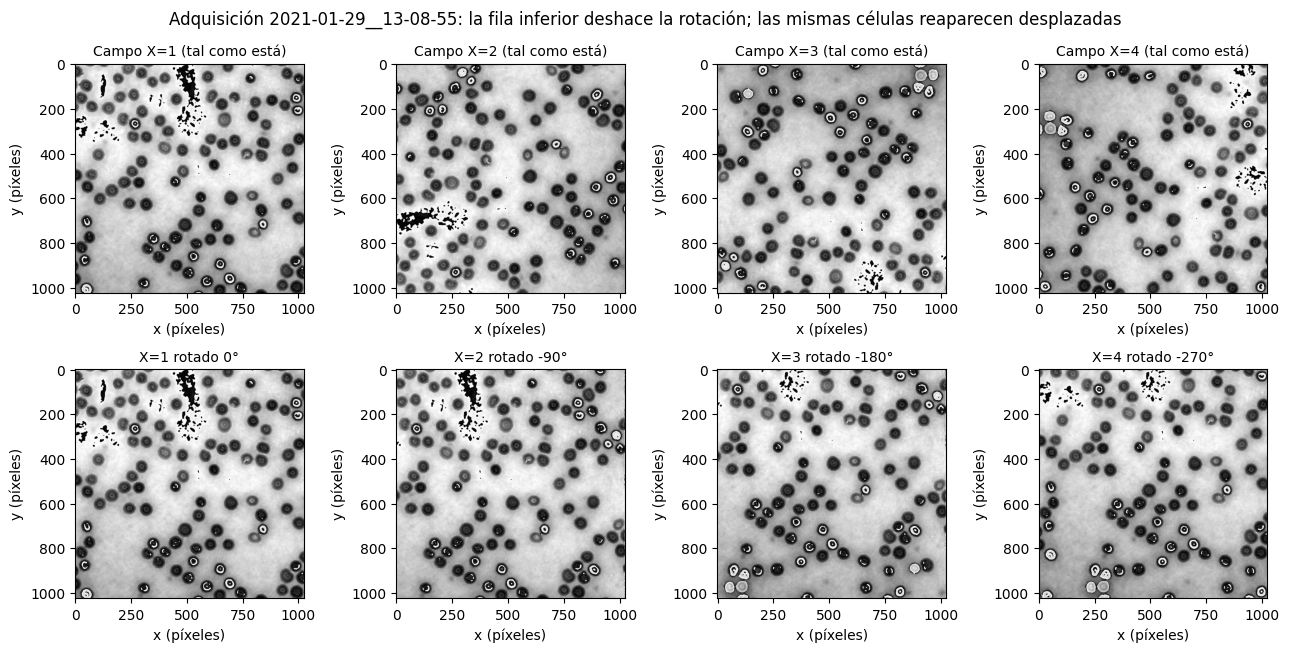

In [11]:
# 3.3.4 Figura: los 4 campos de una adquisición y su alineación con X1
adq_ej = muestra_adq[0]
fig, ax = plt.subplots(2, 4, figsize=(13, 6.6))
for j, X in enumerate((1, 2, 3, 4)):
    m = campo_gris(adq_ej, X)
    ax[0, j].imshow(m, vmin=0, vmax=255)
    ax[0, j].set_title(f"Campo X={X} (tal como está)")
    ax[1, j].imshow(np.rot90(m, -(X - 1)), vmin=0, vmax=255)
    ax[1, j].set_title(f"X={X} rotado {-(X - 1)*90}°")
    for a in ax[:, j]:
        a.set_xlabel("x (píxeles)"); a.set_ylabel("y (píxeles)")
fig.suptitle(f"Adquisición {adq_ej}: la fila inferior deshace la rotación; las mismas células reaparecen desplazadas")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "campos_rotados")

In [12]:
# 3.3.5 Partición original (H1.4): ¿hay recortes, campos o adquisiciones en Training y en Validation a la vez?
fuga_original = pd.DataFrame({
    "Unidad": ["Recorte (adq, X, Y)", "Campo (adq, X)", "Adquisición"],
    "Total": [inv_fase.groupby(["adq", "X", "Y"]).ngroups, inv_fase.groupby(["adq", "X"]).ngroups,
              inv_fase.adq.nunique()],
    "En ambas carpetas": [int(inv_fase.groupby(["adq", "X", "Y"]).particion.nunique().gt(1).sum()),
                          int(inv_fase.groupby(["adq", "X"]).particion.nunique().gt(1).sum()),
                          int(inv_fase.groupby("adq").particion.nunique().gt(1).sum())],
})
fuga_original["%"] = (100 * fuga_original["En ambas carpetas"] / fuga_original["Total"]).round(1)
guardar_tabla(fuga_original, "E1_fuga_particion_original")
display(fuga_original)
H1_4 = fuga_original.loc[0, "En ambas carpetas"] >= 1
print("H1.4:", "SE CUMPLE" if H1_4 else "NO SE CUMPLE")

,Unidad,Total,En ambas carpetas,%
0,"Recorte (adq, X, Y)",12288,5837,47.5
1,"Campo (adq, X)",768,768,100.0
2,Adquisición,192,192,100.0


H1.4: SE CUMPLE


**Lectura de la salida (3.3) y consecuencia para la partición.**
- **Volteos (H1.2, se cumple):** en los 300 recortes revisados, `-A` es el volteo vertical exacto y `-B` el horizontal exacto (300/300). Las variantes no aportan información nueva: hay 12.288 recortes distintos.
- **Cuadrícula (H1.3, se rechaza con el criterio fijado):** la razón entre el salto en las costuras y el salto interior tiene mediana 1,07, pero solo el **90 %** de los 50 campos (45) queda por debajo de 1,5, por debajo del 95 % exigido; el máximo llega a 7,6. En la mayoría de los campos los 16 recortes son contiguos, pero en una minoría hay costuras discontinuas cuya causa no se pudo determinar con estos datos. Esto **no cambia** la regla de partición, que se fija a nivel de adquisición y es más conservadora que la de campo.
- **Rotaciones (H1.9, se cumple):** entre campos de la misma adquisición la correlación máxima está entre **0,60 y 0,86**, siempre con la misma transformación (X2 = rotación de 90°, X3 = 180°, X4 = 270°, en las 10 de 10 adquisiciones), mientras que entre adquisiciones distintas no pasa de **0,24**. La figura lo muestra: al deshacer la rotación (fila inferior) aparecen las mismas células, desplazadas. El índice $X$ es, por tanto, un aumento de datos por rotación.
- **Partición original (H1.4, se cumple):** **5.837 de los 12.288 recortes (47,5 %)** están a la vez en `Training` y en `Validation` (uno como base y otro como volteo), y el 100 % de los campos y de las adquisiciones aparecen en ambas carpetas.

**Consecuencia.** Dos recortes solo son independientes si vienen de **adquisiciones distintas**: el dataset contiene 192 escenas, no 12.288 imágenes independientes. Evaluar con la partición original mediría el desempeño sobre escenas ya vistas, así que se construye una partición propia por adquisición (3.6).

### 3.4 Escala de grises y envolvimiento (H1.5)

> **Definición 2 (fase envuelta).** El ángulo de un número complejo solo se conoce módulo $2\pi$: $\;W(\varphi) = \varphi - 2\pi\,\operatorname{round}\!\big(\varphi/2\pi\big) \in (-\pi, \pi]$. Si la fase real sale de ese intervalo, la imagen muestra un salto brusco de $2\pi$ donde no hay ningún borde físico.

**Hipótesis de trabajo para la escala.** Si el gris $g$ es la fase envuelta escalada linealmente,
$$\varphi_{\text{env}} = \frac{2\pi\,g}{255} - \pi \quad\Longleftrightarrow\quad 1 \text{ nivel de gris} = \frac{2\pi}{255} \approx 0{,}0246 \text{ rad},$$
deberían observarse tres cosas: (i) todos los recortes usan el rango completo 0–255; (ii) aparecen saltos de casi 255 niveles entre píxeles vecinos; (iii) al **desenvolver** (sumar o restar $2\pi$ donde haya saltos) esos saltos desaparecen y la imagen queda continua.

`desenvolver(g)` aplica `skimage.restoration.unwrap_phase`, que implementa el algoritmo de Herráez et al. (2002): desenvuelve primero los píxeles más confiables, siguiendo un camino no continuo. `contar_saltos(a, umbral)` cuenta los pares de píxeles vecinos cuya diferencia supera el umbral.

In [13]:
# 3.4.1 Rango y saltos en una muestra de 768 recortes (uno aleatorio por campo)
def gris_a_fase_envuelta(g: np.ndarray) -> np.ndarray:
    """Hipótesis H1.5 (reformulada): gris 0–255 -> fase envuelta en (-π, π]."""
    return 2*np.pi*g/255 - np.pi

def desenvolver(g: np.ndarray) -> np.ndarray:
    """Fase desenvuelta (rad) a partir del gris envuelto (algoritmo de Herráez et al., 2002)."""
    return unwrap_phase(gris_a_fase_envuelta(g))

def contar_saltos(a: np.ndarray, umbral: float) -> int:
    """Pares de píxeles vecinos (horizontales y verticales) con |diferencia| > umbral."""
    return int((np.abs(np.diff(a, axis=0)) > umbral).sum() + (np.abs(np.diff(a, axis=1)) > umbral).sum())

PARES_VECINOS = 2 * 256 * 255
ys_muestra = [int(rng_e1.integers(1, 17)) for _ in lista_campos]   # un Y aleatorio por campo

def _calcular_rango() -> pd.DataFrame:
    filas = []
    for (adq, X), Y in zip(lista_campos, ys_muestra):
        g = leer_recorte(adq, X, Y)
        phi = desenvolver(g)
        filas.append({"adq": adq, "X": X, "Y": Y, "min": g.min(), "max": g.max(),
                      "saltos_200": contar_saltos(g, 200), "saltos_tras_desenvolver": contar_saltos(phi, np.pi)})
    return pd.DataFrame(filas)

rango = en_cache("E1_rango_y_saltos", _calcular_rango)
assert list(zip(rango.adq, rango.X, rango.Y)) == [(a, x, y) for (a, x), y in zip(lista_campos, ys_muestra)], \
    "La caché de rango no corresponde a la muestra actual"
guardar_tabla(rango, "E1_rango_y_saltos")
resumen_rango = pd.DataFrame({"Valor": {
    "Recortes analizados": len(rango),
    "Con mínimo = 0 (%)": round(100 * (rango["min"] == 0).mean(), 1),
    "Con máximo = 255 (%)": round(100 * (rango["max"] == 255).mean(), 1),
    "Con algún salto > 200 niveles (%)": round(100 * (rango.saltos_200 > 0).mean(), 1),
    "Pares con salto > 200 (mediana, % de los pares)": round(100 * rango.saltos_200.median() / PARES_VECINOS, 2),
    "Saltos > π que quedan tras desenvolver (mediana)": rango.saltos_tras_desenvolver.median(),
    "Recortes sin ningún salto tras desenvolver (%)": round(100 * (rango.saltos_tras_desenvolver == 0).mean(), 1),
}})
resumen_rango

[caché] 'E1_rango_y_saltos' cargado de results/cache/ (no se recalculó)


,Valor
Recortes analizados,768.00
Con mínimo = 0 (%),100.00
Con máximo = 255 (%),100.00
Con algún salto > 200 niveles (%),98.00
"Pares con salto > 200 (mediana, % de los pares)",0.81
Saltos > π que quedan tras desenvolver (mediana),1.00
Recortes sin ningún salto tras desenvolver (%),45.60


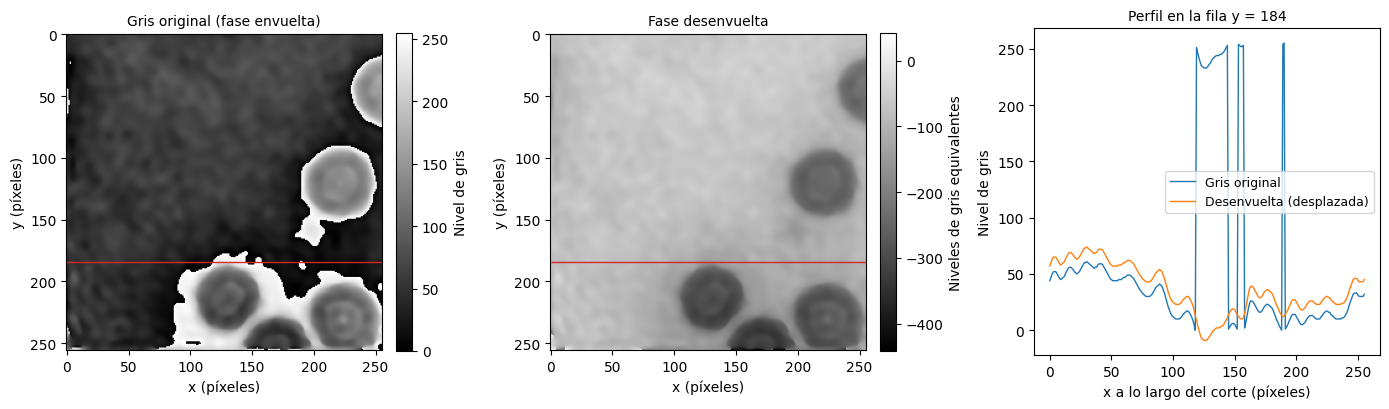

Saltos > 200 niveles en el original: 1001 | saltos > π tras desenvolver: 13


In [14]:
# 3.4.2 Ejemplo: un recorte con manchas envueltas en el fondo, antes y después de desenvolver
NG_POR_RAD = 255 / (2*np.pi)          # niveles de gris equivalentes por radián
g_ej = leer_png(SELECTION_DIR / "generalizacion" / "Image__2021-01-28__15-49-38_2-1-A.png")
u_ej = desenvolver(g_ej) * NG_POR_RAD
fila = int(np.argmax((np.abs(np.diff(g_ej, axis=1)) > 200).sum(axis=1)))   # fila con más saltos

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
im0 = ax[0].imshow(g_ej, vmin=0, vmax=255); ax[0].axhline(fila, color="tab:red", lw=1)
ax[0].set_title("Gris original (fase envuelta)"); barra_color(im0, ax[0], "Nivel de gris")
im1 = ax[1].imshow(u_ej); ax[1].axhline(fila, color="tab:red", lw=1)
ax[1].set_title("Fase desenvuelta"); barra_color(im1, ax[1], "Niveles de gris equivalentes")
for a in ax[:2]:
    a.set_xlabel("x (píxeles)"); a.set_ylabel("y (píxeles)")
ax[2].plot(g_ej[fila], label="Gris original", lw=1)
ax[2].plot(u_ej[fila] - np.median(u_ej[fila]) + np.median(g_ej[fila]), label="Desenvuelta (desplazada)", lw=1)
ax[2].set_xlabel("x a lo largo del corte (píxeles)"); ax[2].set_ylabel("Nivel de gris")
ax[2].set_title(f"Perfil en la fila y = {fila}"); ax[2].legend()
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "envolvimiento_ejemplo")
print(f"Saltos > 200 niveles en el original: {contar_saltos(g_ej, 200)} | saltos > π tras desenvolver: "
      f"{contar_saltos(u_ej / NG_POR_RAD, np.pi)}")

**Lectura de la salida (3.4).**
- En los 768 recortes (uno por campo), el **100 %** usa el rango completo (mínimo 0 y máximo 255) y el **98,0 %** tiene al menos un par de píxeles vecinos con un salto de más de 200 niveles. La mediana es el 0,81 % de los pares, unos 1.060 de los 130.560 pares de un recorte. Un borde físico de una célula sube unos 100 a 140 niveles (3.7.3), no 255 en un solo píxel.
- Tras desenvolver, la mediana de saltos residuales es 1, y el **45,6 %** de los recortes queda sin ningún salto.
- **Ejemplo:** en la imagen de generalización `15-49-38_2-1-A`, la mancha blanca del fondo es una región donde la fase pasó del tope del rango y "dio la vuelta". El perfil original (azul) salta entre ~250 y ~0, mientras que el desenvuelto (naranja) es continuo. Los saltos bajan de 1.001 a 13. Además, tras desenvolver, las células quedan **más oscuras** que el fondo, lo que anticipa la convención de signo de 3.5.

**Sobre H1.5.** La premisa (una normalización de grises por campo) no se sostiene: los tres hechos anteriores son consistentes con que el gris sea la **fase envuelta escalada linealmente**, $\varphi = 2\pi g/255 - \pi$, y por eso el criterio original no aplica. Esta reformulación se adopta como **hipótesis de trabajo**: es coherente con los datos, pero no se puede verificar la escala absoluta, porque el dataset no trae calibración. La consecuencia práctica es que **hay que desenvolver** antes de modelar.

### 3.5 Métricas por recorte, índice de calidad del fondo y candidatos (H1.8)

Para elegir imágenes con criterios explícitos (y no solo a ojo) se calcula un conjunto de métricas por recorte. Todas se obtienen **sin el modelo**:

1. Se desenvuelve la fase (3.4) y se cuentan los saltos mayores que $\pi$ que **quedan** (`res_saltos`): mide si el desenvolvimiento fue limpio.
2. Se ajusta un **fondo polinomial de grado 2** de forma robusta (`ajuste_fondo_robusto`): mínimos cuadrados repetidos 8 veces, cada vez solo con los píxeles cuyo residuo está a menos de $2{,}5\,\hat\sigma$, donde $\hat\sigma = 1{,}4826\cdot\mathrm{MAD}$ es una desviación estándar robusta. Así las células, que son valores atípicos, no arrastran el ajuste.
3. Las células son los píxeles con residuo mayor que $4\hat\sigma$ en la dirección de la célula (`signo`), limpiados con una apertura morfológica y con los huecos rellenos (`mascara_celulas`).

| Métrica | Qué mide | Unidad |
|---|---|---|
| `t_ms` | Tiempo de desenvolver | ms |
| `res_saltos` | Saltos $>\pi$ que quedan tras desenvolver | pares de píxeles |
| `signo` | $-1$ si las células quedan por debajo del fondo | — |
| `frac_cel` | Fracción del área ocupada por células | — |
| `completas`, `cortadas` | Células (≥ 600 px) que no tocan / sí tocan el borde | células |
| `saltos` | Píxeles junto a un salto $>128$ niveles en la imagen original | píxeles |
| `saltos_fondo` | Lo mismo, pero lejos (> 6 px) de las células: **envolvimiento en el fondo** | píxeles |
| `fondo_rango` | Rango del fondo ajustado (máximo − mínimo) | rad |
| `ruido` | $\hat\sigma$ del residuo en el fondo | rad |
| `cel_altura` | Mediana de la altura de las células sobre el fondo | rad |
| `gris_fondo`, `gris_celula` | Mediana del gris original en el fondo y en el interior de las células | nivel de gris |

Se evalúan **16 recortes por adquisición** (4 valores de $Y$ al azar en cada uno de los 4 campos, semilla 0): 3.072 recortes en total.

In [15]:
# 3.5.1 Funciones de métricas por recorte
H = W = 256
_yy, _xx = np.meshgrid(np.linspace(-1, 1, H), np.linspace(-1, 1, W), indexing="ij")
BASE_POLI = np.stack([np.ones_like(_xx), _xx, _yy, _xx**2, _xx*_yy, _yy**2], -1).reshape(-1, 6)

def ajuste_fondo_robusto(phi: np.ndarray, iteraciones: int = 8, k: float = 2.5):
    """Fondo polinomial de grado 2 por mínimos cuadrados reponderados. Devuelve (fondo, residuo, sigma)."""
    v = phi.ravel(); m = np.ones(v.size, bool)
    for _ in range(iteraciones):
        c = np.linalg.lstsq(BASE_POLI[m], v[m], rcond=None)[0]
        r = v - BASE_POLI @ c
        s = 1.4826 * np.median(np.abs(r[m] - np.median(r[m])))
        m = np.abs(r) < k * s
    return (BASE_POLI @ c).reshape(phi.shape), r.reshape(phi.shape), s

def mascara_celulas(residuo: np.ndarray, sigma: float, signo: int) -> np.ndarray:
    """Células = residuo > 4σ en la dirección 'signo', con apertura morfológica y huecos rellenos."""
    return ndi.binary_fill_holes(ndi.binary_opening(signo * residuo > 4 * sigma, iterations=2))

def mapa_saltos(g: np.ndarray, umbral: float = 128) -> np.ndarray:
    """Píxeles que tienen a su izquierda o arriba un vecino con |diferencia| > umbral."""
    j = np.zeros(g.shape, bool)
    j[:, 1:] |= np.abs(np.diff(g, axis=1)) > umbral
    j[1:, :] |= np.abs(np.diff(g, axis=0)) > umbral
    return j

def metricas_recorte(g: np.ndarray) -> dict:
    """Métricas de calidad de un recorte de fase en gris (0–255). No usan ningún modelo."""
    t0 = time.perf_counter()
    phi = desenvolver(g)
    t_ms = (time.perf_counter() - t0) * 1000
    fondo, r, s = ajuste_fondo_robusto(phi)
    signo = -1 if (r < -4*s).sum() > (r > 4*s).sum() else 1
    cel = mascara_celulas(r, s, signo)
    lab, n = ndi.label(cel)
    areas = ndi.sum(cel, lab, range(1, n + 1)) if n else np.array([])
    borde = set(np.unique(np.r_[lab[0], lab[-1], lab[:, 0], lab[:, -1]])) - {0}
    saltos = mapa_saltos(g)
    lejos = ~ndi.binary_dilation(cel, iterations=6)
    interior = ndi.binary_erosion(cel, iterations=6)
    return {
        "t_ms": round(t_ms, 1),
        "res_saltos": contar_saltos(phi, np.pi),
        "signo": signo,
        "frac_cel": round(float(cel.mean()), 4),
        "completas": sum(1 for j in range(1, n + 1) if areas[j-1] >= 600 and j not in borde),
        "cortadas": sum(1 for j in borde if areas[j-1] >= 600),
        "saltos": int(saltos.sum()),
        "saltos_fondo": int((saltos & lejos).sum()),
        "fondo_rango": round(float(fondo.max() - fondo.min()), 3),
        "ruido": round(float(s), 3),
        "cel_altura": round(float(np.median(signo * r[cel])) if cel.any() else 0.0, 3),
        "gris_fondo": float(np.median(g[lejos])) if lejos.any() else np.nan,
        "gris_celula": float(np.median(g[interior])) if interior.any() else np.nan,
    }
print("Funciones de métricas listas.")

Funciones de métricas listas.


In [16]:
# 3.5.2 Métricas de 3.072 recortes candidatos (16 por adquisición). Tarda unos minutos.
Y_POR_CAMPO = inv_fase[inv_fase.variante == "base"].groupby(["adq", "X"]).Y.apply(sorted).to_dict()
rnd_cand = random.Random(0)
candidatos = []
for adq in lista_adq:
    for X in (1, 2, 3, 4):
        ys = Y_POR_CAMPO[(adq, X)]
        candidatos += [(adq, X, Y) for Y in rnd_cand.sample(ys, min(4, len(ys)))]

def _calcular_metricas() -> pd.DataFrame:
    t0 = time.perf_counter(); filas = []
    for i, (adq, X, Y) in enumerate(candidatos):
        filas.append({"adq": adq, "X": X, "Y": Y, **metricas_recorte(leer_recorte(adq, X, Y))})
        if (i + 1) % 512 == 0:
            print(f"  {i+1}/{len(candidatos)} recortes ({time.perf_counter() - t0:.0f} s)")
    return pd.DataFrame(filas)

METRICAS = en_cache("E1_metricas_candidatos", _calcular_metricas)
assert list(zip(METRICAS.adq, METRICAS.X, METRICAS.Y)) == candidatos, "La caché no corresponde a los candidatos"
guardar_tabla(METRICAS, "E1_metricas_candidatos")
print(f"Métricas disponibles para {len(METRICAS)} recortes")

[caché] 'E1_metricas_candidatos' cargado de results/cache/ (no se recalculó)
Métricas disponibles para 3072 recortes


,Valor
"Tiempo de desenvolver, mediana (ms)",12.8000
"Desenvolvimiento limpio, 0 saltos residuales (%)",44.1000
"Células por debajo del fondo, signo = -1 (%)",89.3000
Sin envolvimiento en el fondo (%),37.3000
Con ≥ 200 px de envolvimiento en el fondo (%),27.1000
"Altura de las células, mediana (rad)",3.2450
"Rango del fondo, mediana (rad)",2.5675


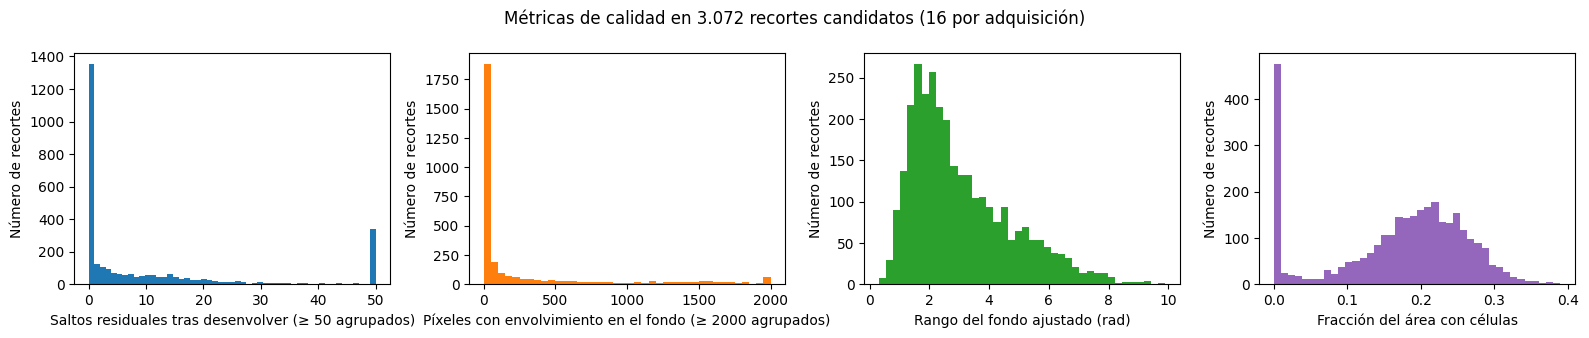

H1.8 (≥ 10 % de recortes sin envolvimiento en el fondo y ≥ 10 % con ≥ 200 px): SE CUMPLE


In [17]:
# 3.5.3 Resumen y distribuciones
d = METRICAS
resumen_cal = pd.DataFrame({"Valor": {
    "Tiempo de desenvolver, mediana (ms)": d.t_ms.median(),
    "Desenvolvimiento limpio, 0 saltos residuales (%)": round(100 * (d.res_saltos == 0).mean(), 1),
    "Células por debajo del fondo, signo = -1 (%)": round(100 * (d.signo == -1).mean(), 1),
    "Sin envolvimiento en el fondo (%)": round(100 * (d.saltos_fondo == 0).mean(), 1),
    "Con ≥ 200 px de envolvimiento en el fondo (%)": round(100 * (d.saltos_fondo >= 200).mean(), 1),
    "Altura de las células, mediana (rad)": d.cel_altura.median(),
    "Rango del fondo, mediana (rad)": d.fondo_rango.median(),
}})
display(resumen_cal)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
ax[0].hist(np.minimum(d.res_saltos, 50), bins=51, color="tab:blue")
ax[0].set_xlabel("Saltos residuales tras desenvolver (≥ 50 agrupados)"); ax[0].set_ylabel("Número de recortes")
ax[1].hist(np.minimum(d.saltos_fondo, 2000), bins=40, color="tab:orange")
ax[1].set_xlabel("Píxeles con envolvimiento en el fondo (≥ 2000 agrupados)"); ax[1].set_ylabel("Número de recortes")
ax[2].hist(d.fondo_rango, bins=40, color="tab:green")
ax[2].set_xlabel("Rango del fondo ajustado (rad)"); ax[2].set_ylabel("Número de recortes")
ax[3].hist(d.frac_cel, bins=40, color="tab:purple")
ax[3].set_xlabel("Fracción del área con células"); ax[3].set_ylabel("Número de recortes")
fig.suptitle("Métricas de calidad en 3.072 recortes candidatos (16 por adquisición)")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "distribucion_metricas_candidatos")
H1_8 = (d.saltos_fondo >= 200).mean() >= 0.10 and (d.saltos_fondo == 0).mean() >= 0.10
print("H1.8 (≥ 10 % de recortes sin envolvimiento en el fondo y ≥ 10 % con ≥ 200 px):",
      "SE CUMPLE" if H1_8 else "NO SE CUMPLE")

**Filtro automático de candidatos para el conjunto de desarrollo.** Se reproduce exactamente el filtro con el que se generaron las 40 candidatas que el grupo revisó visualmente (`data/selection/candidatos_mostrados.csv`):

| Criterio | Valor | Motivo |
|---|---|---|
| Día | 29/01/2021 | El 28/01 se reserva para generalización (otra sesión) |
| `res_saltos` | ≤ 2 | Desenvolvimiento limpio |
| `saltos_fondo` | 0 | Fondo sin envolvimiento: calidad media |
| `completas` | ≥ 2 | Hay células enteras para trazar perfiles |
| `frac_cel` | 0,05 a 0,40 | Hay células y la mayor parte es fondo |
| `signo` | −1 | Convención de signo mayoritaria |
| `gris_fondo`, `gris_celula` | 90 a 150 y ≥ 175 | Estilo visual preferido: células claras sobre fondo gris medio (rangos medidos en las imágenes que el grupo había elegido a ojo) |
| Independencia | Una por adquisición | Unidad independiente (3.3) |

De las adquisiciones que pasan el filtro se toma el mejor recorte (más células completas, menor ruido) y se sortean 40 adquisiciones con semilla 7.

In [18]:
# 3.5.4 Filtro automático de candidatos y comparación con la lista mostrada al grupo
filtro = d[d.adq.str.startswith("2021-01-29") & (d.res_saltos <= 2) & (d.saltos_fondo == 0)
           & (d.completas >= 2) & d.frac_cel.between(0.05, 0.40) & (d.signo == -1)]
con_estilo = filtro[filtro.gris_fondo.between(90, 150) & (filtro.gris_celula >= 175)]
mejor = con_estilo.sort_values(["completas", "ruido"], ascending=[False, True]).groupby("adq").head(1)
print(f"Pasan el filtro: {len(filtro)} | con el estilo: {len(con_estilo)} | adquisiciones: {mejor.adq.nunique()}")
rng_cand = np.random.default_rng(7)
if len(mejor) > 40:
    mejor = mejor.loc[rng_cand.choice(mejor.index, 40, replace=False)]
mejor = mejor.sort_values("adq")

MOSTRADOS = pd.read_csv(SELECTION_DIR / "candidatos_mostrados.csv", dtype={"n": str})
reproducidos = set(zip(mejor.adq, mejor.X, mejor.Y))
mostrados_set = set(zip(MOSTRADOS.ts, MOSTRADOS.X, MOSTRADOS.Y))
print(f"Candidatos reproducidos: {len(reproducidos)} | mostrados al grupo: {len(mostrados_set)} | "
      f"coinciden: {len(reproducidos & mostrados_set)}")
if reproducidos != mostrados_set:
    print("AVISO: la lista reproducida difiere de la congelada; se usa la congelada (candidatos_mostrados.csv).")

Pasan el filtro: 408 | con el estilo: 219 | adquisiciones: 76
Candidatos reproducidos: 40 | mostrados al grupo: 40 | coinciden: 40


**Lectura de la salida (3.5).**
- Desenvolver cuesta **12,5 ms** por recorte (mediana) en el equipo de la sección 2.3: no es un costo relevante.
- El desenvolvimiento queda **limpio en el 44,1 %** de los recortes. Según el histograma, unos 340 (≈ 11 %) conservan 50 o más saltos: en esos casos el desenvolvimiento falla parcialmente. Por eso el filtro exige `res_saltos` ≤ 2.
- En el **89,3 %** las células quedan por debajo del fondo (`signo` = −1): es una convención de signo del dataset, no un fenómeno físico, y se corrige en el preprocesamiento (3.11).
- **H1.8 se cumple:** el **37,3 %** de los recortes no tiene envolvimiento en el fondo y el **27,1 %** tiene 200 o más píxeles afectados. Hay material para un grupo de calidad media y otro de menor calidad.
- La altura mediana de las células es **3,25 rad**, mayor que $\pi$: por eso casi todas se envuelven por dentro (3.8). El rango del fondo tiene mediana **2,57 rad** y una cola larga hasta ~10 rad.
- El histograma de `frac_cel` tiene un pico en 0 (unos 470 recortes, ≈ 15 %) donde el detector no encuentra células, típicamente por desenvolvimiento defectuoso. El filtro (`completas` ≥ 2) los excluye. Aun así, indica que el método de máscaras no es universal, y por eso las máscaras de las 30 imágenes se revisan visualmente (3.10).
- **Reproducibilidad:** el filtro deja 408 recortes, 219 con el estilo visual y 76 adquisiciones, y las **40 candidatas reproducidas coinciden exactamente** con las que vio el grupo.
- **Sesgo a declarar:** el filtro de estilo codifica una preferencia visual (células claras sobre fondo gris), así que el conjunto de desarrollo es más limpio que el promedio del dataset.

### 3.6 Selección final y partición sin fuga de información

**Procedimiento.**
1. **Desarrollo (22 imágenes, 29/01).** De las 40 candidatas del filtro automático, el grupo eligió 22 por **inspección visual** (células claras y completas, fondo limpio, sin polvo ni artefactos). Los números elegidos quedan registrados abajo (`ELEGIDOS_CURACION`).
2. **Partición 12/5/5 estratificada.** Las 22 se ordenan por el rango del fondo, se dividen en 5 estratos y en cada estrato se sortea (semilla 42) una imagen de validación y una de prueba; el resto va a entrenamiento. Así los tres conjuntos tienen fondos comparables.
3. **Generalización (8 imágenes, 28/01).** Elegidas a ojo por tener defectos visibles: manchas de envolvimiento en el fondo y células envueltas. Proceden de **otro día de medición**.

**Por qué no hay fuga de información.** El argumento tiene cuatro pasos, cada uno con evidencia en este notebook:
1. **Unidad independiente.** Los volteos `-A`/`-B` son copias exactas (3.3.1), los recortes de un campo son vecinos en un mosaico continuo (3.3.2) y los 4 campos de una adquisición son la misma escena rotada (3.3.3). Por lo tanto, dos recortes solo son independientes si vienen de **adquisiciones distintas**.
2. **La partición original no sirve:** comparte recortes entre carpetas (3.3.5).
3. **Regla aplicada:** cada imagen de desarrollo viene de una adquisición distinta; la generalización viene de otro día.
4. **Verificación automática** (celdas siguientes, que detienen el notebook si fallan): (a) adquisiciones únicas y no compartidas entre conjuntos; (b) prueba de contenido de **todos contra todos**: para cada par de imágenes se busca la rotación, volteo y desplazamiento (con al menos 15 % de solapamiento) que maximiza la similitud entre $e^{i2\pi g_1/255}$ y $e^{i2\pi g_2/255}$; (c) un **control positivo** con un par que se sabe que es la misma escena rotada, para demostrar que la prueba detecta la fuga cuando existe.

In [19]:
# 3.6.1 Reproducción de la partición y carga de la selección congelada
ELEGIDOS_CURACION = [1, 2, 3, 5, 8, 10, 11, 12, 13, 15, 16, 17, 21, 24, 25, 27, 28, 29, 31, 36, 37, 38]

dev = MOSTRADOS[MOSTRADOS.n.astype(int).isin(ELEGIDOS_CURACION)].sort_values("fondo_rango").reset_index(drop=True)
rng_part = np.random.default_rng(42)
roles_asignados = []
for estrato in np.array_split(np.arange(len(dev)), 5):
    roles = ["validacion", "prueba"] + ["entrenamiento"] * (len(estrato) - 2)
    rng_part.shuffle(roles)
    roles_asignados += roles
dev["conjunto"] = roles_asignados
dev["archivo"] = dev.archivo.str.replace(r"^\d\d__", "", regex=True)

SELECCION = pd.read_csv(SELECTION_DIR / "seleccion.csv")
congelada = SELECCION[SELECCION.conjunto != "generalizacion"].set_index("archivo").conjunto.sort_index()
reproducida = dev.set_index("archivo").conjunto.sort_index()
assert congelada.equals(reproducida), "La partición reproducida no coincide con seleccion.csv"
print("La partición 12/5/5 se reproduce exactamente a partir de la curación y la semilla 42.")

# Integridad: cada copia en data/selection es idéntica a su archivo original del dataset
IMAGENES = {}
for r in SELECCION.itertuples():
    g = leer_png(SELECTION_DIR / r.conjunto / r.archivo)
    assert np.array_equal(g, leer_png(ROOT / r.ruta_original)), r.archivo
    IMAGENES[r.archivo] = g
ORDEN_CONJUNTOS = ["entrenamiento", "validacion", "prueba", "generalizacion"]
tabla_sel = (SELECCION.groupby("conjunto").agg(imágenes=("archivo", "size"), adquisiciones=("ts", "nunique"),
             días=("ts", lambda s: ", ".join(sorted(s.str[:10].unique())))).reindex(ORDEN_CONJUNTOS))
guardar_tabla(tabla_sel.reset_index(), "E1_seleccion_por_conjunto")
tabla_sel

La partición 12/5/5 se reproduce exactamente a partir de la curación y la semilla 42.


,imágenes,adquisiciones,días
conjunto,,,
entrenamiento,12,12,2021-01-29
validacion,5,5,2021-01-29
prueba,5,5,2021-01-29
generalizacion,8,3,2021-01-28


In [20]:
# 3.6.2 Verificación de fuga: adquisiciones y días
desarrollo = SELECCION[SELECCION.conjunto != "generalizacion"]
assert desarrollo.ts.is_unique, "Hay dos imágenes de desarrollo de la misma adquisición"
compartidas = [t for t in SELECCION.ts.unique() if SELECCION[SELECCION.ts == t].conjunto.nunique() > 1]
assert not compartidas, f"Adquisiciones compartidas entre conjuntos: {compartidas}"
dias_dev = set(desarrollo.ts.str[:10]); dias_gen = set(SELECCION[SELECCION.conjunto == "generalizacion"].ts.str[:10])
assert dias_dev.isdisjoint(dias_gen)
print(f"Adquisiciones de desarrollo: {desarrollo.ts.nunique()} para {len(desarrollo)} imágenes")
print("Adquisiciones compartidas entre conjuntos: 0")
print(f"Días: desarrollo = {sorted(dias_dev)} | generalización = {sorted(dias_gen)}")

Adquisiciones de desarrollo: 22 para 22 imágenes
Adquisiciones compartidas entre conjuntos: 0
Días: desarrollo = ['2021-01-29'] | generalización = ['2021-01-28']


Control positivo (misma escena rotada): similitud = 1.0000, solapamiento = 68.8 %
[caché] 'E1_similitud_pares' cargado de results/cache/ (no se recalculó)
435 pares | entre conjuntos: 321
Entre conjuntos: similitud máxima = 0.9845, percentil 95 = 0.9747
Pares entre conjuntos con similitud > 0.999: 0


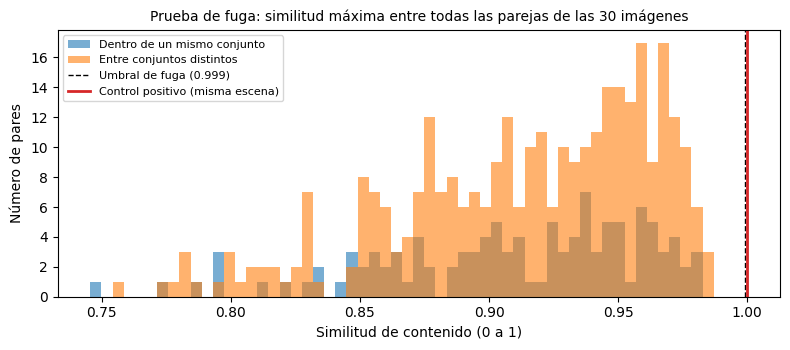

In [21]:
# 3.6.3 Verificación de fuga: contenido de todos contra todos, con control positivo
N_PAD = 512
_M = np.zeros((N_PAD, N_PAD)); _M[:256, :256] = 1
SOLAPE = np.real(np.fft.ifft2(np.fft.fft2(_M) * np.conj(np.fft.fft2(_M))))   # píxeles solapados por desplazamiento
TRANSF_8 = list(TRANSFORMACIONES.values())

def similitud_contenido(g1: np.ndarray, g2: np.ndarray, solape_min: float = 0.15):
    """Máxima similitud |Σ a·conj(b)| / n entre fasores, sobre rotaciones, volteos y desplazamientos
    con solapamiento ≥ solape_min. Vale 1 si una imagen contiene exactamente parte de la otra."""
    a0 = np.exp(1j*2*np.pi*g1/255); b0 = np.exp(1j*2*np.pi*g2/255)
    pb = np.zeros((N_PAD, N_PAD), complex); pb[:256, :256] = b0; FB = np.fft.fft2(pb)
    mejor = (0.0, 0.0)
    for t in TRANSF_8:
        pa = np.zeros((N_PAD, N_PAD), complex); pa[:256, :256] = t(a0)
        s = np.abs(np.fft.ifft2(np.fft.fft2(pa) * np.conj(FB)))
        sc = np.where(SOLAPE > solape_min * 65536, s / np.maximum(SOLAPE, 1), 0)
        k = np.unravel_index(sc.argmax(), sc.shape)
        if sc[k] > mejor[0]:
            mejor = (float(sc[k]), float(SOLAPE[k] / 65536))
    return mejor

# Control positivo: dos recortes de la misma escena (campos X=2 y X=3 de la misma adquisición)
CONTROL = leer_recorte("2021-01-28__15-49-28", 2, 4, "B"), leer_recorte("2021-01-28__15-49-28", 3, 5, "A")
sim_ctrl, sol_ctrl = similitud_contenido(*CONTROL)
print(f"Control positivo (misma escena rotada): similitud = {sim_ctrl:.4f}, solapamiento = {100*sol_ctrl:.1f} %")

conjunto_de = dict(zip(SELECCION.archivo, SELECCION.conjunto))
def _calcular_pares() -> pd.DataFrame:
    filas = []
    for a, b in itertools.combinations(SELECCION.archivo, 2):
        s, sol = similitud_contenido(IMAGENES[a], IMAGENES[b])
        filas.append({"a": a, "b": b, "conjunto_a": conjunto_de[a], "conjunto_b": conjunto_de[b],
                      "similitud": s, "solapamiento": sol})
    return pd.DataFrame(filas)

PARES = en_cache("E1_similitud_pares", _calcular_pares)
assert set(PARES.a) | set(PARES.b) == set(SELECCION.archivo), "La caché no corresponde a la selección actual"
assert (PARES.conjunto_a == PARES.a.map(conjunto_de)).all() and (PARES.conjunto_b == PARES.b.map(conjunto_de)).all()
PARES["entre_conjuntos"] = PARES.conjunto_a != PARES.conjunto_b
guardar_tabla(PARES, "E1_similitud_pares")
UMBRAL_FUGA = 0.999
entre = PARES[PARES.entre_conjuntos]
print(f"{len(PARES)} pares | entre conjuntos: {len(entre)}")
print(f"Entre conjuntos: similitud máxima = {entre.similitud.max():.4f}, percentil 95 = {entre.similitud.quantile(.95):.4f}")
n_fuga = int((entre.similitud > UMBRAL_FUGA).sum())
print(f"Pares entre conjuntos con similitud > {UMBRAL_FUGA}: {n_fuga}")
assert sim_ctrl > UMBRAL_FUGA, "El control positivo no superó el umbral: la prueba no sería confiable"
assert n_fuga == 0, "Hay pares con contenido idéntico entre conjuntos"

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(min(PARES.similitud.min(), 0.9), 1.0, 60)
ax.hist(PARES[~PARES.entre_conjuntos].similitud, bins=bins, alpha=0.6, label="Dentro de un mismo conjunto")
ax.hist(entre.similitud, bins=bins, alpha=0.6, label="Entre conjuntos distintos")
ax.axvline(UMBRAL_FUGA, color="k", ls="--", lw=1, label=f"Umbral de fuga ({UMBRAL_FUGA})")
ax.axvline(sim_ctrl, color="tab:red", lw=2, label="Control positivo (misma escena)")
ax.set_xlabel("Similitud de contenido (0 a 1)"); ax.set_ylabel("Número de pares")
ax.set_title("Prueba de fuga: similitud máxima entre todas las parejas de las 30 imágenes")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "prueba_fuga_similitud")

**Lectura de la salida (3.6).**
- La partición 12/5/5 **se reproduce exactamente** a partir de la curación y la semilla 42. Entrenamiento, validación y prueba usan **22 adquisiciones distintas para 22 imágenes**, todas del 29/01. Generalización tiene 8 imágenes de **3 adquisiciones** del 28/01.
- **0 adquisiciones compartidas** entre conjuntos, y días disjuntos entre desarrollo y generalización.
- **Prueba de contenido:**
  - El control positivo (dos recortes de la misma escena rotada) da **1,0000** con un 68,8 % de solapamiento.
  - Entre conjuntos distintos (321 pares), la similitud máxima es **0,9845** y el percentil 95 es 0,9747.
  - **Ningún par supera el umbral de 0,999.**

  El histograma muestra que la similitud entre imágenes no relacionadas es alta (0,75 a 0,985), porque dos fondos suaves se parecen sobre un 15 % de área. Lo que hace discriminante a la prueba es el **margen** entre 0,985 y el valor 1,000 que produce el contenido idéntico.

**Conclusión y alcance.** Con la regla de una adquisición por imagen, los días disjuntos y la prueba de contenido, la partición es consistente con **ausencia de fuga de información**.

**Límites:**
- La prueba detecta píxeles idénticos (copias, volteos, rotaciones, recortes solapados). No detectaría la misma escena adquirida dos veces con una reconstrucción distinta. Las adquisiciones tomadas con pocos segundos de diferencia se compararon de todos modos, y ninguna resultó ser la misma escena.
- La generalización tiene 8 imágenes pero solo **3 escenas**, y sus resultados se interpretarán así.

### 3.7 Análisis exploratorio de las imágenes seleccionadas

Análisis de las 30 imágenes que usa el proyecto: formato, distribución de grises, métricas por imagen y comparación entre conjuntos. El objetivo es comprobar que entrenamiento, validación y prueba son **comparables** entre sí, y documentar **en qué difiere** el conjunto de generalización.

In [22]:
# 3.7.1 Dimensiones, tipo de dato y rango de cada imagen seleccionada
filas = []
for r in SELECCION.itertuples():
    with Image.open(SELECTION_DIR / r.conjunto / r.archivo) as im:
        modo, tam = im.mode, im.size
    g = IMAGENES[r.archivo]
    filas.append({"conjunto": r.conjunto, "archivo": r.archivo, "modo": modo, "tamaño": f"{tam[0]}×{tam[1]}",
                  "min": int(g.min()), "max": int(g.max()), "media": round(g.mean(), 1), "desv": round(g.std(), 1),
                  "% en 0": round(100 * (g == 0).mean(), 2), "% en 255": round(100 * (g == 255).mean(), 2)})
FORMATO_SEL = pd.DataFrame(filas)
guardar_tabla(FORMATO_SEL, "E1_formato_seleccion")
print("Modos:", dict(FORMATO_SEL.modo.value_counts()), "| tamaños:", dict(FORMATO_SEL["tamaño"].value_counts()))
display(FORMATO_SEL.groupby("conjunto")[["min", "max", "media", "desv", "% en 0", "% en 255"]]
        .agg(["mean", "min", "max"]).reindex(ORDEN_CONJUNTOS).round(2))

Modos: {'L': np.int64(30)} | tamaños: {'256×256': np.int64(30)}


min            max             media                 desv  \
               mean min max   mean  min  max    mean    min    max   mean   
conjunto                                                                    
entrenamiento   0.0   0   0  255.0  255  255  121.23  107.1  144.1  50.18   
validacion      0.0   0   0  255.0  255  255  131.10  126.5  136.3  50.16   
prueba          0.0   0   0  255.0  255  255  124.26  106.6  134.9  50.18   
generalizacion  0.0   0   0  255.0  255  255  131.32   71.6  170.0  56.72   

                           % en 0             % en 255              
                 min   max   mean   min   max     mean   min   max  
conjunto                                                            
entrenamiento   40.7  56.7   0.05  0.03  0.07     0.06  0.04  0.07  
validacion      40.2  56.2   0.06  0.04  0.07     0.06  0.04  0.08  
prueba          42.5  58.5   0.07  0.04  0.09     0.06  0.03  0.09  
generalizacion  40.7  65.1   0.11  0.05  0.21     0.12  0.06  0.25

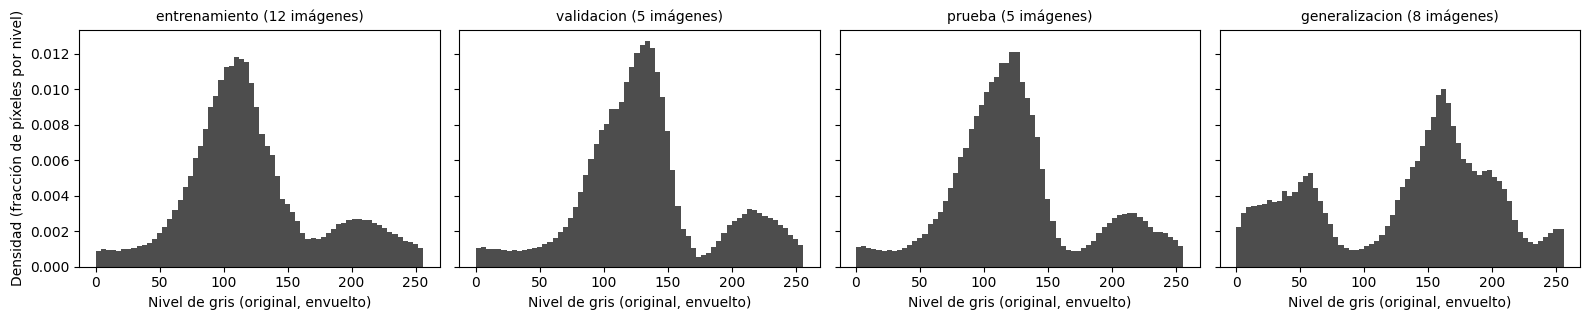

In [23]:
# 3.7.2 Histogramas de niveles de gris por conjunto
fig, ax = plt.subplots(1, 4, figsize=(16, 3.3), sharey=True)
for a, c in zip(ax, ORDEN_CONJUNTOS):
    valores = np.concatenate([IMAGENES[f].ravel() for f in SELECCION[SELECCION.conjunto == c].archivo])
    a.hist(valores, bins=64, range=(0, 256), density=True, color="0.3")
    a.set_title(f"{c} ({(SELECCION.conjunto == c).sum()} imágenes)")
    a.set_xlabel("Nivel de gris (original, envuelto)")
ax[0].set_ylabel("Densidad (fracción de píxeles por nivel)")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "histogramas_gris_por_conjunto")

,completas,cortadas,frac_cel,saltos,saltos_fondo,res_saltos,fondo_rango_ng,ruido_ng,cel_altura_ng,gris_fondo,gris_celula
conjunto,,,,,,,,,,,
entrenamiento,3.0,3.0,0.248,1120.5,0.0,0.0,77.25,13.75,137.80,110.0,197.0
validacion,4.0,3.0,0.239,1171.0,0.0,0.0,86.60,14.80,141.90,121.0,215.0
prueba,4.0,2.0,0.247,1072.0,0.0,0.0,88.30,15.00,141.00,114.0,207.0
generalizacion,2.0,2.0,0.190,822.5,1.5,0.5,86.35,10.55,135.85,159.5,74.0


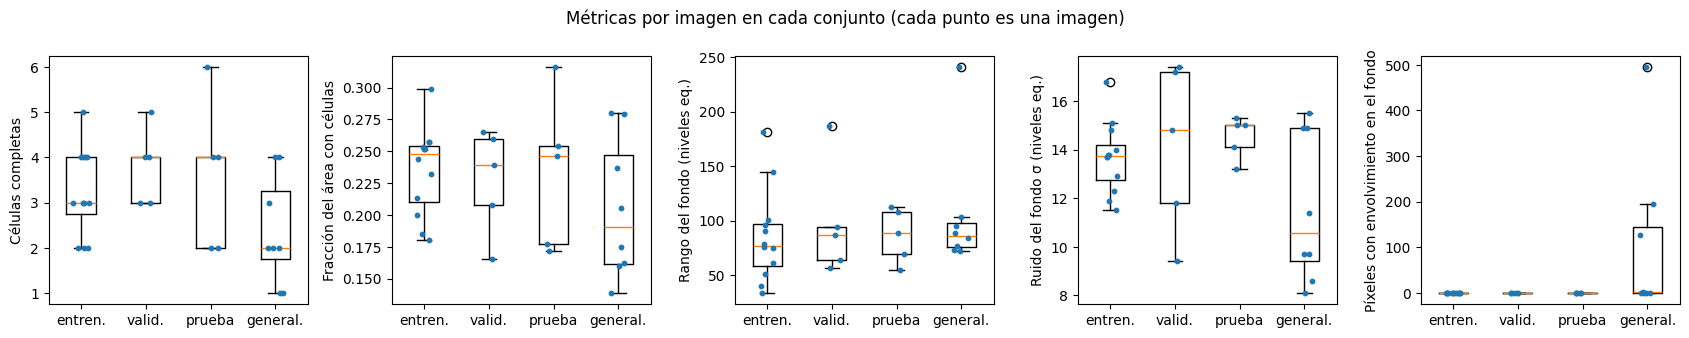

In [24]:
# 3.7.3 Métricas por imagen y comparación entre conjuntos
METRICAS_SEL = pd.DataFrame([{"conjunto": r.conjunto, "archivo": r.archivo, **metricas_recorte(IMAGENES[r.archivo])}
                             for r in SELECCION.itertuples()])
for col in ("fondo_rango", "ruido", "cel_altura"):
    METRICAS_SEL[col + "_ng"] = (METRICAS_SEL[col] * NG_POR_RAD).round(1)   # en niveles de gris equivalentes
guardar_tabla(METRICAS_SEL, "E1_metricas_seleccion")
cols = ["completas", "cortadas", "frac_cel", "saltos", "saltos_fondo", "res_saltos",
        "fondo_rango_ng", "ruido_ng", "cel_altura_ng", "gris_fondo", "gris_celula"]
display(METRICAS_SEL.groupby("conjunto")[cols].median().reindex(ORDEN_CONJUNTOS).round(3))

fig, ax = plt.subplots(1, 5, figsize=(17, 3.4))
graficas = [("completas", "Células completas"), ("frac_cel", "Fracción del área con células"),
            ("fondo_rango_ng", "Rango del fondo (niveles eq.)"), ("ruido_ng", "Ruido del fondo σ (niveles eq.)"),
            ("saltos_fondo", "Píxeles con envolvimiento en el fondo")]
for a, (col, etiqueta) in zip(ax, graficas):
    datos = [METRICAS_SEL[METRICAS_SEL.conjunto == c][col] for c in ORDEN_CONJUNTOS]
    a.boxplot(datos)
    a.set_xticks([1, 2, 3, 4], labels=["entren.", "valid.", "prueba", "general."])
    for i, v in enumerate(datos, start=1):
        a.scatter(np.full(len(v), i) + rng_e1.uniform(-0.12, 0.12, len(v)), v, s=10, color="tab:blue", zorder=3)
    a.set_ylabel(etiqueta)
fig.suptitle("Métricas por imagen en cada conjunto (cada punto es una imagen)")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "metricas_por_conjunto")

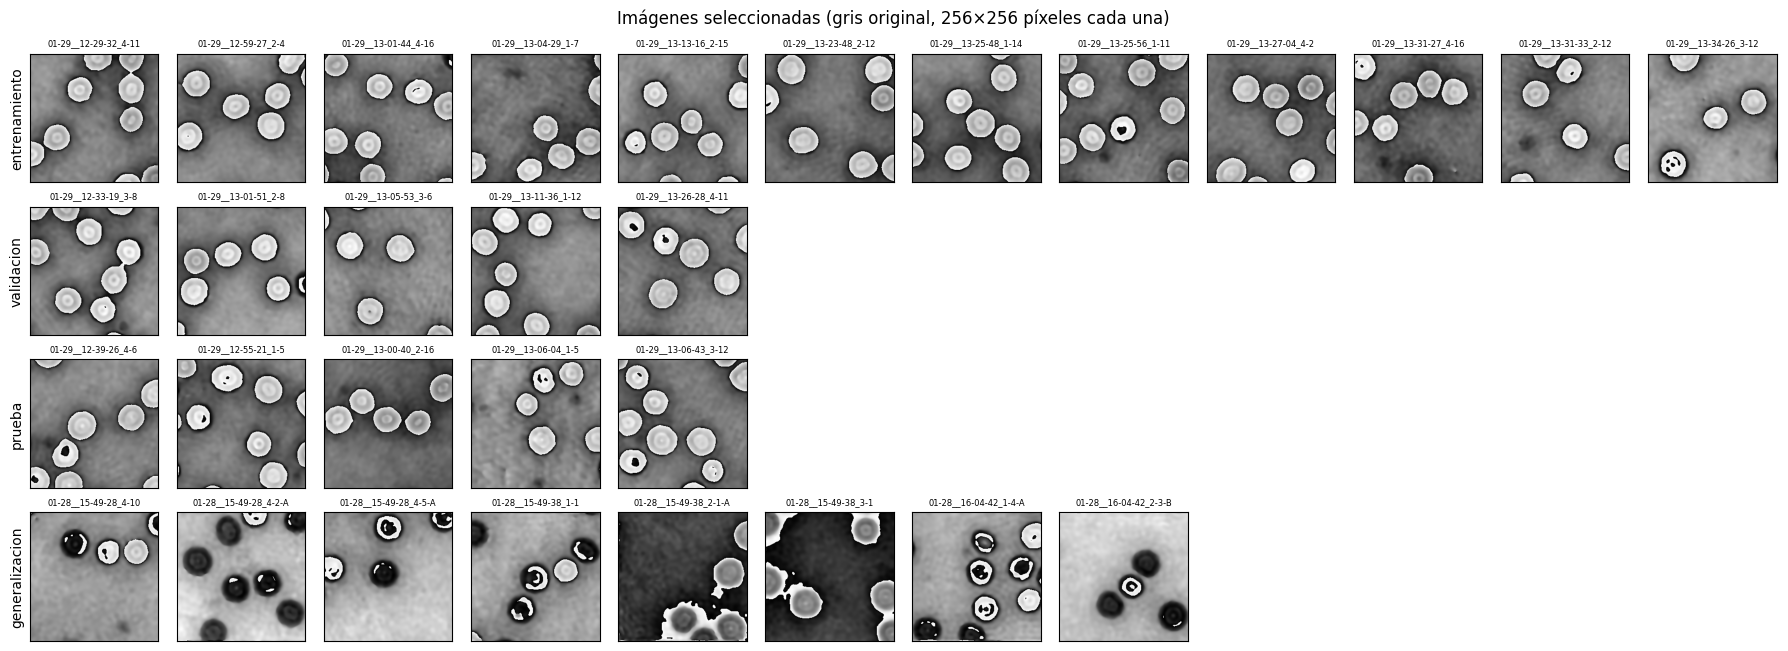

In [25]:
# 3.7.4 Las 30 imágenes seleccionadas, por conjunto
fig, ax = plt.subplots(4, 12, figsize=(18, 6.6))
for i, c in enumerate(ORDEN_CONJUNTOS):
    archivos = SELECCION[SELECCION.conjunto == c].archivo.tolist()
    for j in range(12):
        a = ax[i, j]; a.set_xticks([]); a.set_yticks([])
        if j < len(archivos):
            a.imshow(IMAGENES[archivos[j]], vmin=0, vmax=255)
            a.set_title(archivos[j].replace("Image__2021-", "").replace(".png", ""), fontsize=6)
        else:
            a.axis("off")
    ax[i, 0].set_ylabel(c, fontsize=10)
fig.suptitle("Imágenes seleccionadas (gris original, 256×256 píxeles cada una)")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "imagenes_seleccionadas")

**Lectura de la salida (3.7).**
- **Formato:** las 30 imágenes son de modo `L` y de 256×256, y todas van de 0 a 255. Los píxeles en exactamente 0 o 255 son entre el 0,05 y el 0,12 % en promedio; en datos envueltos, esos extremos son bordes de salto y no saturación.
- **Histogramas:** entrenamiento, validación y prueba tienen la misma forma, con un pico principal en ~100–140 (fondo) y una joroba en ~200–230 (células). Generalización es claramente distinta: el pico del fondo está en ~160 y hay una banda en ~0–70, que corresponde a células oscuras, envueltas con el signo opuesto en gris.
- **Métricas (medianas):**

| Métrica | Entrenamiento | Validación | Prueba | Generalización |
|---|---|---|---|---|
| Células completas | 3 | 4 | 4 | 2 |
| Fracción de células | 0,248 | 0,239 | 0,247 | 0,190 |
| Rango del fondo (niveles eq.) | 77,3 | 86,6 | 88,3 | 86,4 |
| Ruido del fondo σ (niveles eq.) | 13,8 | 14,8 | 15,0 | 10,6 |
| Altura de las células (niveles eq.) | 137,8 | 141,9 | 141,0 | 135,9 |
| Gris de las células (original) | 197 | 215 | 207 | **74** |

  Los tres conjuntos de desarrollo son **comparables**: las diferencias entre medianas, por ejemplo 77 frente a 88 en el rango del fondo, quedan dentro de la dispersión de entrenamiento (de ~33 a ~180). Con 5 imágenes por conjunto, esas medianas tienen mucha incertidumbre.
- **En qué difiere la generalización:** sobre todo en **apariencia y envolvimiento**. En 4 de las 8 imágenes las células aparecen oscuras en el gris original (mediana < 50), frente a 197–215 en desarrollo, y 3 de las 8 tienen envolvimiento en el fondo (126, 196 y 495 píxeles). También tiene menos células completas. **No** difiere en el rango del fondo lento (mediana 86 frente a 77–88). Esto importa para interpretar la sección 10: una caída de desempeño en generalización se podrá atribuir a envolvimiento y apariencia más que a un fondo más inclinado.
- **Figura 3.7.4:** confirma que el desarrollo tiene células claras y completas sobre fondo gris. La generalización muestra células oscuras, anillos envueltos y, en dos imágenes, grandes regiones del fondo envueltas.

### 3.8 ¿La fase está envuelta? (H1.6)

Para cada imagen se cuenta, **dentro de las células**, la fracción de pares de píxeles vecinos con un salto de más de 128 niveles (medio rango), y cuántos saltos quedan después de desenvolver. Se muestra un ejemplo con un corte que atraviesa una célula envuelta.

In [26]:
# 3.8.1 Saltos dentro de las células, antes y después de desenvolver
filas = []
for r in SELECCION.itertuples():
    g = IMAGENES[r.archivo]
    phi = desenvolver(g)
    _, res, s = ajuste_fondo_robusto(phi)
    cel = mascara_celulas(res, s, -1)
    par_h = cel[:, 1:] & cel[:, :-1]; par_v = cel[1:, :] & cel[:-1, :]
    salto_h = np.abs(np.diff(g, axis=1)) > 128; salto_v = np.abs(np.diff(g, axis=0)) > 128
    pares_cel = par_h.sum() + par_v.sum()
    filas.append({"conjunto": r.conjunto, "archivo": r.archivo,
                  "% pares en célula con salto": 100 * ((salto_h & par_h).sum() + (salto_v & par_v).sum()) / max(pares_cel, 1),
                  "saltos > 128 (original)": contar_saltos(g, 128),
                  "saltos > π (desenvuelta)": contar_saltos(phi, np.pi)})
ENVOLVIMIENTO = pd.DataFrame(filas)
guardar_tabla(ENVOLVIMIENTO, "E1_envolvimiento_seleccion")
display(ENVOLVIMIENTO.groupby("conjunto").median(numeric_only=True).reindex(ORDEN_CONJUNTOS).round(3))
frac_mediana = ENVOLVIMIENTO["% pares en célula con salto"].median()
H1_6 = (ENVOLVIMIENTO["% pares en célula con salto"] < 0.1).all()
print(f"Mediana del % de pares en célula con salto: {frac_mediana:.2f} %  →  H1.6 (< 0,1 %):",
      "SE CUMPLE" if H1_6 else "SE RECHAZA")

,% pares en célula con salto,saltos > 128 (original),saltos > π (desenvuelta)
conjunto,,,
entrenamiento,4.008,1323.0,0.0
validacion,3.985,1366.0,0.0
prueba,4.328,1277.0,0.0
generalizacion,2.652,947.5,0.5


Mediana del % de pares en célula con salto: 4.01 %  →  H1.6 (< 0,1 %): SE RECHAZA


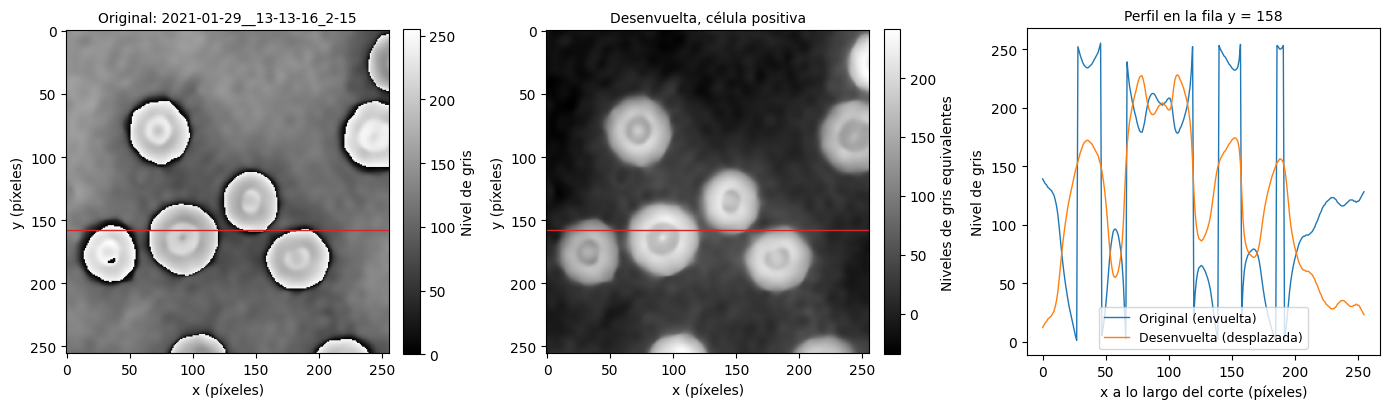

In [27]:
# 3.8.2 Ejemplo: corte que atraviesa una célula envuelta, antes y después de desenvolver
fila_ej = ENVOLVIMIENTO[ENVOLVIMIENTO.conjunto == "entrenamiento"].sort_values(
    "% pares en célula con salto", ascending=False).iloc[0]
g = IMAGENES[fila_ej.archivo]
u = -desenvolver(g) * NG_POR_RAD                      # célula positiva, en niveles de gris equivalentes
y0 = int(np.argmax((np.abs(np.diff(g, axis=1)) > 128).sum(axis=1)))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
im0 = ax[0].imshow(g, vmin=0, vmax=255); ax[0].axhline(y0, color="tab:red", lw=1)
ax[0].set_title(f"Original: {fila_ej.archivo[7:-4]}"); barra_color(im0, ax[0], "Nivel de gris")
im1 = ax[1].imshow(u); ax[1].axhline(y0, color="tab:red", lw=1)
ax[1].set_title("Desenvuelta, célula positiva"); barra_color(im1, ax[1], "Niveles de gris equivalentes")
for a in ax[:2]:
    a.set_xlabel("x (píxeles)"); a.set_ylabel("y (píxeles)")
ax[2].plot(g[y0], lw=1, label="Original (envuelta)")
ax[2].plot(u[y0] - np.median(u[y0]) + np.median(g[y0]), lw=1, label="Desenvuelta (desplazada)")
ax[2].set_xlabel("x a lo largo del corte (píxeles)"); ax[2].set_ylabel("Nivel de gris")
ax[2].set_title(f"Perfil en la fila y = {y0}"); ax[2].legend()
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "celula_envuelta_perfil")

**Lectura de la salida (3.8).**
- **H1.6 se rechaza:** dentro de las células, la mediana de pares vecinos con un salto de más de 128 niveles es el **4,0 %** (4,0 % en entrenamiento, 4,0 % en validación, 4,3 % en prueba y 2,7 % en generalización), muy por encima del 0,1 % fijado. Las células **sí están envueltas**.
- Tras desenvolver no queda ningún salto mayor que $\pi$ en las imágenes de desarrollo (mediana 0); en generalización la mediana es 0,5. El desenvolvimiento resuelve el envolvimiento en las imágenes seleccionadas.
- **Ejemplo (`13-13-16_2-15`, entrenamiento):** en el corte original los valores saltan bruscamente entre ~0 y ~255 dentro y en el borde de las células. El perfil desenvuelto es continuo: el fondo queda en ~10–35 niveles equivalentes y las células suben a ~150–230 con una **depresión central**, la forma de dona que predice la proposición 1 para un eritrocito bicóncavo.

**Consecuencia.** Los centros negros de las imágenes originales son envolvimiento, **no** morfología. Desenvolver es un paso obligatorio del preprocesamiento.

### 3.9 Caracterización del fondo (H1.7)

> **Definición 3 (componente lenta del fondo y ruido).** Sea $\hat b$ el fondo polinomial de grado 2 ajustado de forma robusta (3.5) sobre la fase desenvuelta. Se define $\sigma_{\text{fondo}} = \operatorname{desv}(\hat b)$ sobre toda la imagen (cuánto varía el fondo lento) y $\sigma_{\text{ruido}} = 1{,}4826\,\mathrm{MAD}$ del residuo en los píxeles de fondo (cuánto fluctúa alrededor de esa superficie). Si $\sigma_{\text{fondo}}/\sigma_{\text{ruido}} > 2$, el fondo tiene una estructura lenta claramente mayor que el ruido: es lo que el modelo debe estimar y restar.

In [28]:
# 3.9.1 Componente lenta del fondo frente al ruido
filas = []
for r in SELECCION.itertuples():
    fondo, res, s = ajuste_fondo_robusto(desenvolver(IMAGENES[r.archivo]))
    filas.append({"conjunto": r.conjunto, "archivo": r.archivo,
                  "σ_fondo (niveles eq.)": fondo.std() * NG_POR_RAD, "σ_ruido (niveles eq.)": s * NG_POR_RAD,
                  "razón": fondo.std() / s})
FONDO = pd.DataFrame(filas)
guardar_tabla(FONDO, "E1_fondo_vs_ruido")
columnas_fondo = ["σ_fondo (niveles eq.)", "σ_ruido (niveles eq.)", "razón"]
display(FONDO.groupby("conjunto")[columnas_fondo].agg(["median", "min", "max"]).reindex(ORDEN_CONJUNTOS).round(2))
frac_mayor_2 = (FONDO["razón"] > 2).mean()
H1_7 = frac_mayor_2 > 0.5
print(f"Imágenes con σ_fondo/σ_ruido > 2: {100*frac_mayor_2:.0f} %  →  H1.7:", "SE CUMPLE" if H1_7 else "NO SE CUMPLE")

σ_fondo (niveles eq.)               σ_ruido (niveles eq.)  \
                              median    min    max                median   
conjunto                                                                   
entrenamiento                  16.15   7.97  31.59                 13.72   
validacion                     17.50   9.71  35.02                 14.78   
prueba                         14.70  11.45  17.92                 14.96   
generalizacion                 16.08  12.81  44.57                 10.56   

                              razón              
                  min    max median   min   max  
conjunto                                         
entrenamiento   11.50  16.85   1.13  0.48  2.35  
validacion       9.39  17.40   1.01  0.66  3.73  
prueba          13.21  15.26   1.04  0.77  1.36  
generalizacion   8.10  15.51   1.68  0.89  4.57

Imágenes con σ_fondo/σ_ruido > 2: 17 %  →  H1.7: NO SE CUMPLE


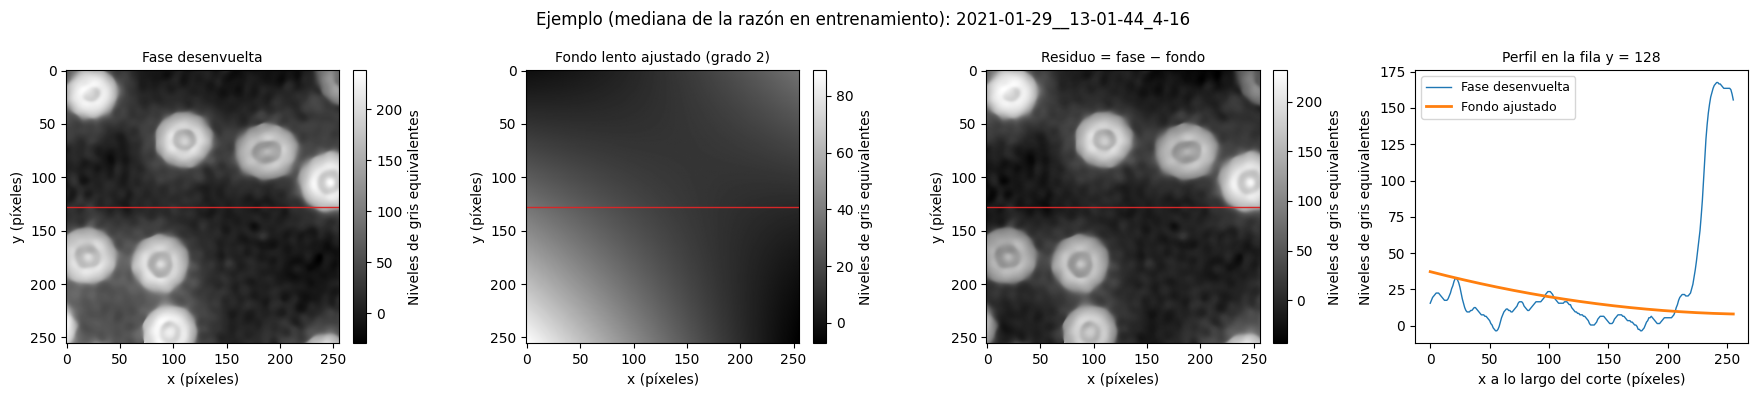

In [29]:
# 3.9.2 Ejemplo: fase desenvuelta, fondo lento ajustado y residuo, con un perfil
archivo_ej = FONDO[FONDO.conjunto == "entrenamiento"].sort_values("razón").iloc[len(FONDO[FONDO.conjunto == "entrenamiento"]) // 2].archivo
u = -desenvolver(IMAGENES[archivo_ej]) * NG_POR_RAD
fondo, res, s = ajuste_fondo_robusto(u)
y0 = 128
fig, ax = plt.subplots(1, 4, figsize=(18, 4.0))
for a, img, titulo in zip(ax[:3], (u, fondo, res), ("Fase desenvuelta", "Fondo lento ajustado (grado 2)", "Residuo = fase − fondo")):
    im = a.imshow(img); a.axhline(y0, color="tab:red", lw=1); a.set_title(titulo)
    a.set_xlabel("x (píxeles)"); a.set_ylabel("y (píxeles)"); barra_color(im, a, "Niveles de gris equivalentes")
ax[3].plot(u[y0], lw=1, label="Fase desenvuelta")
ax[3].plot(fondo[y0], lw=2, label="Fondo ajustado")
ax[3].set_xlabel("x a lo largo del corte (píxeles)"); ax[3].set_ylabel("Niveles de gris equivalentes")
ax[3].set_title(f"Perfil en la fila y = {y0}"); ax[3].legend()
fig.suptitle(f"Ejemplo (mediana de la razón en entrenamiento): {archivo_ej[7:-4]}")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "fondo_lento_ejemplo")

**Lectura de la salida (3.9).**
- **H1.7 se rechaza:** solo el **17 %** de las 30 imágenes tiene $\sigma_{\text{fondo}}/\sigma_{\text{ruido}} > 2$. La razón mediana es 1,13 en entrenamiento, 1,01 en validación, 1,04 en prueba y 1,68 en generalización.
- En desarrollo, la **componente lenta** del fondo tiene $\sigma_{\text{fondo}}$ de **15 a 17,5 niveles equivalentes** (≈ 0,36–0,43 rad), y la fluctuación que la superficie de grado 2 no captura tiene $\sigma_{\text{ruido}}$ de **13,7 a 15,0 niveles** (≈ 0,34–0,37 rad). Las dos son del mismo orden.
- **Ejemplo (`13-01-44_4-16`):** el fondo lento es una pendiente suave (en la fila 128 baja de ~37 a ~8 niveles a lo ancho del recorte), y encima hay una **textura ondulada** de ±10–15 niveles con periodos de unos 20 a 40 píxeles. Con estos datos no se puede atribuir esa textura a una causa concreta (ruido coherente, franjas residuales u otra).

**Consecuencias.** Este resultado no estaba previsto y cambia lo que es realista esperar del modelo:
1. Dentro de un recorte de 256×256 (~37 µm) la aberración es moderada. La parte del fondo que un modelo **suave** puede quitar es del mismo tamaño que la que no puede quitar. A modo ilustrativo, si ambas componentes fueran independientes, la desviación total del fondo en entrenamiento sería $\sqrt{16{,}2^2 + 13{,}7^2} \approx 21{,}2$ niveles y al quitar solo la parte lenta quedaría en ≈ 13,7: una reducción de ≈ 35 %.
2. "Fondo negro" significará, en la práctica, **media del fondo ≈ 0 y desviación del fondo ≈ $\sigma_{\text{ruido}}$**, no desviación 0. $\sigma_{\text{ruido}}$ será el **piso de referencia** en la evaluación.
3. Quitar también la textura exigiría un modelo más flexible, y la textura tiene una escala parecida a la de los detalles de la célula (una célula mide ~50 px). Ese **compromiso entre limpiar el fondo y preservar la célula** será la pregunta central de la etapa E3.

### 3.10 Máscaras de referencia célula / fondo (independientes del modelo)

Las métricas de la sección 6 necesitan saber qué píxeles son célula y cuáles fondo. Esa división **no puede salir del modelo que se evalúa**, porque entonces el modelo se calificaría a sí mismo. Se usan máscaras de referencia fijas, calculadas una sola vez a partir de la imagen original:

- **Célula:** la máscara de 3.5 (residuo $> 4\hat\sigma$ respecto al fondo polinomial robusto, apertura y relleno de huecos).
- **Fondo:** los píxeles a más de 6 px de cualquier célula. La franja intermedia (borde de la célula y halo) se excluye de ambas regiones, porque allí la asignación es ambigua.

Limitación: las máscaras dependen de un ajuste polinomial, igual que la línea base de la sección 5. Para no favorecerla, las métricas se calcularán **solo** como medias dentro de cada región, y la franja ambigua queda fuera. Se revisan visualmente abajo.

,% célula,% fondo,% excluido
conjunto,,,
entrenamiento,24.8,66.4,8.6
validacion,23.9,67.3,8.8
prueba,24.7,67.1,8.2
generalizacion,19.0,74.4,7.0


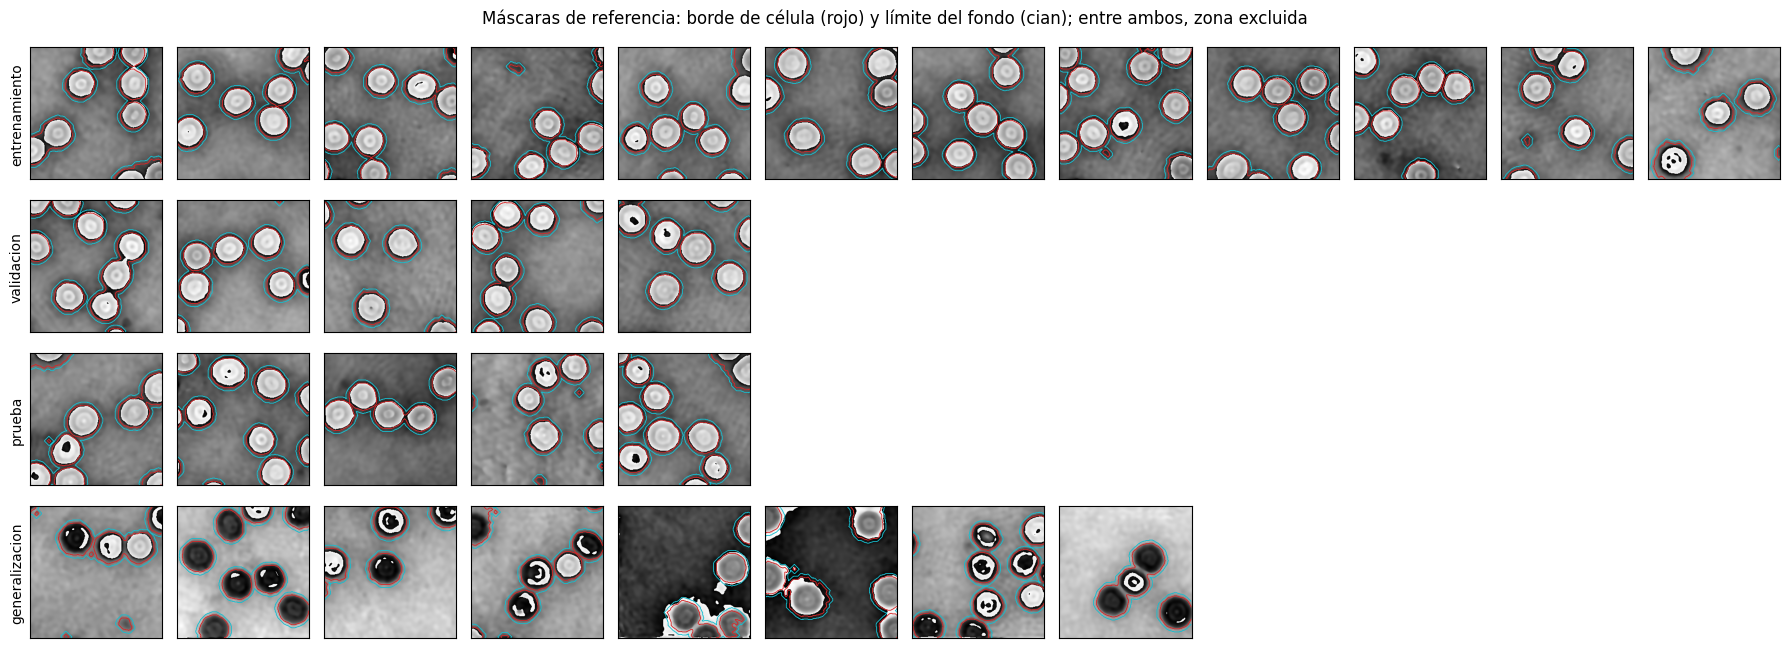

In [30]:
# 3.10.1 Construcción de las máscaras y revisión visual
def mascaras_referencia(g: np.ndarray, margen: int = 6):
    """Máscaras de referencia (célula, fondo) a partir del gris original; independientes de cualquier modelo."""
    _, res, s = ajuste_fondo_robusto(desenvolver(g))
    cel = mascara_celulas(res, s, -1)
    fondo = ~ndi.binary_dilation(cel, iterations=margen)
    return cel, fondo

MASCARAS = {f: mascaras_referencia(g) for f, g in IMAGENES.items()}
tabla_mask = pd.DataFrame([{"conjunto": conjunto_de[f], "archivo": f, "% célula": 100*c.mean(), "% fondo": 100*b.mean(),
                            "% excluido": 100*(1 - c.mean() - b.mean())} for f, (c, b) in MASCARAS.items()])
guardar_tabla(tabla_mask, "E1_mascaras_referencia")
display(tabla_mask.groupby("conjunto").median(numeric_only=True).reindex(ORDEN_CONJUNTOS).round(1))

fig, ax = plt.subplots(4, 12, figsize=(18, 6.6))
for i, c in enumerate(ORDEN_CONJUNTOS):
    archivos = SELECCION[SELECCION.conjunto == c].archivo.tolist()
    for j in range(12):
        a = ax[i, j]; a.set_xticks([]); a.set_yticks([])
        if j < len(archivos):
            cel, fon = MASCARAS[archivos[j]]
            a.imshow(IMAGENES[archivos[j]], vmin=0, vmax=255)
            a.contour(cel, levels=[0.5], colors="tab:red", linewidths=0.6)
            a.contour(fon, levels=[0.5], colors="tab:cyan", linewidths=0.6)
        else:
            a.axis("off")
    ax[i, 0].set_ylabel(c, fontsize=10)
fig.suptitle("Máscaras de referencia: borde de célula (rojo) y límite del fondo (cian); entre ambos, zona excluida")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "mascaras_referencia")

**Lectura de la salida (3.10).**
- En desarrollo, las máscaras marcan como célula el **24–25 %** del área, como fondo el **66–67 %** y excluyen una franja del **8–9 %** (borde de la célula y halo). En generalización: 19 %, 74 % y 7 %.
- **Revisión visual:** los contornos rojos siguen el borde de las células en todas las imágenes de desarrollo, incluidas las células cortadas por el borde del recorte. En generalización siguen también a las células que en el gris original aparecen oscuras o con anillos envueltos.
- **Limitaciones:**
  - En algunas imágenes aparecen **regiones pequeñas** (del orden de 10 píxeles de lado) marcadas como célula sobre manchas oscuras del fondo. Son pocas y pequeñas frente a una célula (~2.000 píxeles), así que su efecto sobre medianas es pequeño, pero existe. Una mejora posible es descartar las regiones de menos de ~300 píxeles.
  - Las máscaras dependen de un umbral sobre el ajuste polinomial; no son una segmentación manual.

Las máscaras quedan **fijas** y se usan igual para todos los métodos que se comparen.

### 3.11 Preprocesamiento y su justificación

> **Definición 4 (imagen preprocesada).** Para un gris envuelto $g$:
> $$u(x,y) = -\,\frac{255}{2\pi}\;\mathcal{U}\!\left(\frac{2\pi\,g}{255} - \pi\right),$$
> donde $\mathcal U$ es el desenvolvimiento (3.4). Las unidades de $u$ son **niveles de gris equivalentes**: un nivel de $u$ equivale a un nivel del PNG original, pero ya sin el límite 0–255.

| Paso | Por qué | Evidencia |
|---|---|---|
| Desenvolver | Sin desenvolver, ni el fondo es suave ni la célula se suma al fondo: el modelo $\varphi_{\text{obs}} = \varphi_{\text{cel}} + b$ no se cumple | 3.4, 3.8 |
| Cambiar el signo | En este dataset las células quedan por debajo del fondo; con el signo invertido quedan por encima, como indica la proposición 1 | 3.5 (`signo`) |
| Expresar en niveles de gris equivalentes | Conserva la escala de las imágenes originales (indicación del profesor) y permite convertir a radianes bajo la hipótesis de 3.4 | 3.4 |

No se normaliza ni se recorta aquí: la normalización depende del modelo y se define en las secciones 7 y 8. Tampoco se resta ningún fondo: eso es lo que tiene que hacer el modelo.

,min,max,rango,saltos > 128 restantes
conjunto,,,,
entrenamiento,-28.5,242.0,267.5,0.0
validacion,-41.5,232.5,275.0,0.0
prueba,-21.5,225.5,263.0,0.0
generalizacion,-89.0,198.5,320.0,0.5


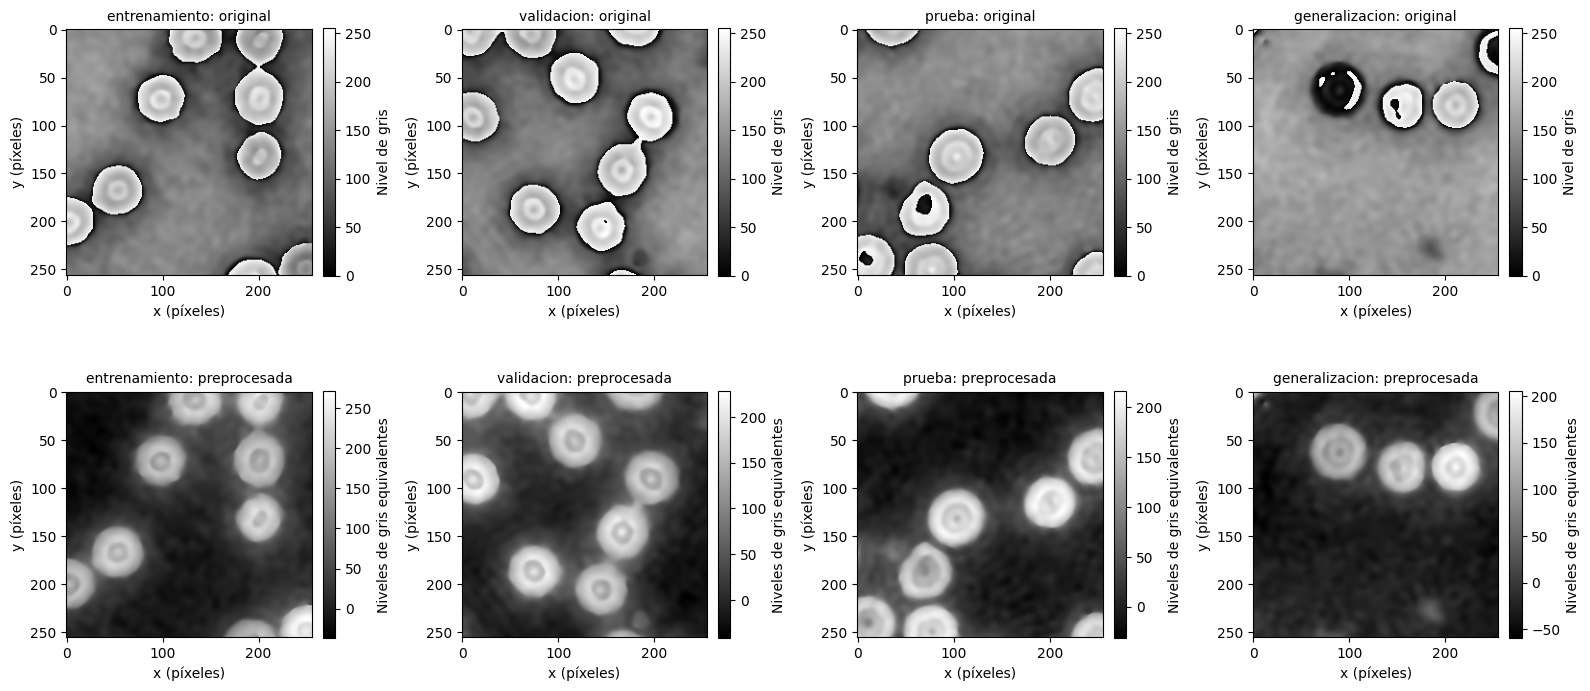

In [31]:
# 3.11.1 Preprocesamiento de las 30 imágenes
def preprocesar(g: np.ndarray) -> np.ndarray:
    """Gris envuelto (0–255) -> fase desenvuelta con la célula positiva, en niveles de gris equivalentes."""
    return -desenvolver(g) * NG_POR_RAD

assert (METRICAS_SEL.signo == -1).all(), "Alguna imagen seleccionada tiene la convención de signo opuesta"
PREPROCESADAS = {f: preprocesar(g) for f, g in IMAGENES.items()}
tabla_pre = pd.DataFrame([{"conjunto": conjunto_de[f], "min": u.min(), "max": u.max(), "rango": u.max() - u.min(),
                           "saltos > 128 restantes": contar_saltos(u, 128)} for f, u in PREPROCESADAS.items()])
display(tabla_pre.groupby("conjunto").median().reindex(ORDEN_CONJUNTOS).round(1))

fig, ax = plt.subplots(2, 4, figsize=(16, 7.4))
for j, c in enumerate(ORDEN_CONJUNTOS):
    f = SELECCION[SELECCION.conjunto == c].archivo.iloc[0]
    im0 = ax[0, j].imshow(IMAGENES[f], vmin=0, vmax=255); ax[0, j].set_title(f"{c}: original")
    barra_color(im0, ax[0, j], "Nivel de gris")
    im1 = ax[1, j].imshow(PREPROCESADAS[f]); ax[1, j].set_title(f"{c}: preprocesada")
    barra_color(im1, ax[1, j], "Niveles de gris equivalentes")
    for a in ax[:, j]:
        a.set_xlabel("x (píxeles)"); a.set_ylabel("y (píxeles)")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E1", "preprocesamiento_ejemplos")

**Lectura de la salida (3.11).**
- Tras el preprocesamiento no queda ningún salto mayor que 128 niveles en las imágenes de desarrollo (mediana 0). En generalización la mediana es 0,5: algunas imágenes conservan discontinuidades que el desenvolvimiento no resolvió.
- El rango de valores es de **263 a 275 niveles equivalentes** en desarrollo (≈ 6,5–6,8 rad) y de 320 en generalización. Supera 0–255 porque la fase ya no está envuelta, y los mínimos son negativos (−21 a −42 en desarrollo, −89 en generalización).
- **Figura:** las células aparecen **claras y positivas, con forma de dona**, sobre un fondo oscuro. Pero el fondo **no está en cero**: su nivel depende de la referencia arbitraria del desenvolvimiento y conserva la pendiente y la textura de 3.9. Eso es exactamente lo que debe estimar y restar el modelo.

**Verificación: desenvolver no altera el dato medido.**

> **Propiedad (reversibilidad del desenvolvimiento).** Sea $\psi$ la fase envuelta y $\varphi = \mathcal U(\psi)$ la desenvuelta. Si en cada píxel $\varphi(p) - \psi(p) = 2\pi\,k(p)$ con $k(p) \in \mathbb Z$, entonces $\mathcal W(\varphi) = \psi$, donde $\mathcal W(x) = \arg e^{ix} \in (-\pi, \pi]$ es la operación de envolver.
>
> *Prueba.* $e^{i\varphi(p)} = e^{i\psi(p)}\, e^{i 2\pi k(p)} = e^{i\psi(p)}$, porque $e^{i2\pi k} = 1$ para todo entero $k$. $\blacksquare$

Es decir, la fase envuelta, y con ella el gris original, se recupera exactamente de la desenvuelta. Desenvolver no inventa ni borra datos: solo decide **cuántas vueltas** $k(p)$ sumar en cada píxel.

**Criterio, fijado antes de ejecutar:** $\max_p \lvert k(p) - \operatorname{round}(k(p))\rvert < 10^{-9}$ en las 30 imágenes.

**Lo que esta verificación no cubre:**
- *Contar mal las vueltas.* El resultado seguiría siendo reversible, pero tendría un escalón falso de $2\pi$, como el de SPINR en 4.5. Ese riesgo lo miden los saltos mayores que $\pi$ que quedan tras desenvolver (columna de la tabla, también en 3.4 y 3.8).
- *La información perdida antes del PNG.* La cuantización (1 nivel ≈ 0,0246 rad) y la **condición de Itoh**: si la fase verdadera cambia más de $\pi$ entre dos píxeles vecinos, ningún algoritmo puede saber cuántas vueltas hubo entre ellos.

In [32]:
# 3.11.2 Verificación: el desenvolvimiento solo suma múltiplos enteros de 2π (no altera el dato medido)
filas = []
for f, g in IMAGENES.items():
    psi = gris_a_fase_envuelta(g)                 # fase envuelta medida (rad)
    phi = desenvolver(g)                          # fase desenvuelta (rad)
    k = (phi - psi) / (2 * np.pi)                 # vueltas sumadas en cada píxel
    filas.append({"conjunto": conjunto_de[f], "archivo": f,
                  "máx |k − round(k)|": float(np.abs(k - np.round(k)).max()),
                  "vueltas mín": int(np.round(k).min()), "vueltas máx": int(np.round(k).max()),
                  "saltos > π tras desenvolver": contar_saltos(phi, np.pi)})
VERIF_UNW = pd.DataFrame(filas)
guardar_tabla(VERIF_UNW, "E1_verificacion_desenvolvimiento")
display(VERIF_UNW.groupby("conjunto").agg({"máx |k − round(k)|": "max", "vueltas mín": "min", "vueltas máx": "max",
                                           "saltos > π tras desenvolver": "max"}).reindex(ORDEN_CONJUNTOS))
assert (VERIF_UNW["máx |k − round(k)|"] < 1e-9).all(), "Algún píxel no difiere de la fase envuelta en un número entero de vueltas"
print("El desenvolvimiento solo sumó vueltas enteras en las 30 imágenes: la imagen original se recupera exactamente.")

,máx |k − round(k)|,vueltas mín,vueltas máx,saltos > π tras desenvolver
conjunto,,,,
entrenamiento,0.000000e+00,-1,0,2
validacion,0.000000e+00,-1,0,0
prueba,0.000000e+00,-1,0,0
generalizacion,2.220446e-16,-2,1,13


El desenvolvimiento solo sumó vueltas enteras en las 30 imágenes: la imagen original se recupera exactamente.


**Lectura de la salida (3.11.2).**
- **La propiedad se cumple en las 30 imágenes.** La parte no entera de $k$ es 0 en desarrollo y $2{,}2 \times 10^{-16}$ (redondeo numérico) en generalización. La imagen original se recupera exactamente: desenvolver no alteró ningún dato medido.
- **Vueltas sumadas.** En desarrollo, $k \in \{-1, 0\}$: como mucho una vuelta. Es consistente con los rangos de 263–275 niveles de 3.11.1, apenas por encima de una vuelta (255 niveles). En generalización, $k$ va de −2 a 1, consistente con su rango de 320 niveles.
- **Saltos que quedan** (el riesgo de contar mal las vueltas):
  - como máximo 2 en entrenamiento, consistente con los 2 que `unwrap_phase` dejó en `12-29-32_4-11` (4.6);
  - 0 en validación y prueba;
  - hasta 13 en generalización, consistente con la mediana de 0,5 de 3.11.1.

  Frente a 130.560 pares de vecinos por imagen, es como mucho un 0,01 %. En la sección 10 se revisará si caen sobre células.

### 3.12 Contraste de las hipótesis de la etapa

**Resumen** (tabla de la celda siguiente): 5 hipótesis se cumplen (H1.1, H1.2, H1.4, H1.8, H1.9), 3 se rechazan (H1.3, H1.6, H1.7) y 1 se reformula (H1.5).

**Qué se puede concluir y qué no:**

| Hallazgo | Se puede concluir | No se puede concluir |
|---|---|---|
| Estructura del dataset (H1.2, H1.4, H1.9) | Los recortes de una misma adquisición comparten contenido; la partición original tiene fuga | — |
| Mosaico (H1.3) | El 90 % de los campos es continuo | Por qué el 10 % restante no lo es |
| Escala de grises (H1.5) | Los datos son **consistentes** con fase envuelta escalada linealmente | La escala absoluta en radianes: no hay calibración |
| Envolvimiento (H1.6) | Las células están envueltas y el desenvolvimiento lo resuelve en las imágenes de desarrollo | Que el desenvolvimiento sea correcto en todas las imágenes del dataset: solo el 44 % de los candidatos quedó limpio |
| Fondo (H1.7) | En recortes de 256×256 la componente lenta es del mismo orden que la textura del fondo | Que la textura sea ruido puro: su origen no se determinó |

**Consecuencias para las etapas siguientes:**
1. **Partición por adquisición:** ya aplicada (3.6).
2. **Desenvolver y cambiar el signo:** forman parte del preprocesamiento (3.11). En generalización pueden quedar errores de desenvolvimiento, y eso se tendrá en cuenta al interpretar la sección 10.
3. **Unidades:** se trabaja en niveles de gris equivalentes; la conversión a radianes queda condicionada a H1.5.
4. **Metas realistas:** media del fondo → 0 y desviación del fondo → $\sigma_{\text{ruido}}$ (3.9). El compromiso entre flexibilidad del modelo y preservación de la célula será el eje de la etapa E3.
5. **Limitaciones heredadas:** máscaras por umbral, conjunto de desarrollo curado visualmente (más limpio que el promedio) y generalización con solo 3 escenas.

In [33]:
# 3.12 Resumen automático del contraste de hipótesis
def estado(cumple: bool) -> str:
    return "Se cumple" if cumple else "Se rechaza"

contraste = pd.DataFrame([
    ("H1.1", "PNG de 8 bits, un canal, 256×256", estado(H1_1), "3.2"),
    ("H1.2", "-A/-B son volteos exactos; 12.288 recortes distintos", estado(H1_2), "3.3"),
    ("H1.3", "16 recortes forman un mosaico continuo de 1024×1024 (≥ 95 % de los campos)", estado(H1_3), "3.3"),
    ("H1.4", "La partición original comparte recortes", estado(H1_4), "3.3"),
    ("H1.5", "Escala 0–255 normalizada por campo",
     "Reformulada: los datos son consistentes con gris = fase envuelta escalada; el criterio original no aplica", "3.4"),
    ("H1.6", "La fase no está envuelta dentro de las células", estado(H1_6), "3.8"),
    ("H1.7", "Fondo lento mayor que el ruido (razón > 2 en la mayoría)", estado(H1_7), "3.9"),
    ("H1.8", "Variabilidad de calidad del fondo suficiente", estado(H1_8), "3.5"),
    ("H1.9", "Los 4 campos son la misma escena rotada", estado(H1_9), "3.3"),
], columns=["ID", "Hipótesis", "Resultado", "Sección"])
guardar_tabla(contraste, "E1_contraste_hipotesis")
contraste

,ID,Hipótesis,Resultado,Sección
0,H1.1,"PNG de 8 bits, un canal, 256×256",Se cumple,3.2
1,H1.2,-A/-B son volteos exactos; 12.288 recortes dis...,Se cumple,3.3
2,H1.3,16 recortes forman un mosaico continuo de 1024...,Se rechaza,3.3
3,H1.4,La partición original comparte recortes,Se cumple,3.3
4,H1.5,Escala 0–255 normalizada por campo,Reformulada: los datos son consistentes con gr...,3.4
5,H1.6,La fase no está envuelta dentro de las células,Se rechaza,3.8
6,H1.7,Fondo lento mayor que el ruido (razón > 2 en l...,Se rechaza,3.9
7,H1.8,Variabilidad de calidad del fondo suficiente,Se cumple,3.5
8,H1.9,Los 4 campos son la misma escena rotada,Se cumple,3.3


## 4. Fundamentos y formulación física  *(lineamiento B · objetivo específico 1 · etapa E2)*

Esta sección cubre el objetivo específico 1: los fundamentos de las representaciones neuronales implícitas (4.1), el modelo físico del problema (4.2) y su traducción a funciones de pérdida (4.3). Después se incorpora el código guía del curso (4.4), se verifica con su propio ejemplo sintético (4.5) y se aplica a imágenes reales (4.6), para saber qué parte sirve y qué hay que construir.

### 4.0 Hipótesis de la etapa E2 (fijadas antes de ejecutar)

Las métricas de 4.6 son **preliminares**: las definitivas se formalizan en la sección 6. Se calculan sobre las máscaras fijas de 3.10 y en niveles de gris equivalentes:
- $\mu_B$, $\sigma_B$: media y desviación de la imagen en la región de fondo;
- $h_C = \operatorname{mediana}(\text{célula}) - \operatorname{mediana}(\text{fondo})$: altura de la célula sobre el fondo;
- $\Delta h_C$: cambio relativo de $h_C$ respecto a la imagen preprocesada.

| ID | Hipótesis | Criterio de aceptación | Sección |
|---|---|---|---|
| H2.1 | El desenvolvimiento SPINR del código guía recupera la fase sintética de `main.py` | RMS (tras igualar medias) ≤ 0,3 rad, es decir, 3 veces el ruido simulado ($\sigma = 0{,}1$ rad) | 4.5 |
| H2.2 | `unwrap_phase` (Herráez et al., 2002) también la recupera y es mucho más rápido | RMS ≤ 0,3 rad y tiempo al menos 100 veces menor que SPINR | 4.5 |
| H2.3 | El RMS final que imprime `main.py` no mide la separación del fondo: compara la fase compensada (sin su parte de bajo orden) con la fase verdadera completa | RMS final > 2 × RMS del desenvolvimiento SPINR | 4.5 |
| H2.4 | En imágenes reales, SPINR y `unwrap_phase` dan la misma fase desenvuelta | RMS de su diferencia (sin la constante) < 0,2 rad en las dos imágenes, y SPINR no deja más saltos residuales | 4.6 |
| H2.5 | `compensate_background` (SIREN de baja frecuencia) quita la componente lenta sin alterar la célula | $\sigma_B \le 1{,}1\,\sigma_{\text{ruido}}$ (3.9) y $\lvert\Delta h_C\rvert < 5\,\%$ en las dos imágenes | 4.6 |
| H2.6 | `compensate_background_zernike` (15 términos, ajuste robusto) logra lo mismo | Mismo criterio que H2.5 | 4.6 |
| H2.7 | `extract_sample_phase` encuentra las células | Dice ≥ 0,8 con la máscara de referencia en las dos imágenes | 4.6 |

### 4.1 Representaciones neuronales implícitas: SIREN y características de Fourier

> **Definición 5 (representación neuronal implícita, INR).** Una imagen se representa como una función continua $f_\theta : [-1,1]^2 \to \mathbb{R}$, dada por una red neuronal cuya **entrada son las coordenadas** $(x, y)$ de un píxel y cuya salida es el valor en ese píxel. Para obtener la imagen completa se evalúa la red en las coordenadas de todos los píxeles.

Las redes con activación ReLU tienen **sesgo espectral**: aprenden con facilidad las variaciones lentas y casi no capturan las rápidas (Tancik et al., 2020). Hay dos soluciones clásicas, y ambas controlan **cuánto detalle** puede representar la red.

> **Definición 6 (SIREN; Sitzmann et al., 2020).** Cada capa oculta aplica $h_{l+1} = \sin\big(\omega_0\,(W_l h_l + b_l)\big)$ y la salida es lineal. Los pesos se inicializan así: en la primera capa, $W_0 \sim \mathcal{U}(-1/n,\, 1/n)$; en las demás, $W_l \sim \mathcal{U}\big(-\sqrt{6/n}/\omega_0,\; \sqrt{6/n}/\omega_0\big)$, con $n$ el número de entradas de la capa. Esta inicialización mantiene la distribución de las activaciones estable a través de las capas, y la derivada de una SIREN es otra SIREN, lo que la hace útil para problemas con derivadas.

> **Proposición 2 (ancho de banda de la primera capa).** Con coordenadas en $[-1,1]$ y $n = 2$ entradas, los pesos de la primera capa cumplen $|w_1|, |w_2| \le \tfrac12$. El argumento del seno, $\omega_0(w_1 x + w_2 y + b)$, varía como mucho $\omega_0 \cdot 2\,(|w_1| + |w_2|) \le 2\,\omega_0$ radianes de un extremo al otro de la imagen. El sesgo $b$ solo desplaza el seno.

| $\omega_0$ | Variación máxima del argumento | Periodos a lo ancho de la imagen | Uso |
|---|---|---|---|
| 1 | 2 rad | 0,32 | Red de fondo del código guía (`LowFreqBackgroundNetwork`) |
| 10 | 20 rad | 3,2 | Red de fase del código guía (`ImplicitPhaseNetwork`) |
| 30 | 60 rad | 9,5 | Valor del artículo de SIREN (detalle fino) |

**Matiz importante:** $\omega_0$ no es un límite duro. Las capas siguientes componen senos de senos y generan frecuencias más altas, de modo que una SIREN de $\omega_0 = 1$ entrenada demasiado tiempo puede llegar a representar estructuras pequeñas, como una célula. A diferencia de una base de Zernike con 15 términos, la suavidad de una SIREN depende también de su profundidad y del entrenamiento.

> **Definición 7 (características de Fourier; Tancik et al., 2020).** Antes del perceptrón multicapa, las coordenadas $\mathbf v = (x, y)$ se transforman en $\gamma(\mathbf v) = \big[\cos(2\pi B\mathbf v),\ \sin(2\pi B\mathbf v)\big]$, con $B_{ij} \sim \mathcal N(0, \sigma^2)$.

Según ese artículo, lo que importa es el **ancho** $\sigma$ de la distribución y no su forma: con $\sigma$ demasiado pequeño la red **subajusta** (salida suave) y con $\sigma$ demasiado grande **sobreajusta**. Los autores recomiendan elegir $\sigma$ con un conjunto de validación.

**Cómo se usan aquí.** Los dos artículos buscan **más** detalle. En este proyecto la herramienta se usa al revés: para el **fondo** interesa una red que **no pueda** representar detalle, con $\omega_0$ o $\sigma$ pequeños. Así la arquitectura implementa el supuesto de fondo suave (4.2).

| | Base de Zernike (15 términos) | SIREN de baja frecuencia del código guía |
|---|---|---|
| Parámetros | 15 | 33.537 (2 capas ocultas de 128) |
| Suavidad | Garantizada por construcción | Aproximada: depende de $\omega_0$, la profundidad y el entrenamiento |
| Flexibilidad | Solo aberraciones polinómicas | Puede representar fondos no polinómicos |
| Riesgo | No captar un fondo complejo | Absorber parte de las células |

**Camino hacia la generalización.** Sitzmann et al. también muestran cómo **aprender un espacio de funciones**: un codificador resume una imagen en un vector latente y una hiperred convierte ese vector en los pesos de una SIREN. Una sola red produce así una SIREN distinta para cada imagen nueva. Es una de las vías para la opción C (sección 7).

### 4.2 Modelo de formación de la imagen

Tras el preprocesamiento (3.11), cada imagen $u$ está desenvuelta, con la célula positiva y en niveles de gris equivalentes.

> **Definición 8 (modelo aditivo).** $\;u(x,y) = c(x,y) + b(x,y) + \varepsilon(x,y)$, donde $c$ es la contribución de las células, $b$ el fondo (aberraciones más una constante arbitraria) y $\varepsilon$ la fluctuación que no es ni célula ni fondo lento. El objetivo es estimar $\hat b$ y entregar $u_{\text{corr}} = u - \hat b$.

> **Proposición 3 (no identificabilidad).** Para cualquier función $h$, el par $(c + h,\; b - h)$ explica $u$ exactamente igual que $(c, b)$. En particular, $\hat b = u$ reproduce la imagen sin error y elimina todas las células. Sin supuestos adicionales el problema no tiene solución única.

**Supuestos físicos y evidencia de la sección 3:**

| Supuesto | Formulación | Justificación | Evidencia en los datos |
|---|---|---|---|
| S1 · Fondo suave | $b$ pertenece a una clase de funciones de baja frecuencia | Las aberraciones vienen de componentes ópticos grandes frente a una célula | Se cumple **en parte**: la componente lenta es del mismo orden que una textura no suave (3.9) |
| S2 · Muestra esparsa | $c = 0$ en la mayoría de los píxeles | Pocas células por campo; entre ellas solo hay medio | Las células ocupan ~24 % del área (3.10) |
| S3 · Signo | $c \ge 0$ | $n_{\text{célula}} > n_{\text{medio}}$ (proposición 1) | Con la convención de signo de 3.11, las células quedan por encima del fondo |
| S4 · Referencia | $\operatorname{mediana}(u_{\text{corr}}$ en el fondo$) = 0$ | La fase solo está definida salvo una constante | — |

**Relación con la literatura.**
- Huang y Cao (2023) resuelven $\min \|b_{\text{obs}} - o - A\mathbf p\|_2^2 + \mu_1\|\mathbf p\|_1 + \mu_2\|o\|_1$: fondo como combinación de polinomios ($A\mathbf p$) y objeto esparso ($\|o\|_1$). Es S1 + S2, resuelto por optimización alterna y sin red.
- Tang et al. (2023) usan una red, optimizada por imagen, que entrega los coeficientes de Zernike y se entrena con la norma $L_1$ de la fase corregida (S2) más términos sobre la fase envuelta.

### 4.3 De las restricciones físicas a las funciones de pérdida

Sea $b_\theta$ el fondo que propone un modelo con parámetros $\theta$ y $r_\theta = u - b_\theta$ el residuo, que debería ser la célula más el ruido. Cada supuesto de 4.2 se traduce en un término:

> **Definición 9 (términos de pérdida candidatos).** Con $N$ píxeles:
> - **Esparsidad (S2):** $\;\mathcal L_{\text{esp}} = \frac1N \sum_i \rho_\epsilon(r_i)$, con $\rho_\epsilon(x) = \sqrt{x^2 + \epsilon^2}$ (Charbonnier, una $L_1$ derivable).
> - **Esparsidad recortada (S2, código guía):** $\;\mathcal L_{\text{rec}} = $ media de los $\lfloor \rho N \rfloor$ valores más pequeños de $|r_i|$, con $\rho \in [0{,}3;\,0{,}9]$. Ignora explícitamente los residuos más grandes, que suelen ser células.
> - **Suavidad (S1):** $\;\mathcal L_{\text{suav}} = \frac1N \sum_i \big(\Delta b_\theta\big)_i^2$, con $\Delta$ el laplaciano discreto: penaliza la curvatura del fondo.
> - **Signo (S3):** $\;\mathcal L_{\text{sig}} = \frac1N \sum_i \max(0,\, -r_i - \kappa\,\hat\sigma)^2$: penaliza que el fondo propuesto quede claramente **por encima** de la imagen.
> - **Coeficientes (S1, si el fondo es una base):** $\;\mathcal L_{\text{coef}} = \|\mathbf a\|_1$ (Tang et al.; Huang y Cao).
>
> Pérdida total: $\;\mathcal L(\theta) = \mathcal L_{\text{esp}} + \lambda_s \mathcal L_{\text{suav}} + \lambda_g \mathcal L_{\text{sig}}\;(+\,\lambda_a \mathcal L_{\text{coef}})$, con los pesos $\lambda$ elegidos en validación (secciones 7 y 8).

> **Proposición 4 (por qué $L_1$ y no error cuadrático).** Para un fondo constante $b$, $\arg\min_b \sum_i (u_i - b)^2 = \operatorname{media}(u)$ y $\arg\min_b \sum_i |u_i - b| = \operatorname{mediana}(u)$. La derivada de $\sum_i |u_i - b|$ es $\#\{u_i < b\} - \#\{u_i > b\}$, que se anula cuando la mitad de los datos queda a cada lado.
>
> *Ejemplo:* 90 píxeles de fondo en 100 y 10 de célula en 200. La media da 110 (el fondo sale sesgado 10 niveles y la célula pierde 10); la mediana da 100. La mediana es robusta mientras las células ocupen menos del 50 % del área; aquí ocupan ~24 %.

**Qué hace el código guía.** `compensate_background` usa solo $\mathcal L_{\text{rec}}$; la suavidad viene únicamente de la arquitectura ($\omega_0 = 1$). `compensate_background_zernike` no usa una red: ajusta 15 polinomios de Zernike con pesos robustos (Cauchy y correntropía), que también reducen la influencia de las células. Los términos sobre fase envuelta de `losses.py` ($L_{wrap}$, gradientes envueltos) sirven para **desenvolver**; como aquí se desenvuelve antes (3.11), no hacen falta para estimar el fondo.

### 4.4 Código guía del curso

Las cuatro celdas siguientes contienen el código guía entregado por el profesor (`reference_code/INR/`), **copiado literalmente**, para que el notebook no dependa de archivos externos. La única modificación es que se quitaron las líneas `from siren import ...` y `from reliability import ...`, porque en el notebook esas funciones ya están definidas en celdas anteriores. `test_siren.py` no se incluye: es un experimento de prueba que no define funciones usadas por los demás archivos.

| Archivo | Contenido | Uso en el proyecto |
|---|---|---|
| `siren.py` | `SineLayer`, `ImplicitPhaseNetwork` ($\omega_0 = 10$), `LowFreqBackgroundNetwork` ($\omega_0 = 1$), `build_coordinate_grid` | Base de los modelos de fondo |
| `reliability.py` | Gradientes envueltos y mapa de confiabilidad $r = e^{-\alpha S}$ a partir de su varianza local y de residuos de segundo orden | Lo requieren las funciones de `unwrapper.py` |
| `losses.py` | Charbonnier y pérdidas para desenvolver con una INR | Charbonnier se reutiliza |
| `unwrapper.py` | `spinr_unwrap` (desenvolvimiento con SIREN), `compensate_background` (SIREN de fondo con $L_1$ recortada), `compensate_background_zernike` (Zernike robusto), `extract_sample_phase` (máscara heurística de la muestra) | Se evalúan en 4.5 y 4.6 |

**Observaciones sobre el código** (no se corrigen, para conservarlo tal como se entregó):
- En `losses.py`, `wrapped_phase_from_gradients` devuelve `None` y `loss_initial` calcula una variable que no usa: son borradores. `spinr_unwrap` no los llama, así que no afectan los resultados.
- `main.py` importa `compensate_background` dos veces y no lo usa, ni usa `extract_sample_phase`.
- `build_zernike_basis` calcula una máscara circular que después no se aplica: el ajuste usa todo el cuadrado, donde los polinomios de Zernike dejan de ser ortogonales en las esquinas.
- Los comentarios citan ecuaciones de un artículo ("sección 2.3, ecuaciones 16–18 y 18–38") que no está entre las referencias recibidas.

In [34]:
# 4.4.1 Código guía: siren.py (copia literal)

import torch
import torch.nn as nn
import numpy as np


class SineLayer(nn.Module):
    def __init__(self, in_features, out_features,
                 omega_0=30, is_first=False):
        super().__init__()
        self.omega_0 = omega_0
        self.is_first = is_first
        self.in_features = in_features
        self.linear = nn.Linear(in_features, out_features)
        self._init_weights()

    def _init_weights(self):
        with torch.no_grad():
            if self.is_first:
                self.linear.weight.uniform_(
                    -1 / self.in_features,
                     1 / self.in_features
                )
            else:
                n = self.linear.weight.shape[1]
                self.linear.weight.uniform_(
                    -np.sqrt(6 / n) / self.omega_0,
                     np.sqrt(6 / n) / self.omega_0
                )

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))


class ImplicitPhaseNetwork(nn.Module):
    """
    Red SIREN para representación implícita de fase.
    Entrada:  coordenadas (x, y) normalizadas en [-1, 1]
    Salida:   valor de fase continua φ(x,y)
    """
    def __init__(self, hidden_dim=256, n_layers=3, omega_0=10):
        super().__init__()

        # Capa de entrada
        layers = [SineLayer(2, hidden_dim,
                            omega_0=omega_0, is_first=True)]

        # Capas ocultas
        for _ in range(n_layers):
            layers.append(SineLayer(hidden_dim, hidden_dim,
                                    omega_0=omega_0))

        self.net = nn.Sequential(*layers)

        # Capa de salida lineal (sin activación)
        self.output = nn.Linear(hidden_dim, 1)

    def forward(self, coords):
        """
        coords: tensor (N, 2)
        return: tensor (N,)
        """
        features = self.net(coords)
        phase = self.output(features)
        return phase.squeeze(-1)


class LowFreqBackgroundNetwork(nn.Module):
    """
    Red de baja frecuencia para estimar el background.
    omega_0 pequeño = solo captura variaciones lentas.
    """
    def __init__(self, hidden_dim=128, n_layers=2, omega_0=1.0):
        super().__init__()

        layers = [SineLayer(2, hidden_dim,
                            omega_0=omega_0, is_first=True)]
        for _ in range(n_layers):
            layers.append(SineLayer(hidden_dim, hidden_dim,
                                    omega_0=omega_0))

        self.net = nn.Sequential(*layers)
        self.output = nn.Linear(hidden_dim, 1)

    def forward(self, coords):
        return self.output(self.net(coords)).squeeze(-1)


def build_coordinate_grid(H, W, device='cpu'):
    """
    Crea grid normalizado de coordenadas en [-1, 1].
    Retorna tensor (H*W, 2)
    """
    ys = torch.linspace(-1, 1, H, device=device)
    xs = torch.linspace(-1, 1, W, device=device)
    grid_y, grid_x = torch.meshgrid(ys, xs, indexing='ij')
    coords = torch.stack([grid_x.flatten(),
                          grid_y.flatten()], dim=1)
    return coords

# ---- Verificación: número de parámetros entrenables de las redes del código guía ----
for _nombre, _red in [("ImplicitPhaseNetwork(256, 3, ω0=10)", ImplicitPhaseNetwork(256, 3, 10)),
                      ("LowFreqBackgroundNetwork(128, 2, ω0=1)", LowFreqBackgroundNetwork(128, 2, 1.0))]:
    print(f"{_nombre}: {sum(p.numel() for p in _red.parameters() if p.requires_grad):,} parámetros")

ImplicitPhaseNetwork(256, 3, ω0=10): 198,401 parámetros
LowFreqBackgroundNetwork(128, 2, ω0=1): 33,537 parámetros


In [35]:
# 4.4.2 Código guía: reliability.py y losses.py (copias literales)

# ================================ reliability.py ================================
import torch
import torch.nn.functional as F


def compute_wrapped_gradients(wrapped_phase):
    def wrap(x):
        return torch.atan2(torch.sin(x), torch.cos(x))

    diff_x = wrapped_phase[:, 1:] - wrapped_phase[:, :-1]
    diff_y = wrapped_phase[1:, :] - wrapped_phase[:-1, :]

    gx = F.pad(wrap(diff_x), (0, 1))
    gy = F.pad(wrap(diff_y), (0, 0, 0, 1))

    return gx, gy


def compute_reliability_map(wrapped_phase,
                             window_size=5, alpha=2.0):
    H, W = wrapped_phase.shape
    pad  = window_size // 2

    gx, gy = compute_wrapped_gradients(wrapped_phase)

    # Kernel gaussiano en vez de uniforme
    def gaussian_kernel(size, sigma=1.0):
        coords = torch.arange(size, dtype=torch.float32)
        coords -= size // 2
        g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
        g = g / g.sum()
        k = g.outer(g)
        return k.unsqueeze(0).unsqueeze(0).to(wrapped_phase.device)

    kernel = gaussian_kernel(window_size, sigma=1.5)

    def local_variance(g):
        g4d    = g.unsqueeze(0).unsqueeze(0)
        mean   = F.conv2d(g4d, kernel, padding=pad).squeeze()
        mean_sq = F.conv2d(g4d**2, kernel, padding=pad).squeeze()
        return (mean_sq - mean**2).clamp(min=0)

    var_x = local_variance(gx)
    var_y = local_variance(gy)

    def wrap(x):
        return torch.atan2(torch.sin(x), torch.cos(x))

    # Residuos de segundo orden
    gxx = F.pad(wrap(gx[:, 1:] - gx[:, :-1]), (0, 1))
    gyy = F.pad(wrap(gy[1:, :] - gy[:-1, :]), (0, 0, 0, 1))

    S = var_x + var_y + gxx.abs() + gyy.abs()

    # Suavizar S antes del max pooling
    S_smooth = F.conv2d(
        S.unsqueeze(0).unsqueeze(0),
        gaussian_kernel(window_size),
        padding=pad
    ).squeeze()

    # Normalizar S a [0,1] antes de exp
    S_norm = (S_smooth - S_smooth.min()) / (
        S_smooth.max() - S_smooth.min() + 1e-8
    )

    reliability = torch.exp(-alpha * S_norm)

    return reliability

# ================================ losses.py ================================
import torch
import torch.nn.functional as F


def charbonnier(x, eps=1e-6):
    return torch.sqrt(x ** 2 + eps ** 2)


def get_predicted_gradients(network, coords, image_shape):
    coords_grad = coords.detach().requires_grad_(True)
    phase = network(coords_grad)

    grad = torch.autograd.grad(
        phase.sum(), coords_grad, create_graph=True
    )[0]

    H, W = image_shape
    grad_x = grad[:, 0] * W
    grad_y = grad[:, 1] * H

    return phase, grad_x, grad_y


def loss_initial(network, coords, reliability,
                 gx_raw, gy_raw, image_shape,
                 lambda_tv=0.001):
    H, W = image_shape

    phase, pred_gx, pred_gy = get_predicted_gradients(
        network, coords, image_shape
    )

    r  = reliability.reshape(-1)
    gx = gx_raw.reshape(-1)
    gy = gy_raw.reshape(-1)

    # L_data: consistencia de gradientes
    err_x  = charbonnier(pred_gx - gx)
    err_y  = charbonnier(pred_gy - gy)
    L_data = (r * (err_x + err_y)).mean()

    # L_tv: MUY pequeño para no aplastar la fase
    eps_tv = 1e-6
    tv_w   = (1.0 - r).clamp(0, 0.3)  # limitar peso TV
    L_tv   = (tv_w * torch.sqrt(
        pred_gx ** 2 + pred_gy ** 2 + eps_tv
    )).mean()

    # L_wrap: ancla la fase a los valores de wrapped phase
    # esto evita el colapso a constante
    phi_w = wrapped_phase_from_gradients(gx, gy, phase, H, W)

    return L_data + lambda_tv * L_tv


def wrapped_phase_from_gradients(gx, gy, phase, H, W):
    return None  # placeholder


def loss_initial_v2(network, coords, reliability,
                    gx_raw, gy_raw, wrapped_phase,
                    image_shape, lambda_tv=0.001,
                    lambda_wrap=0.5):
    """
    Versión mejorada: agrega constraint de wrapped phase
    directamente para evitar colapso a constante.
    """
    H, W = image_shape

    phase, pred_gx, pred_gy = get_predicted_gradients(
        network, coords, image_shape
    )

    r  = reliability.reshape(-1)
    gx = gx_raw.reshape(-1)
    gy = gy_raw.reshape(-1)
    pw = wrapped_phase.reshape(-1)

    # L_data: consistencia de gradientes ponderada
    err_x  = charbonnier(pred_gx - gx)
    err_y  = charbonnier(pred_gy - gy)
    L_data = (r * (err_x + err_y)).mean()

    # L_tv: muy reducido
    eps_tv = 1e-6
    tv_w   = (1.0 - r).clamp(0, 0.2)
    L_tv   = (tv_w * torch.sqrt(
        pred_gx ** 2 + pred_gy ** 2 + eps_tv
    )).mean()

    # L_wrap: la fase predicha debe ser consistente
    # con la wrapped phase (diferencia debe ser múltiplo de 2π)
    residual = torch.atan2(
        torch.sin(pw - phase),
        torch.cos(pw - phase)
    )
    L_wrap = charbonnier(residual).mean()

    return L_data + lambda_tv * L_tv + lambda_wrap * L_wrap


def loss_refined(network, coords, wrapped_phase,
                 phase_init, image_shape,
                 lambda_cgrad=0.05, lambda_cmag=0.01):

    phase_hat, grad_x, grad_y = get_predicted_gradients(
        network, coords, image_shape
    )

    phi_w    = wrapped_phase.reshape(-1)
    phi_init = phase_init.reshape(-1)

    delta = phase_hat - phi_init

    residual = torch.atan2(
        torch.sin(phi_w - phase_hat),
        torch.cos(phi_w - phase_hat)
    )
    L_wrap = charbonnier(residual).mean()

    H, W    = image_shape
    phi2d   = phi_init.reshape(H, W)
    dx_init = phi2d[:, 1:] - phi2d[:, :-1]
    dy_init = phi2d[1:, :] - phi2d[:-1, :]
    G_init  = torch.sqrt(
        (dx_init ** 2).mean() + (dy_init ** 2).mean()
    ) + 1e-6

    delta2d = delta.reshape(H, W)
    d_dx    = delta2d[:, 1:] - delta2d[:, :-1]
    d_dy    = delta2d[1:, :] - delta2d[:-1, :]
    L_cgrad = (
        (d_dx ** 2).mean() + (d_dy ** 2).mean()
    ) / (G_init ** 2)

    L_cmag = (delta ** 2).mean()

    return L_wrap + lambda_cgrad * L_cgrad + lambda_cmag * L_cmag

print("reliability.py y losses.py cargados.")

reliability.py y losses.py cargados.


In [36]:
# 4.4.3 Código guía: unwrapper.py (copia literal salvo las importaciones de siren y reliability)

import torch
import numpy as np
from tqdm import tqdm
import torch.nn.functional as F
from scipy import ndimage
from scipy.ndimage import distance_transform_edt


def charbonnier(x, eps=1e-6):
    return torch.sqrt(x**2 + eps**2)


def spinr_unwrap(wrapped_phase_np,
                 n_iter_pretrain=300,
                 n_iter_refine=500,
                 lr_pretrain=1e-3,
                 lr_refine=1e-4,
                 lambda_tv=0.001,
                 lambda_cgrad=0.05,
                 lambda_cmag=0.05):
    """
    Phase unwrapping SPINR - versión que funciona.

    Paso 0: Integrar gradientes → fase aproximada desenvuelta
    Paso 1: Pretrain SIREN en fase integrada (lr alto)
    Paso 2: Refinar con L_wrap + L_cgrad + L_cmag
    """
    device = torch.device(
        'cuda' if torch.cuda.is_available() else 'cpu'
    )
    print(f"Usando: {device}")

    H, W = wrapped_phase_np.shape
    wrapped = torch.tensor(
        wrapped_phase_np, dtype=torch.float32, device=device
    )
    coords = build_coordinate_grid(H, W, device=device)

    # ── Mapa de confiabilidad y gradientes ─────────────────
    reliability = compute_reliability_map(wrapped)
    gx_raw, gy_raw = compute_wrapped_gradients(wrapped)

    print(f"Wrapped phase: [{wrapped.min():.3f}, {wrapped.max():.3f}]")
    print(f"gx_raw: [{gx_raw.min():.4f}, {gx_raw.max():.4f}]")
    print(f"Reliability: [{reliability.min():.3f}, {reliability.max():.3f}]")

    # ── Fase integrada (objetivo para pretrain) ─────────────
    gx_np = gx_raw.cpu().numpy()
    gy_np = gy_raw.cpu().numpy()
    phase_from_gx   = np.cumsum(gx_np, axis=1)
    phase_from_gy   = np.cumsum(gy_np, axis=0)
    phase_integrated = 0.5 * (phase_from_gx + phase_from_gy)
    phase_int_t      = torch.tensor(
        phase_integrated, dtype=torch.float32, device=device
    ).flatten()

    print(f"Fase integrada: [{phase_integrated.min():.3f}, "
          f"{phase_integrated.max():.3f}]")

    # ── Red SIREN ───────────────────────────────────────────
    network   = ImplicitPhaseNetwork(
        hidden_dim=256, n_layers=3, omega_0=10
    ).to(device)

    # ── PASO 1: Pretrain en fase integrada ─────────────────
    optimizer_pre = torch.optim.Adam(
        network.parameters(), lr=lr_pretrain
    )

    print("\n=== Paso 1: Pretrain en fase integrada ===")
    for i in tqdm(range(n_iter_pretrain)):
        optimizer_pre.zero_grad()
        phase = network(coords)
        loss  = ((phase - phase_int_t)**2).mean()
        loss.backward()
        optimizer_pre.step()

        if i % 100 == 0:
            with torch.no_grad():
                ph = network(coords)
            tqdm.write(
                f"  iter {i} | loss: {loss.item():.4f} | "
                f"fase: [{ph.min():.3f}, {ph.max():.3f}]"
            )

    with torch.no_grad():
        ph = network(coords)
    print(f"\nDespués pretrain: [{ph.min():.3f}, {ph.max():.3f}]")
    print(f"Fase integrada:   [{phase_integrated.min():.3f}, "
          f"{phase_integrated.max():.3f}]")

    # Fase inicial congelada como referencia
    with torch.no_grad():
        phase_init = network(coords).reshape(H, W).detach()

    # ── PASO 2: Refinar con física ──────────────────────────
    optimizer2 = torch.optim.Adam(
        network.parameters(), lr=lr_refine
    )

    pw       = wrapped.reshape(-1)
    phi_init = phase_init.reshape(-1)

    print("\n=== Paso 2: Refinamiento con física ===")
    for i in tqdm(range(n_iter_refine)):
        optimizer2.zero_grad()

        phase_hat = network(coords)
        delta     = phase_hat - phi_init

        # L_wrap: consistencia periódica (ec. 9)
        residual = torch.atan2(
            torch.sin(pw - phase_hat),
            torch.cos(pw - phase_hat)
        )
        L_wrap = charbonnier(residual).mean()

        # G_init: gradiente RMS de fase inicial (ec. 12)
        phi2d   = phi_init.reshape(H, W)
        dx_init = phi2d[:, 1:] - phi2d[:, :-1]
        dy_init = phi2d[1:, :] - phi2d[:-1, :]
        G_init  = torch.sqrt(
            (dx_init**2).mean() + (dy_init**2).mean()
        ) + 1e-6

        # L_cgrad: variación espacial de δ (ec. 10)
        delta2d = delta.reshape(H, W)
        d_dx    = delta2d[:, 1:] - delta2d[:, :-1]
        d_dy    = delta2d[1:, :] - delta2d[:-1, :]
        L_cgrad = (
            (d_dx**2).mean() + (d_dy**2).mean()
        ) / (G_init**2)

        # L_cmag: magnitud de δ (ec. 11)
        L_cmag = ((delta / torch.pi)**2).mean()

        loss = (L_wrap
                + lambda_cgrad * L_cgrad
                + lambda_cmag  * L_cmag)
        loss.backward()
        optimizer2.step()

        if i % 100 == 0:
            with torch.no_grad():
                ph = network(coords)
            tqdm.write(
                f"  iter {i} | "
                f"L_wrap: {L_wrap.item():.4f} | "
                f"L_cgrad: {L_cgrad.item():.4f} | "
                f"fase: [{ph.min():.3f}, {ph.max():.3f}]"
            )

    with torch.no_grad():
        unwrapped = network(coords).reshape(H, W).cpu().numpy()

    return unwrapped


def compensate_background(unwrapped_np, reliability_np,
                           n_iter=500, lr=1e-3):
    """
    Compensación de background con ratio adaptativo.
    Paper sección 2.3, ecuaciones 16-18.
    """
    device = torch.device(
        'cuda' if torch.cuda.is_available() else 'cpu'
    )
    H, W = unwrapped_np.shape

    phase       = torch.tensor(
        unwrapped_np, dtype=torch.float32, device=device
    )
    reliability = torch.tensor(
        reliability_np, dtype=torch.float32, device=device
    )
    coords = build_coordinate_grid(H, W, device=device)

    # ── Ratio adaptativo (ec. 16) ──────────────────────────
    dxx = phase[:, 2:] - 2*phase[:, 1:-1] + phase[:, :-2]
    dyy = phase[2:, :] - 2*phase[1:-1, :] + phase[:-2, :]
    dxx = F.pad(dxx, (1, 1))
    dyy = F.pad(dyy, (0, 0, 1, 1))
    second_order = (dxx.abs() + dyy.abs())

    so_norm = (second_order - second_order.min()) / (
        second_order.max() - second_order.min() + 1e-8
    )

    # Background: baja variación de segundo orden + alta reliability
    bg_score = (1.0 - so_norm) * reliability
    rho_raw  = (bg_score > bg_score.median()).float().mean().item()
    rho      = float(torch.tensor(rho_raw).clamp(0.3, 0.9))
    N_keep   = int(H * W * rho)

    print(f"\nRatio background adaptativo: {rho:.3f} "
          f"({N_keep} píxeles de {H*W})")

    # ── Red de background (128, 2 capas, omega_bg=1) ────────
    bg_net    = LowFreqBackgroundNetwork(
        hidden_dim=128, n_layers=2, omega_0=1.0
    ).to(device)
    optimizer = torch.optim.Adam(bg_net.parameters(), lr=lr)

    print("\n=== Etapa 3: Background Compensation ===")
    for i in tqdm(range(n_iter)):
        optimizer.zero_grad()
        bg_pred   = bg_net(coords)
        residuals = (phase.flatten() - bg_pred).abs()
        sorted_r, _ = torch.sort(residuals)
        threshold   = sorted_r[N_keep - 1]
        mask        = residuals <= threshold
        loss        = residuals[mask].mean()
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        background = bg_net(coords).reshape(H, W).cpu().numpy()

    compensated = unwrapped_np - background
    return compensated, background


def build_zernike_basis(H, W, n_terms=15):
    """
    Construye base de polinomios de Zernike normalizados
    sobre una grilla de coordenadas [-1, 1].
    Retorna matriz Z de shape (H*W, n_terms).
    """
    # Coordenadas normalizadas [-1, 1]
    y = np.linspace(-1, 1, H)
    x = np.linspace(-1, 1, W)
    XX, YY = np.meshgrid(x, y)
    R   = np.sqrt(XX**2 + YY**2)
    Phi = np.arctan2(YY, XX)

    # Máscara circular (radio <= 1)
    mask = R <= 1.0

    # Polinomios de Zernike estándar (hasta orden 4)
    Z = np.zeros((H * W, n_terms))

    # Z1: piston
    Z[:, 0] = 1.0
    # Z2: tilt x
    Z[:, 1] = 2 * R.flatten() * np.cos(Phi.flatten())
    # Z3: tilt y
    Z[:, 2] = 2 * R.flatten() * np.sin(Phi.flatten())
    # Z4: defocus
    Z[:, 3] = np.sqrt(3) * (2*R**2 - 1).flatten()
    # Z5: astigmatismo oblicuo
    Z[:, 4] = np.sqrt(6) * (R**2 * np.sin(2*Phi)).flatten()
    # Z6: astigmatismo horizontal
    Z[:, 5] = np.sqrt(6) * (R**2 * np.cos(2*Phi)).flatten()
    # Z7: coma y
    Z[:, 6] = np.sqrt(8) * ((3*R**3 - 2*R) * np.sin(Phi)).flatten()
    # Z8: coma x
    Z[:, 7] = np.sqrt(8) * ((3*R**3 - 2*R) * np.cos(Phi)).flatten()
    # Z9: trefoil y
    Z[:, 8] = np.sqrt(8) * (R**3 * np.sin(3*Phi)).flatten()
    # Z10: trefoil x
    Z[:, 9] = np.sqrt(8) * (R**3 * np.cos(3*Phi)).flatten()
    # Z11: aberración esférica
    Z[:, 10] = np.sqrt(5) * (6*R**4 - 6*R**2 + 1).flatten()
    # Z12-Z15: orden 4
    if n_terms > 11:
        Z[:, 11] = np.sqrt(10) * ((4*R**4 - 3*R**2) * np.sin(2*Phi)).flatten()
        Z[:, 12] = np.sqrt(10) * ((4*R**4 - 3*R**2) * np.cos(2*Phi)).flatten()
        Z[:, 13] = np.sqrt(10) * (R**4 * np.sin(4*Phi)).flatten()
        Z[:, 14] = np.sqrt(10) * (R**4 * np.cos(4*Phi)).flatten()

    return Z, mask.flatten()


def compensate_background_zernike(unwrapped_np, reliability_np,
                                   n_terms=15,
                                   n_iter_cauchy=20,
                                   n_bandwidth=5,
                                   n_iter_corr=10,
                                   cauchy_scale=1.0,
                                   ridge=1e-6):
    """
    Compensación de aberraciones con Zernike + Correntropy.

    Implementa el método de dos etapas:
    Etapa 1: Diferencias multiscala + pesos Cauchy (inicialización robusta)
    Etapa 2: Maximum Correntropy con annealing de bandwidth (refinamiento)

    Referencia: ecuaciones 18-38 del paper de compensación.

    Parámetros:
        n_terms:       número de polinomios de Zernike (15 = hasta orden 4)
        n_iter_cauchy: iteraciones de Cauchy IRLS en Etapa 1
        n_bandwidth:   niveles de annealing de bandwidth en Etapa 2
        n_iter_corr:   iteraciones por nivel de bandwidth
        cauchy_scale:  parámetro γ de peso Cauchy
        ridge:         regularización ridge para estabilidad numérica
    """
    H, W = unwrapped_np.shape
    phi  = unwrapped_np.flatten()
    r    = reliability_np.flatten()

    print("\n=== Compensación Zernike + Correntropy ===")

    # ── Construir base de Zernike ───────────────────────────
    Z, circ_mask = build_zernike_basis(H, W, n_terms)
    print(f"  Base Zernike: {n_terms} términos, "
          f"{circ_mask.sum()} píxeles válidos")

    # ── ETAPA 1: Diferencias multiscala + Cauchy ────────────
    print("  Etapa 1: Inicialización diferencial Cauchy...")

    # Construir observaciones diferenciales multiscala
    # Escalas p = 1, 2, 4 — primer y segundo orden
    phi_2d = unwrapped_np.copy()
    obs_list = []
    A_list   = []

    for p in [1, 2, 4]:
        # Primer orden x: normalizado por sqrt(2)
        diff_x = (phi_2d[:, p:] - phi_2d[:, :-p]) / np.sqrt(2)
        dZ_x   = (Z.reshape(H, W, n_terms)[:, p:, :]
                  - Z.reshape(H, W, n_terms)[:, :-p, :]) / np.sqrt(2)
        obs_list.append(diff_x.flatten())
        A_list.append(dZ_x.reshape(-1, n_terms))

        # Primer orden y: normalizado por sqrt(2)
        diff_y = (phi_2d[p:, :] - phi_2d[:-p, :]) / np.sqrt(2)
        dZ_y   = (Z.reshape(H, W, n_terms)[p:, :, :]
                  - Z.reshape(H, W, n_terms)[:-p, :, :]) / np.sqrt(2)
        obs_list.append(diff_y.flatten())
        A_list.append(dZ_y.reshape(-1, n_terms))

        # Segundo orden xx: normalizado por sqrt(6)
        if p < H - p:
            diff_xx = (phi_2d[:, 2*p:] - 2*phi_2d[:, p:-p]
                       + phi_2d[:, :-2*p]) / np.sqrt(6)
            dZ_xx   = (Z.reshape(H, W, n_terms)[:, 2*p:, :]
                       - 2*Z.reshape(H, W, n_terms)[:, p:-p, :]
                       + Z.reshape(H, W, n_terms)[:, :-2*p, :]) / np.sqrt(6)
            obs_list.append(diff_xx.flatten())
            A_list.append(dZ_xx.reshape(-1, n_terms))

    # Apilar todas las observaciones diferenciales
    d_obs = np.concatenate(obs_list)
    A_mat = np.vstack(A_list)

    # Inicialización con mínimos cuadrados
    a_ls, _, _, _ = np.linalg.lstsq(A_mat, d_obs, rcond=None)
    a_cur = a_ls.copy()

    # IRLS con pesos Cauchy (ec. 22-23)
    for it in range(n_iter_cauchy):
        r_res   = d_obs - A_mat @ a_cur
        r_med   = np.median(r_res)
        r_mad   = 1.4826 * np.median(np.abs(r_res - r_med)) + 1e-8
        r_norm  = (r_res - r_med) / (cauchy_scale * r_mad)
        w_cauchy = 1.0 / (1.0 + r_norm**2)

        W_diag  = w_cauchy
        AtW     = A_mat.T * W_diag
        a_new   = np.linalg.solve(
            AtW @ A_mat + ridge * np.eye(n_terms),
            AtW @ d_obs
        )
        delta_a = np.linalg.norm(a_new - a_cur) / (
            np.linalg.norm(a_cur) + 1e-8
        )
        a_cur   = a_new
        if delta_a < 1e-6:
            print(f"    Cauchy convergió en iter {it+1}")
            break

    a_init = a_cur.copy()
    print(f"  Coeficientes Zernike iniciales: "
          f"[{a_init.min():.4f}, {a_init.max():.4f}]")

    # ── ETAPA 2: Maximum Correntropy con annealing ──────────
    print("  Etapa 2: Refinamiento con Correntropy annealing...")

    # Estimar bandwidth desde residuos (ec. 33-35)
    phi_aber_init = Z @ a_init
    res_init      = phi - phi_aber_init

    # Noise scale desde diferencias mixtas de segundo orden
    res_2d  = res_init.reshape(H, W)
    Q       = (res_2d[1:, 1:] - res_2d[1:, :-1]
               - res_2d[:-1, 1:] + res_2d[:-1, :-1])
    q_vec   = Q.flatten()
    sigma_n = 1.4826 * np.median(np.abs(q_vec - np.median(q_vec))) / 2.0

    # Residual scale global
    sigma_e = 1.4826 * np.median(np.abs(res_init - np.median(res_init)))

    # Bandwidths inicial y final (ec. 35)
    alpha_bw, beta_bw, gamma_bw = 3.0, 2.0, 0.5
    sigma_f = max(alpha_bw * sigma_n, gamma_bw)
    sigma_i = max(beta_bw * sigma_e, sigma_f)

    # Secuencia geométrica de bandwidths (ec. 36)
    if sigma_i > sigma_f:
        bandwidths = np.geomspace(sigma_i, sigma_f, n_bandwidth)
    else:
        bandwidths = np.ones(n_bandwidth) * sigma_f

    print(f"  Bandwidths: {sigma_i:.4f} → {sigma_f:.4f}")

    a_cur = a_init.copy()
    for b_idx, sigma_b in enumerate(bandwidths):
        for it in range(n_iter_corr):
            res_l  = phi - Z @ a_cur
            # Pesos Correntropy (ec. 29)
            v_l    = np.exp(-res_l**2 / (2 * sigma_b**2))
            # Actualización fixed-point (ec. 30)
            V_diag = v_l
            ZtV    = Z.T * V_diag
            a_new  = np.linalg.solve(
                ZtV @ Z + ridge * np.eye(n_terms),
                ZtV @ phi
            )
            delta_a = np.linalg.norm(a_new - a_cur) / (
                np.linalg.norm(a_cur) + 1e-8
            )
            a_cur   = a_new
            if delta_a < 1e-7:
                break

        print(f"  Bandwidth {b_idx+1}/{n_bandwidth}: "
              f"σ={sigma_b:.4f}, "
              f"coef=[{a_cur.min():.4f}, {a_cur.max():.4f}]")

    # ── Reconstruir y compensar aberración (ec. 37-38) ──────
    phi_aber  = (Z @ a_cur).reshape(H, W)

    # Corregir offset global usando zonas de alta reliability
    bg_mask   = reliability_np > np.percentile(reliability_np, 70)
    offset    = np.median(unwrapped_np[bg_mask] - phi_aber[bg_mask])
    phi_aber  = phi_aber + offset

    compensated = unwrapped_np - phi_aber

    # Asegurar que el fondo quede en 0
    bg_residual = np.median(compensated[bg_mask])
    compensated = compensated - bg_residual

    print(f"\n  Aberración estimada: "
          f"[{phi_aber.min():.3f}, {phi_aber.max():.3f}] rad")
    print(f"  Fase compensada:     "
          f"[{compensated.min():.3f}, {compensated.max():.3f}] rad")

    return compensated, phi_aber


def extract_sample_phase(compensated_np, reliability_np,
                          tau=10.0, alpha_s=1.0, beta_s=0.5,
                          mask_threshold=0.5, min_area=50):
    """
    Extracción adaptativa de fase de muestra.
    Paper sección 2.3, ecuaciones 19-20.

    S_o(x,y) = φ_b(x,y) si M_o=1
               0          si M_o=0
    """
    H, W = compensated_np.shape

    # ── Suavizar fase compensada ────────────────────────────
    phi_smooth = ndimage.gaussian_filter(compensated_np, sigma=2.0)

    # ── Gradiente local ─────────────────────────────────────
    grad_x   = np.gradient(phi_smooth, axis=1)
    grad_y   = np.gradient(phi_smooth, axis=0)
    grad_mag = np.sqrt(grad_x**2 + grad_y**2)

    # ── Candidatos de background ────────────────────────────
    bg_candidates = (
        (grad_mag < np.percentile(grad_mag, 40)) &
        (reliability_np > np.percentile(reliability_np, 40))
    )

    # ── Normalizar residuo con mediana y MAD ─────────────────
    residuo = compensated_np.copy()
    if bg_candidates.sum() > 0:
        bg_baseline = np.median(residuo[bg_candidates])
        bg_mad      = np.median(
            np.abs(residuo[bg_candidates] - bg_baseline)
        ) + 1e-8
    else:
        bg_baseline = np.median(residuo)
        bg_mad      = np.median(
            np.abs(residuo - bg_baseline)
        ) + 1e-8

    residuo_norm = (residuo - bg_baseline) / bg_mad

    # ── Detección adaptativa con quantiles ──────────────────
    low_thresh  = np.percentile(residuo_norm, 60)
    high_thresh = np.percentile(residuo_norm, 85)

    sample_candidates = (residuo_norm > low_thresh)

    # Componentes conectados con área y pico suficiente
    labeled, n_components = ndimage.label(sample_candidates)
    sample_support = np.zeros_like(sample_candidates, dtype=bool)

    for comp_id in range(1, n_components + 1):
        comp_mask = labeled == comp_id
        comp_area = comp_mask.sum()
        comp_peak = residuo_norm[comp_mask].max()
        if comp_area >= min_area and comp_peak > high_thresh:
            sample_support |= comp_mask

    if sample_support.sum() == 0:
        sample_support = residuo_norm > low_thresh

    # ── Máscara suave con distancia signed (ec. 19) ─────────
    dist_inside  =  distance_transform_edt(sample_support)
    dist_outside = -distance_transform_edt(~sample_support)
    signed_dist  = np.where(
        sample_support, dist_inside, dist_outside
    )

    z_confidence = (residuo_norm - residuo_norm.min()) / (
        residuo_norm.max() - residuo_norm.min() + 1e-8
    )

    M_loc = 1.0 / (1.0 + np.exp(
        -(alpha_s * signed_dist / (tau + 1e-8)
          + beta_s * z_confidence)
    ))

    # Binarizar → M_o
    M_binary = (M_loc >= mask_threshold).astype(np.float32)

    # ── Extraer fase muestra (ec. 20) ───────────────────────
    # Preserva valores reales en muestra, fondo = 0
    sample_phase = compensated_np * M_binary

    print(f"\nExtracción de muestra:")
    print(f"  Región: {M_binary.sum():.0f} píxeles "
          f"({100*M_binary.mean():.1f}%)")
    if M_binary.sum() > 0:
        print(f"  Fase muestra: "
              f"[{sample_phase[M_binary>0].min():.3f}, "
              f"{sample_phase[M_binary>0].max():.3f}] rad")

    return sample_phase, M_binary, M_loc

print("unwrapper.py cargado.")

unwrapper.py cargado.


### 4.5 Verificación del código guía con la fase sintética (H2.1, H2.2, H2.3)

Se reproduce el ejemplo de `main.py` con sus mismos parámetros: una fase sintética de 128×128,
$$\varphi(x,y) = 3\sin x + 2\cos y + 0{,}5\,xy + \varepsilon,\qquad x, y \in [-\pi, \pi],\quad \varepsilon \sim \mathcal N(0,\, 0{,}1^2),$$
se envuelve, se desenvuelve con `spinr_unwrap` y se compensa con `compensate_background_zernike`.

Además del RMS final que imprime `main.py`, se calculan dos RMS que miden **solo el desenvolvimiento**: el de SPINR y el de `unwrap_phase`. Todos los RMS se calculan tras igualar las medias, porque la fase solo está definida salvo una constante.

[caché] 'E2_ejemplo_sintetico' cargado de results/cache/ (no se recalculó)


,Valor
RMS desenvolvimiento SPINR vs. verdad (rad),2.1527
RMS desenvolvimiento unwrap_phase vs. verdad (rad),0.0000
RMS final de main.py: compensada vs. verdad (rad),3.8741
Tiempo SPINR (s),8.7600
Tiempo unwrap_phase (s),0.0033
SPINR / unwrap_phase (veces más lento),2653.0000
Saltos > π que deja SPINR,0.0000
Saltos > π que deja unwrap_phase,0.0000


H2.1: SE RECHAZA | H2.2: SE CUMPLE | H2.3: SE RECHAZA


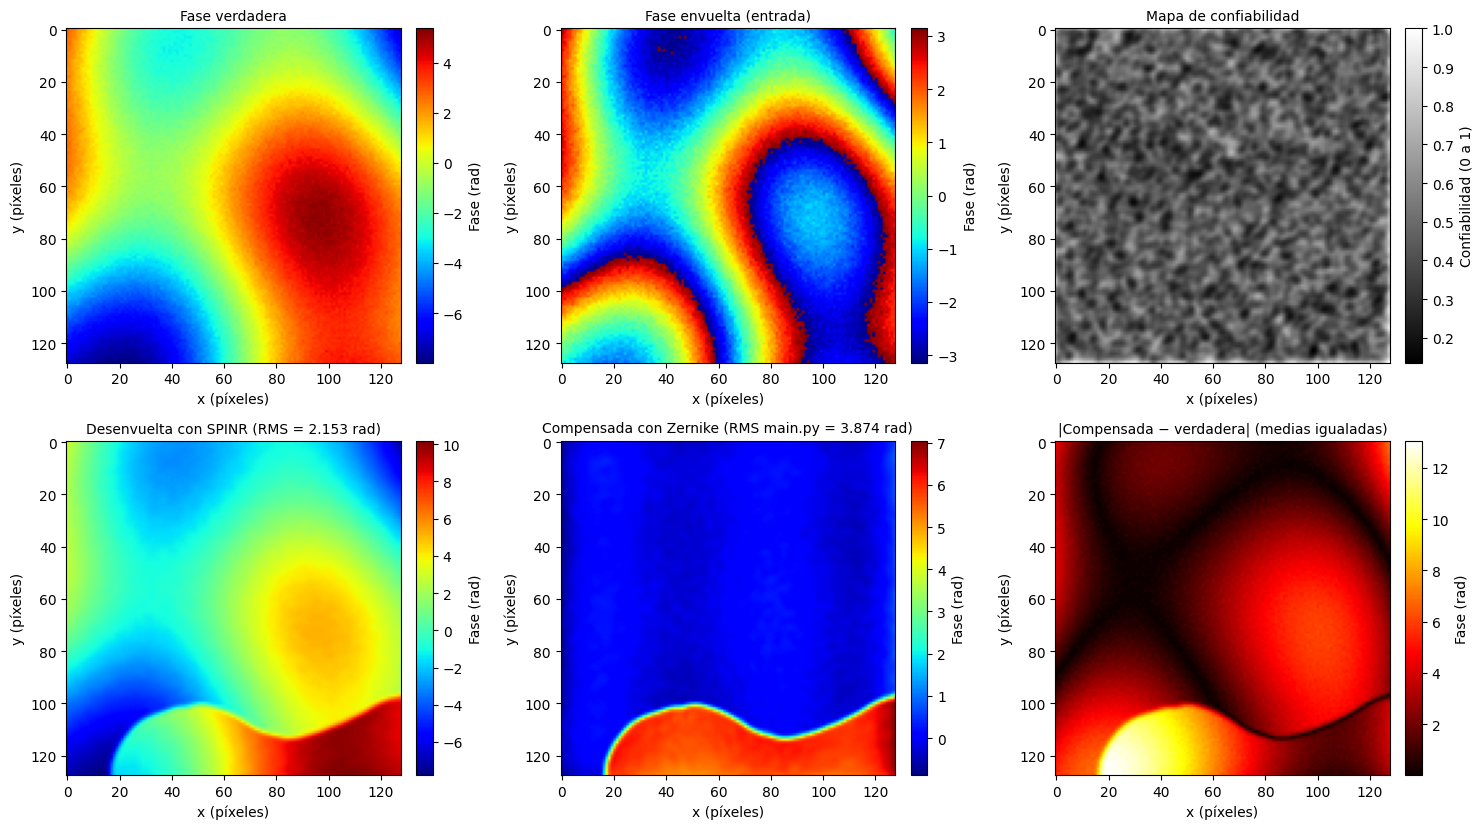

In [37]:
# 4.5 Ejecución del ejemplo sintético de main.py (mismos parámetros que el archivo original)
def create_test_phase(H=128, W=128):          # copiada literalmente de main.py
    x = np.linspace(-np.pi, np.pi, W)
    y = np.linspace(-np.pi, np.pi, H)
    XX, YY = np.meshgrid(x, y)

    true_phase = (3 * np.sin(XX) +
                  2 * np.cos(YY) +
                  0.5 * XX * YY)

    noise = np.random.normal(0, 0.1, (H, W))
    true_phase += noise

    wrapped = np.angle(np.exp(1j * true_phase))
    return true_phase, wrapped

def rms_alineado(estimada: np.ndarray, verdad: np.ndarray) -> float:
    """RMS de la diferencia tras igualar las medias (la fase solo se conoce salvo una constante)."""
    d = estimada - verdad
    return float(np.sqrt(np.mean((d - d.mean())**2)))

np.random.seed(42)                            # igual que main.py
true_phase, wrapped = create_test_phase(H=128, W=128)

def _ejemplo_sintetico() -> dict:
    fijar_semillas(SEED)
    t0 = time.perf_counter()
    unwrapped = spinr_unwrap(wrapped, n_iter_pretrain=300, n_iter_refine=500, lr_pretrain=1e-3, lr_refine=1e-4,
                             lambda_tv=0.001, lambda_cgrad=0.005, lambda_cmag=0.005)
    t_spinr = time.perf_counter() - t0
    t0 = time.perf_counter()
    unwrapped_sk = unwrap_phase(wrapped)
    t_sk = time.perf_counter() - t0
    reliability = compute_reliability_map(torch.tensor(wrapped, dtype=torch.float32)).numpy()
    compensated, background = compensate_background_zernike(unwrapped, reliability, n_terms=15, n_iter_cauchy=20,
                                                            n_bandwidth=5, n_iter_corr=10)
    return {"wrapped": wrapped, "unwrapped": unwrapped, "unwrapped_sk": unwrapped_sk, "reliability": reliability,
            "compensated": compensated, "background": background, "t_spinr": t_spinr, "t_sk": t_sk}

E2_SINT = en_cache("E2_ejemplo_sintetico", _ejemplo_sintetico)
assert np.array_equal(E2_SINT["wrapped"], wrapped), "La caché no corresponde a la fase sintética actual"

rms_spinr = rms_alineado(E2_SINT["unwrapped"], true_phase)
rms_sk = rms_alineado(E2_SINT["unwrapped_sk"], true_phase)
rms_main = rms_alineado(E2_SINT["compensated"], true_phase)      # la métrica que imprime main.py
tabla_sint = pd.DataFrame({"Valor": {
    "RMS desenvolvimiento SPINR vs. verdad (rad)": round(rms_spinr, 4),
    "RMS desenvolvimiento unwrap_phase vs. verdad (rad)": round(rms_sk, 4),
    "RMS final de main.py: compensada vs. verdad (rad)": round(rms_main, 4),
    "Tiempo SPINR (s)": round(E2_SINT["t_spinr"], 2),
    "Tiempo unwrap_phase (s)": round(E2_SINT["t_sk"], 4),
    "SPINR / unwrap_phase (veces más lento)": round(E2_SINT["t_spinr"] / max(E2_SINT["t_sk"], 1e-9), 0),
    "Saltos > π que deja SPINR": contar_saltos(E2_SINT["unwrapped"], np.pi),
    "Saltos > π que deja unwrap_phase": contar_saltos(E2_SINT["unwrapped_sk"], np.pi),
}})
guardar_tabla(tabla_sint.reset_index(names="Métrica"), "E2_ejemplo_sintetico")
display(tabla_sint)
H2_1 = rms_spinr <= 0.3
H2_2 = (rms_sk <= 0.3) and (E2_SINT["t_spinr"] / max(E2_SINT["t_sk"], 1e-9) >= 100)
H2_3 = rms_main > 2 * rms_spinr
print("H2.1:", "SE CUMPLE" if H2_1 else "SE RECHAZA", "| H2.2:", "SE CUMPLE" if H2_2 else "SE RECHAZA",
      "| H2.3:", "SE CUMPLE" if H2_3 else "SE RECHAZA")

fig, ax = plt.subplots(2, 3, figsize=(15, 8.4))
paneles = [(true_phase, "Fase verdadera", "jet"), (E2_SINT["wrapped"], "Fase envuelta (entrada)", "jet"),
           (E2_SINT["reliability"], "Mapa de confiabilidad", "gray"),
           (E2_SINT["unwrapped"], f"Desenvuelta con SPINR (RMS = {rms_spinr:.3f} rad)", "jet"),
           (E2_SINT["compensated"], f"Compensada con Zernike (RMS main.py = {rms_main:.3f} rad)", "jet"),
           (np.abs((E2_SINT["compensated"] - E2_SINT["compensated"].mean()) - (true_phase - true_phase.mean())),
            "|Compensada − verdadera| (medias igualadas)", "hot")]
for a, (img, titulo, cmap) in zip(ax.ravel(), paneles):
    im = a.imshow(img, cmap=cmap); a.set_title(titulo)
    a.set_xlabel("x (píxeles)"); a.set_ylabel("y (píxeles)")
    barra_color(im, a, "Confiabilidad (0 a 1)" if "confiabilidad" in titulo else "Fase (rad)")
fig.tight_layout(); plt.show()
guardar_figura(fig, "E2", "ejemplo_sintetico_main")

**Lectura de la salida (4.5).**
- **`unwrap_phase` recupera la fase verdadera exactamente:** RMS = 0,0000 rad, ruido incluido, sin saltos residuales y en 0,0033 s. **H2.2 se cumple.**
- **SPINR falla en su propio ejemplo:** RMS = **2,15 rad**, y **H2.1 se rechaza**. En la figura reproduce la forma general de la fase, pero a toda la franja inferior ($y \gtrsim 100$) le suma un escalón de ~$2\pi$: es un error de desenvolvimiento. El conteo da 0 saltos residuales porque la red suaviza el escalón; por tanto, **0 saltos no garantiza un desenvolvimiento correcto**. Además tarda 8,76 s, unas **2.650 veces** más que `unwrap_phase`.
- **H2.3 se rechaza con el criterio fijado:** el RMS final de `main.py` (3,87 rad) no supera $2 \times 2{,}15 = 4{,}31$ rad. El criterio estaba **mal planteado**, porque suponía que H2.1 se cumplía. La idea de fondo sí es consistente con la figura: la fase compensada vale ≈ 0 en casi toda la imagen. Como en este ejemplo toda la fase verdadera es suave, la compensación de Zernike la quitó casi entera, y lo que queda es el error de SPINR. El 3,87 de `main.py` mezcla esas dos cosas.

**Conclusión.** El ejemplo de `main.py` no valida ni el desenvolvimiento (SPINR falla) ni la separación del fondo (la fase sintética no tiene ningún objeto que preservar). Si más adelante se usan imágenes sintéticas, deberán tener **célula y fondo por separado**, con valores conocidos.

**Límite:** es una sola semilla y los parámetros de `main.py`. SPINR podría funcionar con otra configuración; no se ajustó porque `unwrap_phase` es exacto y miles de veces más rápido.

### 4.6 Código guía sobre imágenes reales del dataset (H2.4 a H2.7)

Se aplica el código guía a dos imágenes de **entrenamiento**: la de mayor rango del fondo y la de rango mediano (3.7.3). No se usan imágenes de validación ni de prueba, para no tomar decisiones de diseño mirando datos reservados.

Para cada imagen:
1. **Desenvolvimiento:** `spinr_unwrap` (con los parámetros de `main.py`) frente a `unwrap_phase`, sobre la misma fase envuelta $2\pi g/255 - \pi$.
2. **Compensación del fondo** sobre la imagen preprocesada de 3.11, convertida a radianes: `compensate_background` (SIREN de baja frecuencia, 500 iteraciones) y `compensate_background_zernike` (15 términos). El mapa de confiabilidad que piden se calcula sobre la fase envuelta.
3. **Extracción de la muestra:** `extract_sample_phase` sobre la imagen compensada con Zernike, comparando su máscara con la de referencia mediante el coeficiente de Dice, $\text{Dice} = 2|A \cap B|/(|A| + |B|)$.

Las métricas $\mu_B$, $\sigma_B$, $h_C$ y $\Delta h_C$ se definieron en 4.0.

In [38]:
# 4.6.1 Código guía sobre dos imágenes de entrenamiento (cálculo; los resultados se guardan en caché)
_ent = METRICAS_SEL[METRICAS_SEL.conjunto == "entrenamiento"].sort_values("fondo_rango_ng").reset_index(drop=True)
IMAGENES_E2 = [_ent.archivo.iloc[-1], _ent.archivo.iloc[(len(_ent) - 1) // 2]]   # rango del fondo máximo y mediano
assert len(set(IMAGENES_E2)) == 2, "Se necesitan dos imágenes distintas"
print("Imágenes usadas:", IMAGENES_E2)

def _guia_en_imagen(archivo: str) -> dict:
    g = IMAGENES[archivo]
    phi_env = gris_a_fase_envuelta(g)                       # fase envuelta (rad), convención del dataset
    t0 = time.perf_counter(); phi_sk = unwrap_phase(phi_env); t_sk = time.perf_counter() - t0
    fijar_semillas(SEED)
    t0 = time.perf_counter()
    phi_spinr = spinr_unwrap(phi_env, n_iter_pretrain=300, n_iter_refine=500, lr_pretrain=1e-3, lr_refine=1e-4,
                             lambda_tv=0.001, lambda_cgrad=0.005, lambda_cmag=0.005)
    t_spinr = time.perf_counter() - t0
    confiab = compute_reliability_map(torch.tensor(phi_env, dtype=torch.float32)).numpy()
    phi = PREPROCESADAS[archivo] / NG_POR_RAD               # desenvuelta, célula positiva (rad)
    fijar_semillas(SEED)
    t0 = time.perf_counter(); comp_siren, fondo_siren = compensate_background(phi, confiab); t_siren = time.perf_counter() - t0
    t0 = time.perf_counter(); comp_zern, fondo_zern = compensate_background_zernike(phi, confiab); t_zern = time.perf_counter() - t0
    muestra, M_bin, _ = extract_sample_phase(comp_zern, confiab)
    return {"phi_sk": phi_sk, "phi_spinr": phi_spinr, "t_sk": t_sk, "t_spinr": t_spinr, "confiab": confiab,
            "comp_siren": comp_siren, "comp_zern": comp_zern, "t_siren": t_siren, "t_zern": t_zern,
            "muestra": muestra, "M_bin": M_bin.astype(bool)}

E2_REAL = {f: en_cache(f"E2_guia_{f[:-4]}", lambda f=f: _guia_en_imagen(f)) for f in IMAGENES_E2}
for f in IMAGENES_E2:
    assert np.allclose(-E2_REAL[f]["phi_sk"] * NG_POR_RAD, PREPROCESADAS[f]), f"La caché de {f} no corresponde a los datos"

Imágenes usadas: ['Image__2021-01-29__12-29-32_4-11.png', 'Image__2021-01-29__13-25-56_1-11.png']
[caché] 'E2_guia_Image__2021-01-29__12-29-32_4-11' cargado de results/cache/ (no se recalculó)
[caché] 'E2_guia_Image__2021-01-29__13-25-56_1-11' cargado de results/cache/ (no se recalculó)


In [39]:
# 4.6.2 Resultados: desenvolvimiento y compensación del fondo (métricas preliminares en niveles de gris equivalentes)
def metricas_preliminares(v_ng: np.ndarray, archivo: str) -> dict:
    """μ_B, σ_B y h_C sobre las máscaras de referencia de 3.10."""
    cel, fon = MASCARAS[archivo]
    return {"μ_B": float(v_ng[fon].mean()), "σ_B": float(v_ng[fon].std()),
            "h_C": float(np.median(v_ng[cel]) - np.median(v_ng[fon]))}

def dice(a: np.ndarray, b: np.ndarray) -> float:
    return float(2 * (a & b).sum() / (a.sum() + b.sum()))

sigma_ruido = dict(zip(FONDO.archivo, FONDO["σ_ruido (niveles eq.)"]))
filas_unw, filas_fondo = [], []
for f in IMAGENES_E2:
    r = E2_REAL[f]
    d = r["phi_spinr"] - r["phi_sk"]
    filas_unw.append({"imagen": f[7:-4], "RMS SPINR − unwrap_phase (rad)": float(np.sqrt(np.mean((d - d.mean())**2))),
                      "saltos > π SPINR": contar_saltos(r["phi_spinr"], np.pi),
                      "saltos > π unwrap_phase": contar_saltos(r["phi_sk"], np.pi),
                      "tiempo SPINR (s)": r["t_spinr"], "tiempo unwrap_phase (s)": r["t_sk"]})
    base = metricas_preliminares(PREPROCESADAS[f], f)
    for metodo, v in [("Preprocesada (sin corregir)", PREPROCESADAS[f]),
                      ("compensate_background (SIREN ω0=1)", r["comp_siren"] * NG_POR_RAD),
                      ("compensate_background_zernike", r["comp_zern"] * NG_POR_RAD),
                      ("extract_sample_phase (sobre Zernike)", r["muestra"] * NG_POR_RAD)]:
        m = metricas_preliminares(v, f)
        filas_fondo.append({"imagen": f[7:-4], "método": metodo, **m,
                            "Δh_C (%)": 100 * (m["h_C"] - base["h_C"]) / base["h_C"],
                            "σ_B / σ_ruido": m["σ_B"] / sigma_ruido[f]})
TABLA_UNW = pd.DataFrame(filas_unw); TABLA_FONDO = pd.DataFrame(filas_fondo)
guardar_tabla(TABLA_UNW, "E2_desenvolvimiento_real"); guardar_tabla(TABLA_FONDO, "E2_fondo_real")
display(TABLA_UNW.round(4)); display(TABLA_FONDO.round(2))

dices = {f: dice(E2_REAL[f]["M_bin"], MASCARAS[f][0]) for f in IMAGENES_E2}
print("Dice de extract_sample_phase con la máscara de referencia:", {k[7:-4]: round(v, 3) for k, v in dices.items()})

def _cumple_fondo(metodo: str) -> bool:
    t = TABLA_FONDO[TABLA_FONDO["método"] == metodo]
    return bool(((t["σ_B / σ_ruido"] <= 1.1) & (t["Δh_C (%)"].abs() < 5)).all())

H2_4 = bool((TABLA_UNW["RMS SPINR − unwrap_phase (rad)"] < 0.2).all()
            and (TABLA_UNW["saltos > π SPINR"] <= TABLA_UNW["saltos > π unwrap_phase"]).all())
H2_5 = _cumple_fondo("compensate_background (SIREN ω0=1)")
H2_6 = _cumple_fondo("compensate_background_zernike")
H2_7 = all(v >= 0.8 for v in dices.values())
for nombre, valor in [("H2.4", H2_4), ("H2.5", H2_5), ("H2.6", H2_6), ("H2.7", H2_7)]:
    print(nombre + ":", "SE CUMPLE" if valor else "SE RECHAZA")

,imagen,RMS SPINR − unwrap_phase (rad),saltos > π SPINR,saltos > π unwrap_phase,tiempo SPINR (s),tiempo unwrap_phase (s)
0,2021-01-29__12-29-32_4-11,1.4951,0,2,19.2910,0.0119
1,2021-01-29__13-25-56_1-11,2.8776,27,0,19.0899,0.0115


,imagen,método,μ_B,σ_B,h_C,Δh_C (%),σ_B / σ_ruido
0,2021-01-29__12-29-32_4-11,Preprocesada (sin corregir),10.40,22.87,167.00,0.00,1.66
1,2021-01-29__12-29-32_4-11,compensate_background (SIREN ω0=1),-0.27,6.45,107.42,-35.67,0.47
2,2021-01-29__12-29-32_4-11,compensate_background_zernike,0.19,11.18,129.35,-22.54,0.81
3,2021-01-29__12-29-32_4-11,extract_sample_phase (sobre Zernike),2.38,6.99,128.22,-23.22,0.51
4,2021-01-29__13-25-56_1-11,Preprocesada (sin corregir),29.21,16.45,147.00,0.00,1.20
5,2021-01-29__13-25-56_1-11,compensate_background (SIREN ω0=1),0.46,6.60,115.22,-21.62,0.48
6,2021-01-29__13-25-56_1-11,compensate_background_zernike,-0.25,10.90,120.84,-17.80,0.80
7,2021-01-29__13-25-56_1-11,extract_sample_phase (sobre Zernike),1.45,5.56,120.26,-18.19,0.41


Dice de extract_sample_phase con la máscara de referencia: {'2021-01-29__12-29-32_4-11': 0.76, '2021-01-29__13-25-56_1-11': 0.821}
H2.4: SE RECHAZA
H2.5: SE RECHAZA
H2.6: SE RECHAZA
H2.7: SE RECHAZA


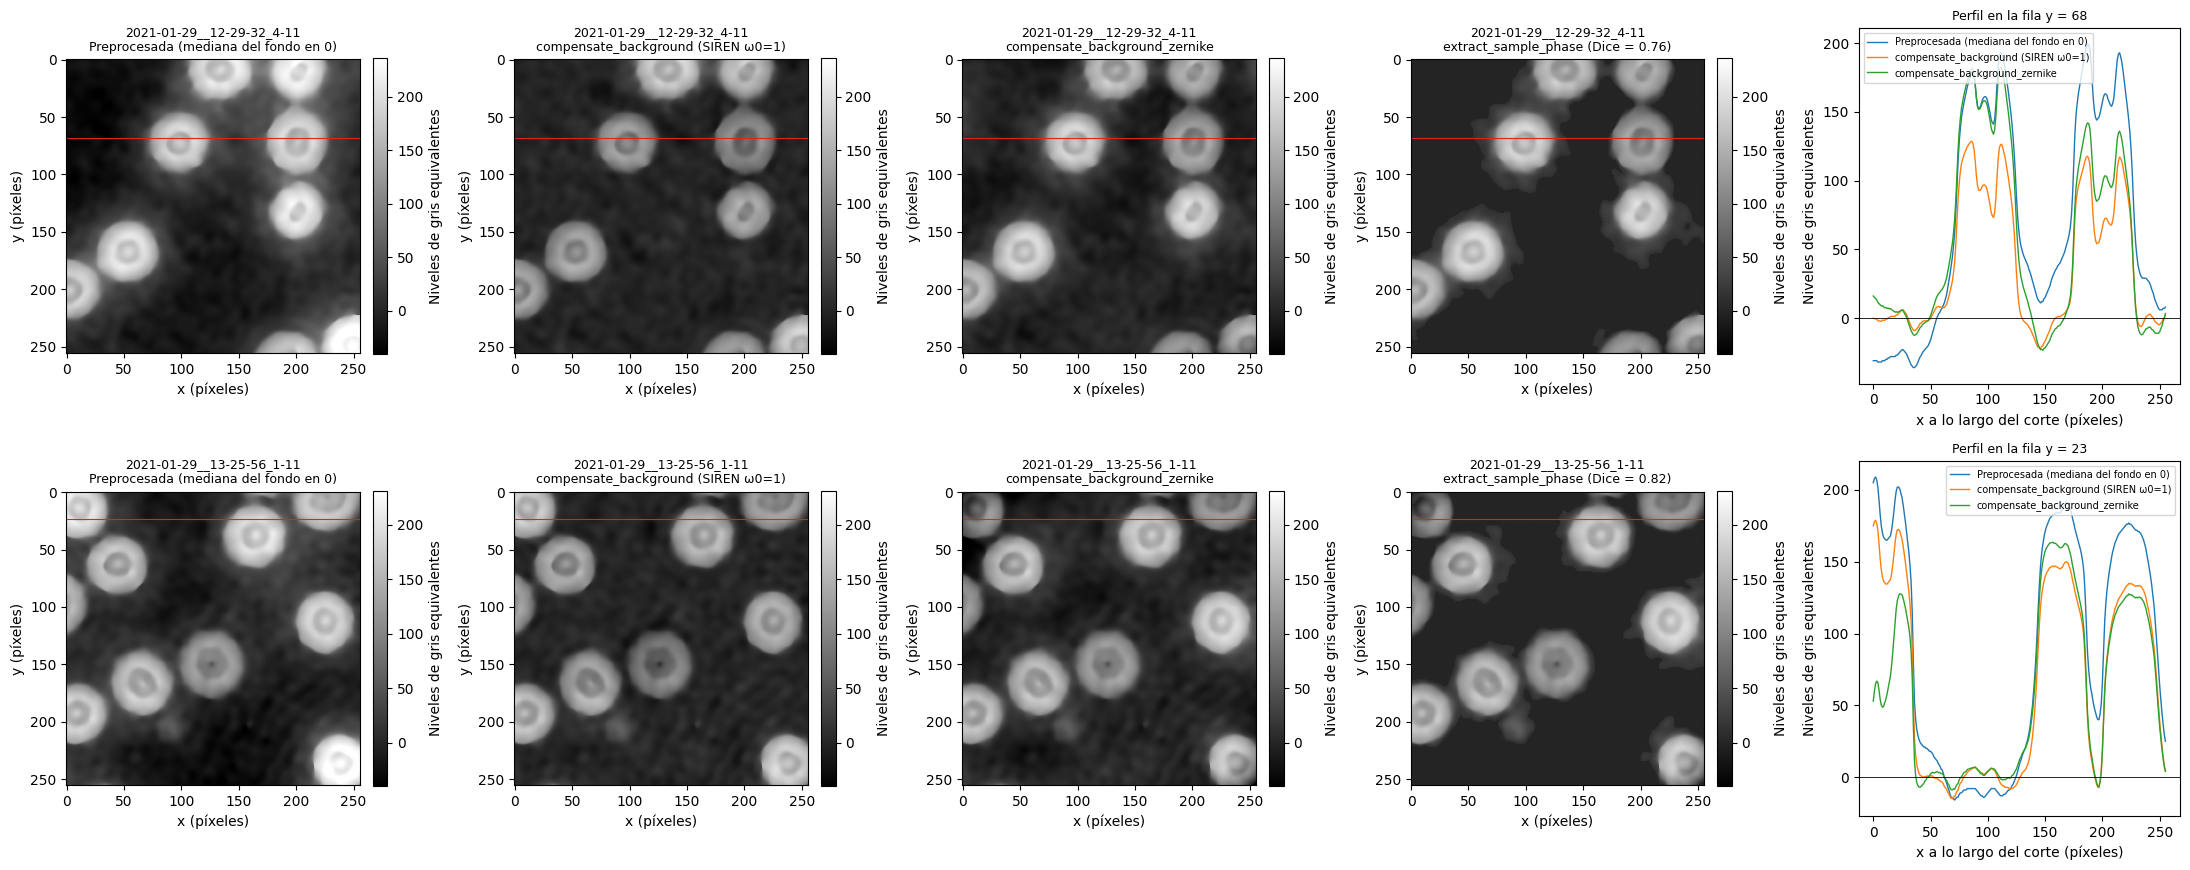

In [40]:
# 4.6.3 Figura: imagen preprocesada, resultados del código guía y un perfil por cada imagen
fig, ax = plt.subplots(len(IMAGENES_E2), 5, figsize=(22, 4.4 * len(IMAGENES_E2)))
for k, f in enumerate(IMAGENES_E2):
    r = E2_REAL[f]; cel, fon = MASCARAS[f]
    pre = PREPROCESADAS[f] - np.median(PREPROCESADAS[f][fon])   # solo para comparar en la misma escala
    paneles = [(pre, "Preprocesada (mediana del fondo en 0)"),
               (r["comp_siren"] * NG_POR_RAD, "compensate_background (SIREN ω0=1)"),
               (r["comp_zern"] * NG_POR_RAD, "compensate_background_zernike"),
               (r["muestra"] * NG_POR_RAD, f"extract_sample_phase (Dice = {dices[f]:.2f})")]
    vmin, vmax = -40, float(np.percentile(pre, 99.5))
    y0 = int(np.argmax(cel.sum(axis=1)))
    for j, (img, titulo) in enumerate(paneles):
        im = ax[k, j].imshow(img, vmin=vmin, vmax=vmax); ax[k, j].axhline(y0, color="tab:red", lw=0.8)
        ax[k, j].set_title(f"{f[7:-4]}\n{titulo}", fontsize=9)
        ax[k, j].set_xlabel("x (píxeles)"); ax[k, j].set_ylabel("y (píxeles)")
        barra_color(im, ax[k, j], "Niveles de gris equivalentes")
    for img, etiqueta in paneles[:3]:
        ax[k, 4].plot(img[y0], lw=1, label=etiqueta)
    ax[k, 4].axhline(0, color="k", lw=0.6)
    ax[k, 4].set_xlabel("x a lo largo del corte (píxeles)"); ax[k, 4].set_ylabel("Niveles de gris equivalentes")
    ax[k, 4].set_title(f"Perfil en la fila y = {y0}", fontsize=9); ax[k, 4].legend(fontsize=7)
fig.tight_layout(); plt.show()
guardar_figura(fig, "E2", "codigo_guia_imagenes_reales")

**Lectura de la salida (4.6).** Imágenes: `12-29-32_4-11` (mayor rango del fondo en entrenamiento) y `13-25-56_1-11` (rango mediano).

**Desenvolvimiento (H2.4 se rechaza).** La diferencia entre SPINR y `unwrap_phase` tiene un RMS de **1,50 y 2,88 rad**. En la segunda imagen SPINR deja 27 saltos, frente a 0 de `unwrap_phase`; en la primera, 0 frente a 2. En imágenes reales no hay verdad conocida, pero junto con 4.5 (SPINR falla con verdad conocida) y con la continuidad y la forma de dona de las células desenvueltas con `unwrap_phase` (3.8, 3.11), el resultado es consistente con que los errores son de SPINR. SPINR tarda ~19 s por imagen, frente a ~0,012 s. **Decisión: se mantiene `unwrap_phase`.**

**Compensación del fondo (H2.5 y H2.6 se rechazan).**

| Imagen | Método | $\mu_B$ | $\sigma_B$ | $\sigma_B/\sigma_{\text{ruido}}$ | $\Delta h_C$ |
|---|---|---|---|---|---|
| `12-29-32_4-11` | Preprocesada | 10,40 | 22,87 | 1,66 | — |
| | SIREN $\omega_0 = 1$ | −0,27 | 6,45 | 0,47 | **−35,7 %** |
| | Zernike robusto | 0,19 | 11,18 | 0,81 | **−22,5 %** |
| `13-25-56_1-11` | Preprocesada | 29,21 | 16,45 | 1,20 | — |
| | SIREN $\omega_0 = 1$ | 0,46 | 6,60 | 0,48 | **−21,6 %** |
| | Zernike robusto | −0,25 | 10,90 | 0,80 | **−17,8 %** |

- **El fondo sí queda en cero** con los dos métodos ($|\mu_B| < 0{,}5$ niveles) y con $\sigma_B$ por debajo de $\sigma_{\text{ruido}}$. La SIREN baja $\sigma_B$ hasta ~0,47 $\sigma_{\text{ruido}}$: además de la componente lenta quita parte de la textura, lo que indica más flexibilidad que la superficie de grado 2 de 3.9.
- **Lo que falla es $|\Delta h_C| < 5\,\%$:** la altura de las células baja entre 18 y 36 %.

**Limitación de la métrica preliminar.** $h_C$ compara la mediana de las células con la mediana **global** del fondo. Si el fondo lento es más alto bajo las células que en promedio, $h_C$ antes de corregir está inflado, y parte de la caída sería una corrección **legítima**. Es coherente con que la mayor caída ocurra en la imagen con mayor rango del fondo. Por eso $\Delta h_C$ **sobreestima** la absorción, y la métrica de preservación de la sección 6 deberá ser **local**: cada célula frente a un anillo de fondo a su alrededor.

**Aun así, los perfiles indican absorción real.** Lecturas aproximadas de la figura:
- En `12-29-32_4-11`, fila 68, la célula en $x \approx 90$ queda unos 180 niveles sobre su fondo cercano en la preprocesada y unos 145 con la SIREN (≈ −20 %).
- En `13-25-56_1-11`, fila 23, la célula del borde izquierdo baja de ~200 a ~125 con Zernike. Es consistente con un **efecto de borde** del ajuste polinomial, que no usa la máscara circular (4.4).

**Extracción de la muestra (H2.7 se rechaza).** Dice = **0,76 y 0,82**. La máscara cubre el 38,9 % y el 42,5 % de la imagen, frente a ~25 % de la referencia: **sobresegmenta**, incluyendo halos y bordes irregulares (cuarto panel de la figura). No se usará como máscara.

**Conclusión.** Los métodos del código guía llevan el fondo a cero, pero con indicios de absorción parcial de las células, mayor en la SIREN, que es el método más flexible. Es el compromiso anticipado en 3.9 y es exactamente lo que el modelo del proyecto debe mejorar. Estos dos métodos pasan a ser **líneas base** (sección 5).

### 4.7 Contraste de las hipótesis de la etapa E2

**Resumen** (tabla siguiente): 1 hipótesis se cumple (H2.2) y 6 se rechazan.

| Hipótesis rechazada | Por qué | Consecuencia |
|---|---|---|
| H2.1, H2.4 | SPINR comete errores de desenvolvimiento, con verdad conocida y en imágenes reales | Se usa `unwrap_phase`, que es exacto en el caso sintético y miles de veces más rápido (H2.2) |
| H2.3 | El criterio dependía de que H2.1 se cumpliera: estaba mal planteado | Lección de diseño: los criterios no deben depender del resultado de otra hipótesis. La idea de fondo es consistente con la figura de 4.5 |
| H2.5, H2.6 | Los dos métodos del código guía bajan la altura de las células un 18–36 % (métrica global) | Pasan a ser líneas base. La métrica de preservación debe ser local (sección 6). El modelo del proyecto debe reducir el fondo **sin** esa pérdida |
| H2.7 | `extract_sample_phase` sobresegmenta (Dice 0,76–0,82) | Se mantienen las máscaras de referencia de 3.10 |

**Qué no se puede concluir:** que SPINR no funcione con otros parámetros o semillas; ni el porcentaje exacto de absorción, porque la métrica global está confundida con la pendiente del fondo. Todo se basa en **dos** imágenes de entrenamiento.

In [41]:
# 4.7 Resumen automático del contraste de hipótesis de la etapa E2
contraste_e2 = pd.DataFrame([
    ("H2.1", "SPINR recupera la fase sintética (RMS ≤ 0,3 rad)", estado(H2_1), "4.5"),
    ("H2.2", "unwrap_phase la recupera y es ≥ 100 veces más rápido", estado(H2_2), "4.5"),
    ("H2.3", "El RMS final de main.py no mide la separación del fondo", estado(H2_3), "4.5"),
    ("H2.4", "SPINR y unwrap_phase coinciden en imágenes reales", estado(H2_4), "4.6"),
    ("H2.5", "SIREN de baja frecuencia: σ_B ≤ 1,1 σ_ruido y |Δh_C| < 5 %", estado(H2_5), "4.6"),
    ("H2.6", "Zernike robusto: σ_B ≤ 1,1 σ_ruido y |Δh_C| < 5 %", estado(H2_6), "4.6"),
    ("H2.7", "extract_sample_phase: Dice ≥ 0,8", estado(H2_7), "4.6"),
], columns=["ID", "Hipótesis", "Resultado", "Sección"])
guardar_tabla(contraste_e2, "E2_contraste_hipotesis")
contraste_e2

,ID,Hipótesis,Resultado,Sección
0,H2.1,"SPINR recupera la fase sintética (RMS ≤ 0,3 rad)",Se rechaza,4.5
1,H2.2,unwrap_phase la recupera y es ≥ 100 veces más ...,Se cumple,4.5
2,H2.3,El RMS final de main.py no mide la separación ...,Se rechaza,4.5
3,H2.4,SPINR y unwrap_phase coinciden en imágenes reales,Se rechaza,4.6
4,H2.5,"SIREN de baja frecuencia: σ_B ≤ 1,1 σ_ruido y ...",Se rechaza,4.6
5,H2.6,"Zernike robusto: σ_B ≤ 1,1 σ_ruido y |Δh_C| < 5 %",Se rechaza,4.6
6,H2.7,"extract_sample_phase: Dice ≥ 0,8",Se rechaza,4.6


## 5. Líneas base no aprendidas

Una línea base responde a la pregunta *¿cuánto se logra sin el modelo propuesto?* Sin ella no se puede afirmar que el modelo aporte algo. Esta sección define las líneas base (5.1), las aplica a las imágenes de entrenamiento y validación, verifica la implementación y mide su costo (5.2), y muestra un ejemplo (5.3).

**Su desempeño se mide en la sección 6**, porque requiere las métricas formales, en particular la de preservación local de la célula (decisión de 4.6). Allí se fijan también, antes de calcularlas, las hipótesis sobre las líneas base.

### 5.0 Reglas para una comparación justa

| Regla | Cómo se cumple |
|---|---|
| Misma entrada y misma unidad | Todas reciben la imagen preprocesada $u$ (3.11) y devuelven un fondo $\hat b$ en niveles de gris equivalentes |
| Sin información privilegiada | Ninguna usa las máscaras de referencia (3.10): se reservan para evaluar. El modelo tampoco las usará |
| Prueba intacta | Aquí solo se procesan entrenamiento y validación. Prueba se procesa una única vez, en la sección 9 |
| Hiperparámetros fijados de antemano | Los del código guía (4.4) y los de 3.5, sin ajustarlos mirando resultados. Única excepción: el grado del polinomio, que se elige en validación (sección 6) con la misma métrica y el mismo conjunto con que se elegirán los hiperparámetros del modelo |

### 5.1 Definición de las líneas base

> **Definición 10 (línea base de fondo).** Un método $\mathcal B$ estima el fondo $\hat b = \mathcal B(u)$, y la imagen corregida es $v = u - \hat b$. Según el modelo aditivo de 4.2, lo ideal es $v \approx 0$ en el fondo y $v \approx \varphi_{\text{cel}}$ (en niveles equivalentes) en las células.

| ID | Método | Fondo estimado $\hat b$ | Parámetros libres | Origen y papel |
|---|---|---|---|---|
| L0 | Pistón | $\operatorname{mediana}(u)$, una constante | 1 | Cota inferior: solo quita el nivel medio y no corrige la forma del fondo |
| L1 | Polinomio robusto de grado $d \in \{1, 2, 3\}$ | $\sum_{i+j \le d} c_{ij}\,x^i y^j$ | 3, 6, 10 | Método clásico de baja frecuencia; generaliza `ajuste_fondo_robusto` (3.5) |
| L2 | Zernike robusto | 15 polinomios de Zernike (hasta orden 4), ajustados con pesos de Cauchy y máxima correntropía | 15 | `compensate_background_zernike` del código guía |
| L3 | SIREN de baja frecuencia | `LowFreqBackgroundNetwork` (128 neuronas, 2 capas, $\omega_0 = 1$) entrenada con $L_1$ recortada | ver 5.2 | `compensate_background` del código guía; es la INR de referencia |

> **Definición 11 (ajuste polinomial robusto, L1).** Sea $A$ la matriz de monomios $x^i y^j$ ($i + j \le d$) sobre la malla $[-1,1]^2$ y sea $m^{(0)}$ el conjunto de todos los píxeles. Para $t = 0, \dots, 7$:
> $$c^{(t)} = \arg\min_{c} \sum_{p \in m^{(t)}} \big(u_p - (Ac)_p\big)^2, \qquad r^{(t)} = u - A\,c^{(t)},$$
> $$\hat\sigma^{(t)} = 1{,}4826\;\operatorname{MAD}\big(r^{(t)}\ \text{en}\ m^{(t)}\big), \qquad m^{(t+1)} = \big\{\,p : |r^{(t)}_p| < 2{,}5\,\hat\sigma^{(t)}\big\}.$$
> El fondo estimado es $\hat b = A\,c^{(7)}$.

*Ejemplo numérico.* Con $\hat\sigma \approx 14$ niveles (orden del ruido medido en 3.9), el umbral es $2{,}5 \times 14 = 35$ niveles. Un píxel de célula que sobresale ~150 niveles del fondo queda fuera de $m$ desde la primera iteración y deja de arrastrar el ajuste; un píxel de fondo con residuo de 10 niveles sigue dentro.

Detalles de implementación:
- L2 y L3 se aplican exactamente como en 4.6: en radianes ($\varphi = u \cdot 2\pi/255 \approx 0{,}0246\,u$, es decir, `u / NG_POR_RAD`), con el mapa de confiabilidad calculado desde la fase envuelta, y el resultado se pasa a niveles equivalentes. Su tiempo incluye el del mapa de confiabilidad.
- L3 se entrena con la semilla de 2.2, fijada justo antes, como en 4.6.

> **L1 con $d = 2$ no es un competidor independiente.** Es el mismo ajuste con el que se construyeron las máscaras de referencia (3.10) y se estimó $\sigma_{\text{ruido}}$ (3.9). Sus métricas del fondo salen favorecidas por construcción: las células de la referencia son, por definición, lo que este ajuste deja fuera. Lo mismo vale en menor medida para $d = 3$, que contiene al de grado 2. Se reportan como **referencia**; la comparación con el modelo se apoya sobre todo en L0, L1 con $d = 1$, L2 y L3. *(6.3 acota este efecto: las máscaras casi no dependen del grado, así que la circularidad afecta a Dice y a las métricas con $\sigma_{\text{ruido}}$, no a las métricas principales M1 y M2 de la sección 6.)*

In [42]:
# 5.1.1 Implementación de las líneas base y cálculo sobre entrenamiento y validación (resultados en caché)
import io
import contextlib

def base_polinomial(grado: int) -> np.ndarray:
    """Monomios x^i·y^j con i + j ≤ grado sobre la malla [-1, 1]² de 3.5, como matriz (H·W, n_coeficientes)."""
    columnas = [(_xx ** (t - j)) * (_yy ** j) for t in range(grado + 1) for j in range(t + 1)]
    return np.stack(columnas, -1).reshape(-1, len(columnas))

BASES_POLI = {d: base_polinomial(d) for d in (1, 2, 3)}

def ajuste_polinomial_robusto(u: np.ndarray, grado: int, iteraciones: int = 8, k: float = 2.5) -> np.ndarray:
    """Definición 11: generaliza ajuste_fondo_robusto (3.5) a cualquier grado. Devuelve el fondo estimado."""
    A = BASES_POLI[grado]; v = u.ravel(); m = np.ones(v.size, bool)
    for _ in range(iteraciones):
        c = np.linalg.lstsq(A[m], v[m], rcond=None)[0]
        r = v - A @ c
        s = 1.4826 * np.median(np.abs(r[m] - np.median(r[m])))
        m = np.abs(r) < k * s
    return (A @ c).reshape(u.shape)

def _en_silencio(funcion, *args, **kwargs):
    """Ejecuta una función del código guía sin sus mensajes de progreso (print y tqdm)."""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        return funcion(*args, **kwargs)

METODOS_LB = ["Pistón", "Polinomio g1", "Polinomio g2", "Polinomio g3", "Zernike (guía)", "SIREN ω0=1 (guía)"]

def _lineas_base_en_imagen(archivo: str) -> dict:
    u = PREPROCESADAS[archivo]
    phi = u / NG_POR_RAD                                     # radianes, como en 4.6
    fondos, tiempos = {}, {}
    def medir(nombre, calcular, extra=0.0):
        t0 = time.perf_counter(); b = calcular()
        tiempos[nombre] = time.perf_counter() - t0 + extra
        fondos[nombre] = np.asarray(b, dtype=np.float32)
    medir("Pistón", lambda: np.full(u.shape, np.median(u)))
    for d in (1, 2, 3):
        medir(f"Polinomio g{d}", lambda d=d: ajuste_polinomial_robusto(u, d))
    t0 = time.perf_counter()
    confiab = compute_reliability_map(torch.tensor(gris_a_fase_envuelta(IMAGENES[archivo]), dtype=torch.float32)).numpy()
    t_conf = time.perf_counter() - t0
    medir("Zernike (guía)", lambda: _en_silencio(compensate_background_zernike, phi, confiab)[1] * NG_POR_RAD, t_conf)
    fijar_semillas(SEED)
    medir("SIREN ω0=1 (guía)", lambda: _en_silencio(compensate_background, phi, confiab)[1] * NG_POR_RAD, t_conf)
    return {"fondos": fondos, "tiempos": tiempos}

ARCHIVOS_LB = SELECCION[SELECCION.conjunto.isin(["entrenamiento", "validacion"])].archivo.tolist()
LINEAS_BASE = {f: en_cache(f"LB_{f[:-4]}", lambda f=f: _lineas_base_en_imagen(f)) for f in ARCHIVOS_LB}
for f in ARCHIVOS_LB:
    assert list(LINEAS_BASE[f]["fondos"]) == METODOS_LB, f"La caché de {f} no tiene los métodos actuales"
    assert np.isclose(float(LINEAS_BASE[f]["fondos"]["Pistón"].flat[0]), float(np.median(PREPROCESADAS[f])), atol=1e-3), \
        f"La caché de {f} no corresponde a los datos actuales"
print(f"Líneas base disponibles para {len(ARCHIVOS_LB)} imágenes "
      f"({(SELECCION.conjunto == 'entrenamiento').sum()} de entrenamiento y {(SELECCION.conjunto == 'validacion').sum()} de validación).")

[caché] 'LB_Image__2021-01-29__12-29-32_4-11' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__12-59-27_2-4' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-01-44_4-16' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-04-29_1-7' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-13-16_2-15' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-23-48_2-12' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-25-48_1-14' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-25-56_1-11' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-27-04_4-2' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-31-27_4-16' cargado de results/cache/ (no se recalculó)
[caché] 'LB_Image__2021-01-29__13-31-33_2-12' cargado de results/cache/ (no se recalculó)
[caché] 'LB_I

### 5.2 Verificaciones de la implementación y costo computacional

Antes de usar las líneas base se comprueba que están bien implementadas. Los criterios se fijan antes de ejecutar:

| ID | Verificación | Criterio |
|---|---|---|
| V5.1 | `ajuste_polinomial_robusto` con $d = 2$ reproduce `ajuste_fondo_robusto` (3.5) | máx $\lvert\Delta \hat b\rvert < 10^{-6}$ niveles |
| V5.2 | L2 reproduce el Zernike de 4.6 en sus dos imágenes | máx $\lvert\Delta \hat b\rvert < 0{,}01$ niveles: el cálculo es determinista y el margen cubre el almacenamiento en `float32` |
| V5.3 | L3 reproduce la SIREN de 4.6 con la misma semilla | máx $\lvert\Delta \hat b\rvert < 0{,}5$ niveles: en GPU algunas operaciones no son exactamente deterministas |

La tabla de costo da, por método, el número de parámetros libres y el tiempo por imagen en el equipo de 2.3. Servirá para la discusión entre desempeño, complejidad y tiempo (sección 11).

In [43]:
# 5.2.1 Verificaciones V5.1–V5.3 y costo computacional de cada línea base
u_ej = PREPROCESADAS[IMAGENES_E2[0]]
filas_v = [{"verificación": "V5.1", "imagen": IMAGENES_E2[0][7:-4], "método": "Polinomio g2",
            "máx |Δ b̂| (niveles eq.)": float(np.abs(ajuste_polinomial_robusto(u_ej, 2) - ajuste_fondo_robusto(u_ej)[0]).max()),
            "umbral": 1e-6}]
for f in IMAGENES_E2:
    for vid, metodo, clave, umbral in [("V5.2", "Zernike (guía)", "comp_zern", 0.01), ("V5.3", "SIREN ω0=1 (guía)", "comp_siren", 0.5)]:
        fondo_e2 = PREPROCESADAS[f] - E2_REAL[f][clave] * NG_POR_RAD      # fondo que estimó el código guía en 4.6
        filas_v.append({"verificación": vid, "imagen": f[7:-4], "método": metodo,
                        "máx |Δ b̂| (niveles eq.)": float(np.abs(LINEAS_BASE[f]["fondos"][metodo] - fondo_e2).max()),
                        "umbral": umbral})
VERIF_LB = pd.DataFrame(filas_v)
VERIF_LB["cumple"] = VERIF_LB["máx |Δ b̂| (niveles eq.)"] < VERIF_LB["umbral"]
guardar_tabla(VERIF_LB, "LB_verificaciones")
display(VERIF_LB)
for vid in ("V5.1", "V5.2", "V5.3"):
    print(f"{vid}:", "SE CUMPLE" if VERIF_LB[VERIF_LB["verificación"] == vid].cumple.all() else "NO SE CUMPLE")

n_siren = sum(p.numel() for p in LowFreqBackgroundNetwork(hidden_dim=128, n_layers=2, omega_0=1.0).parameters())
PARAMETROS_LB = {"Pistón": 1, "Polinomio g1": 3, "Polinomio g2": 6, "Polinomio g3": 10, "Zernike (guía)": 15,
                 "SIREN ω0=1 (guía)": n_siren}
tiempos_lb = pd.DataFrame({f: LINEAS_BASE[f]["tiempos"] for f in ARCHIVOS_LB}).T
COSTO_LB = pd.DataFrame({"parámetros libres": pd.Series(PARAMETROS_LB),
                         "tiempo mediano por imagen (s)": tiempos_lb.median(),
                         "tiempo máximo por imagen (s)": tiempos_lb.max()}).loc[METODOS_LB]
guardar_tabla(COSTO_LB, "LB_costo", index=True)
COSTO_LB.round(4)

,verificación,imagen,método,máx |Δ b̂| (niveles eq.),umbral,cumple
0,V5.1,2021-01-29__12-29-32_4-11,Polinomio g2,0.000000,0.000001,True
1,V5.2,2021-01-29__12-29-32_4-11,Zernike (guía),0.000008,0.010000,True
2,V5.3,2021-01-29__12-29-32_4-11,SIREN ω0=1 (guía),0.000005,0.500000,True
3,V5.2,2021-01-29__13-25-56_1-11,Zernike (guía),0.000008,0.010000,True
4,V5.3,2021-01-29__13-25-56_1-11,SIREN ω0=1 (guía),0.000005,0.500000,True


V5.1: SE CUMPLE
V5.2: SE CUMPLE
V5.3: SE CUMPLE


,parámetros libres,tiempo mediano por imagen (s),tiempo máximo por imagen (s)
Pistón,1,0.0005,0.0007
Polinomio g1,3,0.0298,0.0357
Polinomio g2,6,0.0439,0.0474
Polinomio g3,10,0.0649,0.0691
Zernike (guía),15,2.1657,2.4199
SIREN ω0=1 (guía),33537,4.4855,7.0102


**Lectura de la salida (5.2).**
- **Las tres verificaciones se cumplen.** El polinomio de grado 2 reproduce exactamente al de 3.5 (diferencia 0), y el Zernike y la SIREN reproducen los fondos de 4.6 con diferencias máximas de $8 \times 10^{-6}$ y $5 \times 10^{-6}$ niveles. La SIREN, entrenada con la semilla fija, resultó reproducible en la práctica en este equipo; el margen de 0,5 niveles no hizo falta. Las líneas base de esta sección son, por tanto, exactamente los métodos evaluados en 4.6.
- **Costo por imagen (mediana):**
  - Los polinomios tardan entre 0,03 y 0,06 s.
  - El Zernike tarda 2,2 s; incluye el mapa de confiabilidad, que en 4.6 no se contó (allí: 1,6 s).
  - La SIREN tarda 4,5 s con 33.537 parámetros: unas 2.200 veces los parámetros del Zernike, el doble de su tiempo y unas 70 veces el tiempo del polinomio de grado 3.
  - El máximo de la SIREN (7,0 s) es consistente con el calentamiento de la GPU en la primera imagen: en la salida de 5.1.1, la primera imagen tardó 9,3 s en total y las demás entre 6,7 y 7,3 s.
- **Implicación.** Un modelo basado en una INR costará segundos por imagen, frente a centésimas de segundo de un polinomio. Para justificar ese costo, la mejora en el fondo o en la preservación de la célula tiene que ser clara. Esto se retoma en la sección 11.

### 5.3 Ejemplo visual en una imagen de validación

Se usa la imagen de validación con el rango del fondo mediano (3.5). Para cada línea base se muestran:
- el fondo estimado $\hat b$ (fila superior, todos con la misma escala de color);
- la imagen corregida $u - \hat b$ (fila central, misma escala que en 4.6);
- dos perfiles: uno por la fila **interior** (a más de 32 píxeles del borde) con más píxeles de célula, y otro por la fila **de borde** (las 16 primeras o las 16 últimas) con más píxeles de célula.

Se separan los dos perfiles porque, en la primera versión de esta figura, la fila con más célula resultó ser $y = 2$, en el borde superior, y el perfil quedaba dominado por efectos de borde. La máscara de referencia solo se usa para elegir las filas y sombrear las células en los perfiles, no para corregir.

Qué buscar:
1. Si el fondo estimado muestra "manchas" con la forma de las células: el método las está copiando al fondo, es decir, absorbiéndolas.
2. Si entre células el perfil corregido queda plano y cerca de 0.
3. Si la altura de las células se parece a la del pistón (L0), que no altera su forma.
4. Si el comportamiento cambia entre el interior y el borde.

Imagen: Image__2021-01-29__12-33-19_3-8.png  |  fila interior y = 193  |  fila de borde y = 2


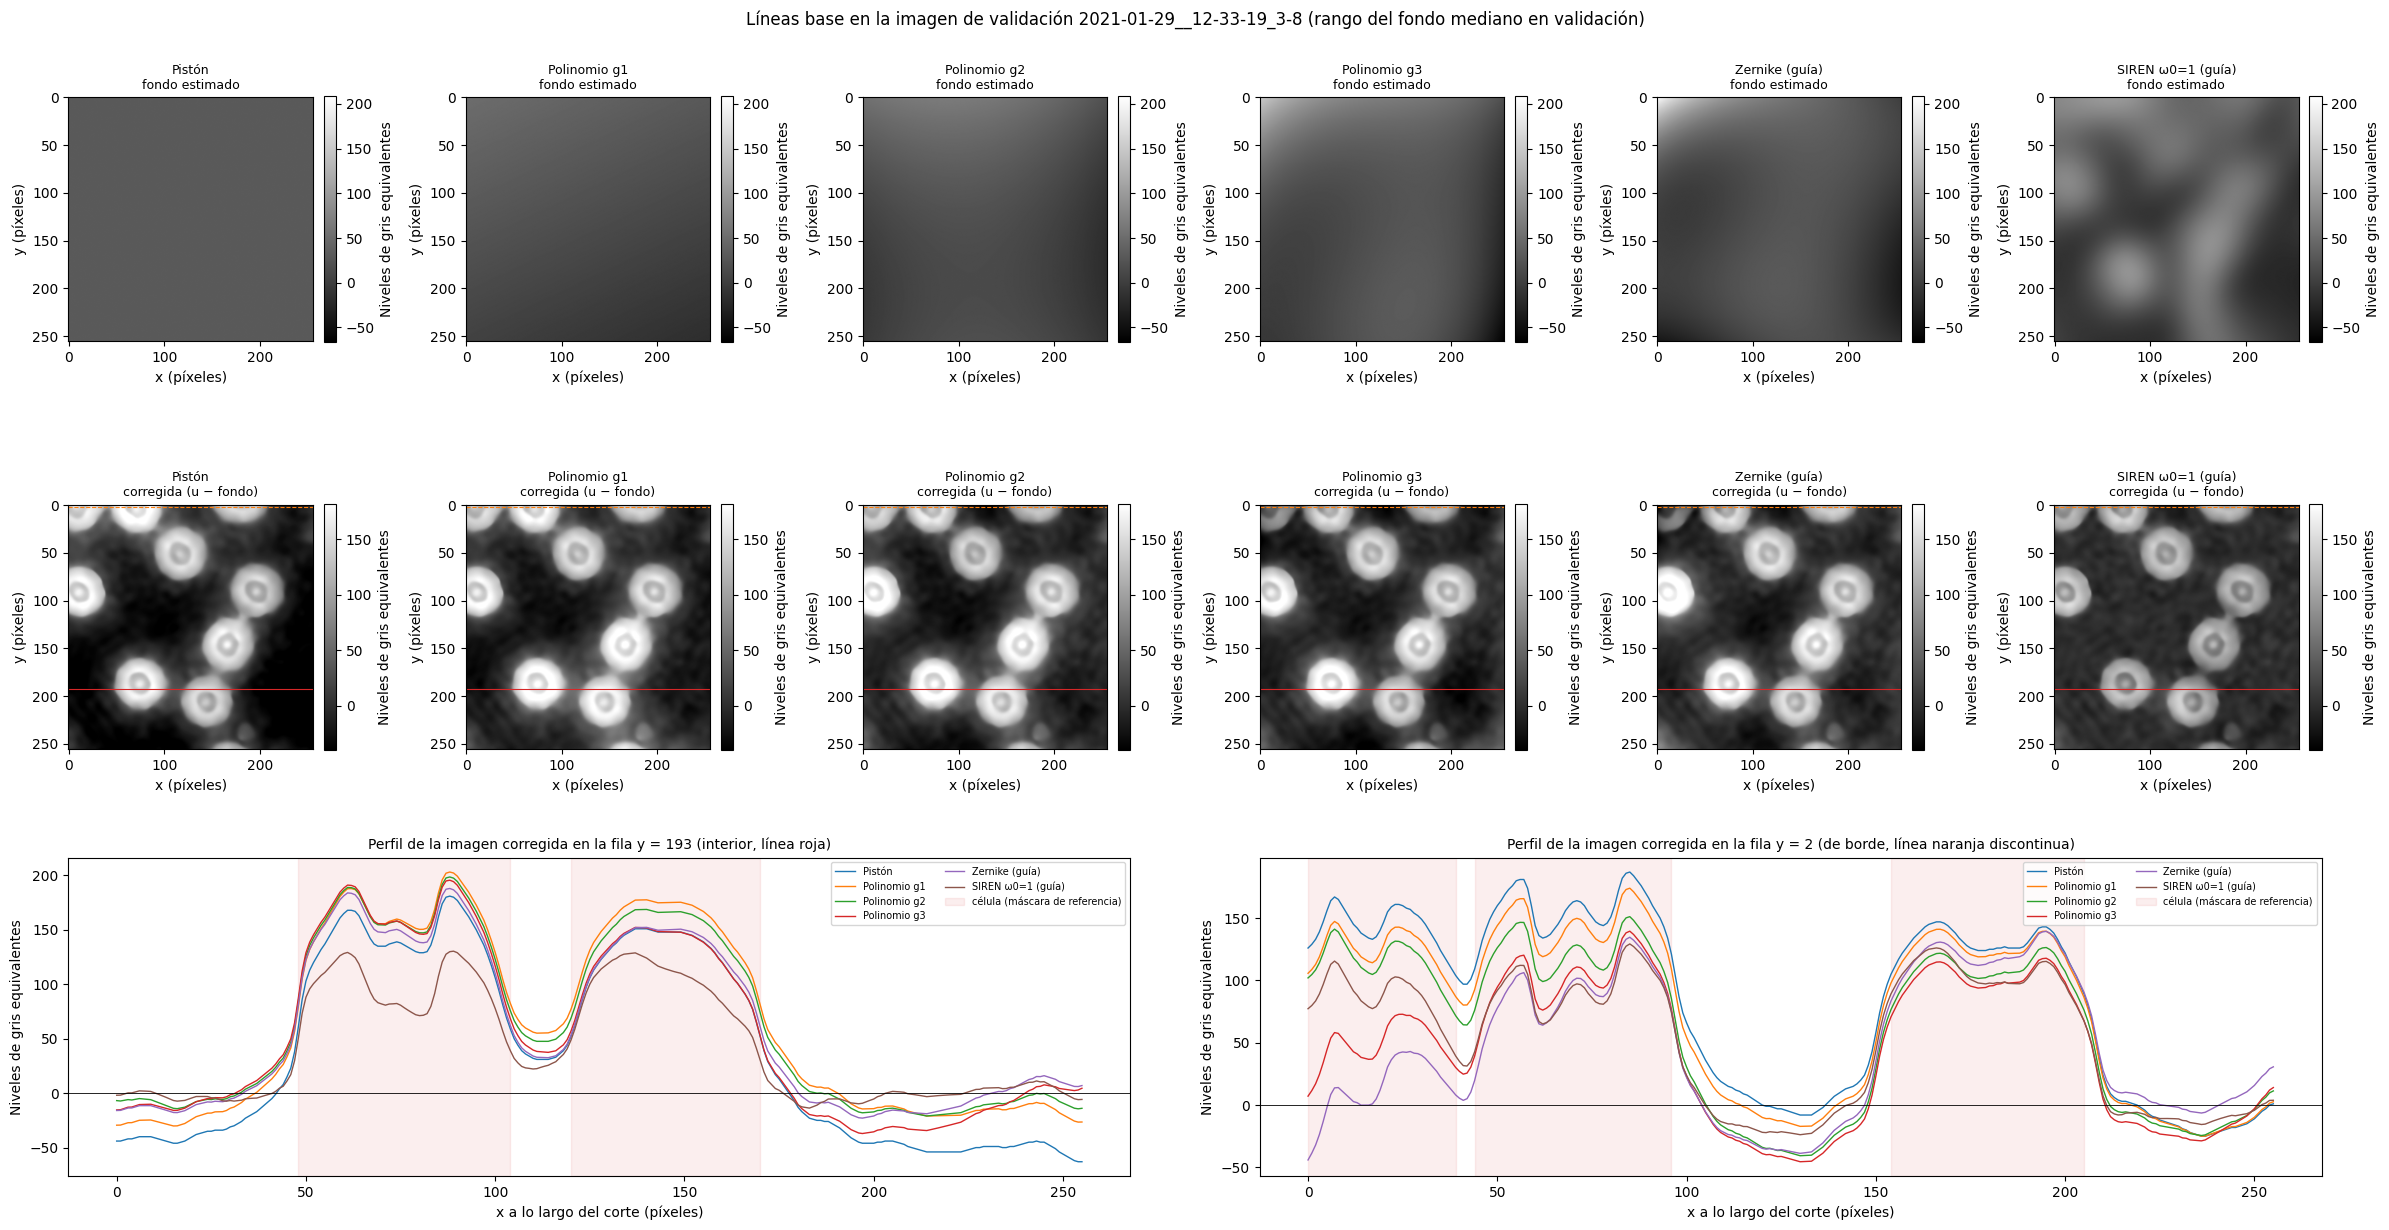

In [44]:
# 5.3.1 Fondo estimado, imagen corregida y perfiles (interior y borde) de cada línea base en una imagen de validación
_val = METRICAS_SEL[METRICAS_SEL.conjunto == "validacion"].sort_values("fondo_rango_ng").reset_index(drop=True)
archivo_lb = _val.archivo.iloc[(len(_val) - 1) // 2]          # rango del fondo mediano en validación
u_lb = PREPROCESADAS[archivo_lb]; cel_lb = MASCARAS[archivo_lb][0]
fondos_lb = LINEAS_BASE[archivo_lb]["fondos"]
H_lb = u_lb.shape[0]; MARGEN_INT, ANCHO_BORDE = 32, 16
cel_por_fila = cel_lb.sum(axis=1)                              # la máscara solo elige las filas de los perfiles
y_int = MARGEN_INT + int(np.argmax(cel_por_fila[MARGEN_INT:H_lb - MARGEN_INT]))
filas_borde = np.r_[0:ANCHO_BORDE, H_lb - ANCHO_BORDE:H_lb]
y_bor = int(filas_borde[np.argmax(cel_por_fila[filas_borde])])
print(f"Imagen: {archivo_lb}  |  fila interior y = {y_int}  |  fila de borde y = {y_bor}")

bmin = min(float(b.min()) for b in fondos_lb.values()); bmax = max(float(b.max()) for b in fondos_lb.values())
vmax_lb = float(np.percentile(u_lb - np.median(u_lb), 99.5))
n = len(METODOS_LB)
fig, ax = plt.subplot_mosaic([[f"b{j}" for j in range(n)], [f"v{j}" for j in range(n)], ["pi"] * (n // 2) + ["pb"] * (n - n // 2)],
                             figsize=(24, 12.5), gridspec_kw={"height_ratios": [1, 1, 0.9]})
for j, m in enumerate(METODOS_LB):
    v = u_lb - fondos_lb[m]
    im = ax[f"b{j}"].imshow(fondos_lb[m], vmin=bmin, vmax=bmax)
    ax[f"b{j}"].set_title(f"{m}\nfondo estimado", fontsize=9); barra_color(im, ax[f"b{j}"], "Niveles de gris equivalentes")
    im = ax[f"v{j}"].imshow(v, vmin=-40, vmax=vmax_lb)
    ax[f"v{j}"].axhline(y_int, color="tab:red", lw=0.8); ax[f"v{j}"].axhline(y_bor, color="tab:orange", lw=0.8, ls="--")
    ax[f"v{j}"].set_title(f"{m}\ncorregida (u − fondo)", fontsize=9); barra_color(im, ax[f"v{j}"], "Niveles de gris equivalentes")
    for fila in ("b", "v"):
        ax[f"{fila}{j}"].set_xlabel("x (píxeles)"); ax[f"{fila}{j}"].set_ylabel("y (píxeles)")
    ax["pi"].plot(v[y_int], lw=1, label=m); ax["pb"].plot(v[y_bor], lw=1, label=m)
for clave, y, nombre in (("pi", y_int, "interior, línea roja"), ("pb", y_bor, "de borde, línea naranja discontinua")):
    ax[clave].fill_between(np.arange(u_lb.shape[1]), 0, 1, where=cel_lb[y], transform=ax[clave].get_xaxis_transform(),
                           color="tab:red", alpha=0.08, label="célula (máscara de referencia)")
    ax[clave].axhline(0, color="k", lw=0.6)
    ax[clave].set_xlabel("x a lo largo del corte (píxeles)"); ax[clave].set_ylabel("Niveles de gris equivalentes")
    ax[clave].set_title(f"Perfil de la imagen corregida en la fila y = {y} ({nombre})", fontsize=10)
    ax[clave].legend(fontsize=7, ncol=2)
fig.suptitle(f"Líneas base en la imagen de validación {archivo_lb[7:-4]} (rango del fondo mediano en validación)")
fig.tight_layout(); plt.show()
guardar_figura(fig, "LB", "lineas_base_validacion")

**Lectura de la salida (5.3).** Imagen de validación `12-33-19_3-8`. Las posiciones son aproximadas, leídas de la figura.

**Fondos estimados (fila superior):**
- El pistón es una constante y el polinomio de grado 1, un plano inclinado.
- Los polinomios de grado 2 y 3 y el Zernike son superficies suaves con la esquina superior izquierda más alta. Ese aumento crece con la flexibilidad del método (grado 3 y Zernike), en una zona con células cortadas por el borde. Es consistente con el efecto de borde observado en 4.6.
- **El fondo de la SIREN tiene manchas donde hay células.** Por ejemplo, alrededor de $(x, y) \approx (80, 185)$ y $(15, 95)$, posiciones de células en la imagen corregida, y una banda diagonal que pasa por las células de la derecha. La SIREN está copiando parte de las células al fondo. Por eso, en su imagen corregida las células se ven claramente más tenues (gris medio) que en las demás columnas (casi blancas). Es la confirmación visual, ahora en una imagen de validación, de la absorción detectada en 4.6.

**Imágenes corregidas (fila central).** Todas dejan oscuro el fondo entre células. En el interior, las diferencias entre el plano, los polinomios y el Zernike son pequeñas a simple vista.

**Perfil interior ($y = 193$).**
- *Fondo a los lados de las células.*
  - El pistón queda entre −35 y −60 niveles: solo resta la mediana global, que incluye las células, y no corrige la inclinación.
  - El polinomio de grado 1 queda entre −10 y −30.
  - Los de grado 2 y 3 y el Zernike, entre −30 y +15.
  - La SIREN es el más plano, cerca de 0 (±5).
- *Células.* En la de la izquierda ($x \approx 48$–104), el máximo es ~180 con el pistón, ~185–203 con los polinomios y el Zernike, y ~130 con la SIREN. En la de la derecha ($x \approx 120$–170), ~150–178 frente a ~128 con la SIREN, que además cae hasta ~70 hacia $x \approx 165$. La SIREN deja el fondo más plano a costa de quitarle entre 30 y 50 niveles a las células: es el compromiso entre fondo y célula.
- Entre el pistón, los polinomios y el Zernike, las alturas difieren entre 10 y 20 niveles. Sin verdad conocida no se puede decir cuál es la correcta; por eso la métrica de la sección 6 es local.

**Perfil de borde ($y = 2$).**
- En la esquina superior izquierda ($x < 40$), el Zernike deja la célula cortada entre −45 y +43 niveles y el polinomio de grado 3 entre 8 y 73: unos 100–120 niveles por debajo del pistón (125–165). Es el efecto de borde de los ajustes más flexibles, consistente con su fondo estimado más alto en esa esquina.
- Entre células ($x \approx 110$–145), los polinomios de grado 2 y 3 y el Zernike dejan el fondo entre −35 y −45 niveles, frente a −20 de la SIREN y ≈ 0 del pistón: en el borde sobrecorrigen.
- *Implicación para la evaluación.* Las células cortadas por el borde no entran en la métrica de preservación (6.1), así que los efectos de borde se verán sobre todo en la métrica del fondo.

## 6. Protocolo de evaluación y métricas  *(lineamiento C · objetivo específico 3)*

Esta sección fija **cómo** se mide todo lo que sigue:
- 6.1 define las métricas, con un ejemplo numérico de cada una;
- 6.2 las verifica con una imagen sintética de valores conocidos;
- 6.3 analiza qué tan estable es la referencia contra la que se mide;
- 6.4 evalúa las líneas base en validación y elige el grado del polinomio;
- 6.5 fija el criterio de éxito del modelo antes de entrenarlo.

### 6.0 Alcance, transparencia e hipótesis

- **Conjuntos.** Solo se usan entrenamiento (6.3) y validación (6.3 y 6.4). Prueba se evalúa una sola vez, en la sección 9, con estas mismas funciones.
- **Transparencia.** Al implementar esta sección, el código se probó sobre imágenes de desarrollo, incluida validación, con una versión preliminar de las métricas: se vieron valores del pistón y de los polinomios y la comparación de máscaras entre grados. Ahí apareció el problema que motivó cambiar la métrica principal del fondo (Definición 13): en `13-11-36_1-12` el ajuste robusto de grado 2 no converge (su $\hat\sigma$ sigue bajando en la última iteración) y deja sin explicar parte del fondo. En consecuencia:
  1. 6.3 se plantea como un análisis **descriptivo**, sin hipótesis.
  2. Las hipótesis se limitan a los métodos del código guía (L2 y L3), cuyas métricas locales no se habían calculado.
  3. La regla para elegir el grado usa la métrica de fondo lento, que no se había calculado sobre imágenes de validación.

| ID | Hipótesis | Criterio de aceptación | Sección |
|---|---|---|---|
| H6.1 | Medida localmente, la compensación Zernike del código guía preserva la célula: la caída de 18–23 % de 4.6 se debía sobre todo a la métrica global | $\lvert\Delta h\rvert$ mediana < 5 % en validación | 6.4 |
| H6.2 | La SIREN del código guía absorbe parte de la célula, aun medida localmente | $\Delta h$ mediana < −10 % en validación | 6.4 |
| H6.3 | La SIREN, más flexible, deja menos fondo lento que el Zernike: hay un compromiso entre fondo y célula | RMS lento mediano de L3 < el de L2 en validación | 6.4 |

### 6.1 Definiciones de las métricas

**Notación.** $u$ es la imagen preprocesada (3.11); $v = u - \hat b$, la imagen corregida; $C$ y $B$, las máscaras de referencia de célula y de fondo (3.10); $\sigma$, el $\sigma_{\text{ruido}}$ de la imagen (3.9). Todo en niveles de gris equivalentes.

> **Definición 12 (células evaluables y su anillo).** Sean $C_1, \dots, C_n$ las componentes conexas de $C$ y $D_r(\cdot)$ la dilatación con $r$ iteraciones. La célula $C_j$ es **evaluable** si cumple tres condiciones: tiene al menos 600 píxeles, está a 16 píxeles o más del borde y su anillo
> $$R_j = D_{16}(C_j) \cap B$$
> conserva al menos la mitad de $D_{16}(C_j) \setminus D_6(C_j)$. $R_j$ es el fondo cercano a la célula: de 6 a 16 píxeles de su borde y lejos de las demás células.

> **Definición 13 (M1, fondo lento residual: métrica principal del fondo).** Sea $G$ un núcleo gaussiano de $\sigma_s = 8$ píxeles. Se definen
> $$\tilde v = \frac{G * (v\,\mathbb 1_B)}{G * \mathbb 1_B}, \qquad \mathrm{RMS}_{\text{lento}} = \sqrt{\operatorname{media}_{p \in B'}\ \tilde v(p)^2}, \qquad B' = \{p \in B : (G * \mathbb 1_B)(p) > 0{,}5\}.$$
> $\tilde v$ es el promedio local del residuo usando **solo** píxeles de fondo. Valor ideal: 0.

**¿Por qué no $\mathrm{RMS}_B/\sigma_{\text{ruido}}$, como en 4.6?**
1. Un fondo suave no puede quitar el ruido blanco. El piso de $\mathrm{RMS}_B$ es el ruido, y un valor por debajo de ese piso no es mejor sino ambiguo: o el método copia textura, o $\sigma_{\text{ruido}}$ está subestimado.
2. $\sigma_{\text{ruido}}$ sale del ajuste de grado 2, y ese ajuste no siempre converge (6.0, 6.3).

El suavizado elimina casi todo el ruido. Para ruido blanco de desviación $\sigma$, el promedio gaussiano tiene desviación $\approx \sigma / (2\sqrt\pi\,\sigma_s)$. *Ejemplo:* con $\sigma = 14$ y $\sigma_s = 8$, queda $14/(2\sqrt\pi \cdot 8) \approx 0{,}49$ niveles. Lo que quede por encima de ese piso es fondo lento sin corregir. La escala de 8 píxeles está entre la del ruido (1 píxel) y la de una célula (~40 píxeles de diámetro). $\mu_B$, $\sigma_B$ y $\mathrm{RMS}_B/\sigma_{\text{ruido}}$ se siguen reportando como métricas descriptivas.

> **Definición 14 (M2, altura local y su cambio: métrica principal de preservación).** Para cada célula evaluable,
> $$h_j(w) = \operatorname{media}_{C_j} w \;-\; \operatorname{media}_{R_j} w, \qquad \Delta h_j = \frac{h_j(v) - h_j(u)}{h_j(u)}.$$
> Por imagen se reportan la mediana de $\Delta h_j$, con signo (negativo: la célula pierde altura), y la de $\lvert\Delta h_j\rvert$. Valor ideal: 0.

> **Proposición 5 (la altura local ignora los errores afines del fondo).** Sea $e = \hat b - b$ el error de estimación del fondo. Si en $C_j \cup R_j$ el error es afín, $e(\mathbf x) = e_0 + \mathbf g \cdot \mathbf x$, entonces
> $$h_j(u - \hat b) = h_j(u - b) - \mathbf g \cdot \big(\bar{\mathbf x}_{C_j} - \bar{\mathbf x}_{R_j}\big),$$
> donde $\bar{\mathbf x}$ denota el centroide. Si el anillo rodea a la célula de forma simétrica ($\bar{\mathbf x}_{R_j} = \bar{\mathbf x}_{C_j}$), $h_j$ no depende del error afín.
>
> *Prueba.* La media de una función afín sobre un conjunto es su valor en el centroide del conjunto: $\operatorname{media}_{C_j} e = e_0 + \mathbf g \cdot \bar{\mathbf x}_{C_j}$ y $\operatorname{media}_{R_j} e = e_0 + \mathbf g \cdot \bar{\mathbf x}_{R_j}$. Como $h_j(u - \hat b) = h_j(u - b) - h_j(e)$, al restar ambas medias se obtiene el resultado. $\blacksquare$

**Consecuencia.** La inclinación del fondo no cambia la altura local, así que $\Delta h$ ya no castiga que se quite legítimamente la pendiente. Era el defecto de la métrica global de 4.6. Lo que no se cancela es la **curvatura** del fondo.

*Ejemplo numérico.* Sea un fondo cuadrático $b = a\,r^2$ centrado en una célula de radio 20 píxeles, con anillo de 26 a 36 píxeles. La media de $r^2$ vale $20^2/2 = 200$ en el disco y $(26^2 + 36^2)/2 = 986$ en el anillo. Si el fondo sube 100 niveles del centro de la imagen a su borde (128 píxeles), $a = 100/128^2 \approx 0{,}0061$. La corrección legítima cambia entonces la altura en $0{,}0061 \times (986 - 200) \approx 4{,}8$ niveles, un ~3 % de una célula de 150 niveles. De ahí el umbral $\lvert\Delta h\rvert < 5\,\%$.

> **Definición 15 (M3, soporte y morfología: métrica secundaria).** Sea $S(v) = \operatorname{relleno}\big(\operatorname{apertura}(v > 4\sigma)\big)$, con la misma limpieza que las máscaras de 3.5. Se definen
> $$\mathrm{Dice} = \frac{2\,\lvert S \cap C\rvert}{\lvert S\rvert + \lvert C\rvert}, \qquad \mathrm{IoU} = \frac{\lvert S \cap C\rvert}{\lvert S \cup C\rvert}.$$
> Mide si lo que sobresale de un fondo en 0 coincide con las células: un desplazamiento o una inclinación residual del fondo los bajan. Para L1 con $d = 2$ valen 1 por construcción.

**M4, correlación de perfiles (solo descriptiva).** $\rho_j = \operatorname{corr}_{C_j}(v, u)$. No cambia si la célula se escala, de modo que una absorción proporcional no la mueve; además compara con $u$, que todavía contiene el fondo. 6.2 lo muestra, y por eso no entra en ningún criterio. Los **perfiles por cortes** se comparan de forma cualitativa en la sección 9.2.

| Métrica | Qué mide | Valor ideal | Papel |
|---|---|---|---|
| M1 $\mathrm{RMS}_{\text{lento}}$ | Fondo lento sin corregir | 0 (piso ≈ 0,5 por el ruido) | **Principal: fondo** |
| M2 $\Delta h$, $\lvert\Delta h\rvert$ | Cambio de la altura local de cada célula | 0 | **Principal: célula** |
| M3 Dice, IoU | Coincidencia del soporte con las células | 1 | Secundaria |
| M4 correlación | Forma dentro de la célula | 1 | Descriptiva |
| $\mu_B$, $\sigma_B$, $\mathrm{RMS}_B/\sigma_{\text{ruido}}$ | Fondo total, ruido incluido | 0, $\sigma$, 1 | Descriptivas |

### 6.2 Implementación y verificación con valores conocidos

La imagen sintética tiene 256×256 píxeles:
- un fondo polinomial, con inclinación y curvatura;
- cinco células en forma de dona, de 120 niveles en el centro y 180 en el borde;
- ruido gaussiano de $\sigma = 14$, del orden del ruido real (3.9).

Se prueban cinco casos con resultado conocido. Los criterios se derivan de la teoría y se fijan antes de ejecutar:

| Caso | Imagen corregida $v$ | Qué debe pasar |
|---|---|---|
| C1 Corrección exacta | $u - b$ | $\mathrm{RMS}_{\text{lento}} < 1$ (piso ≈ 0,5); $\lvert\Delta h\rvert < 1\,\%$ (solo la curvatura, Proposición 5); Dice ≥ 0,95 |
| C2 Pistón | $u - \operatorname{mediana}(u)$ | $\mathrm{RMS}_{\text{lento}} > 10$: el fondo sigue ahí |
| C3 Absorción del 40 % | $u - b - 0{,}4\,\text{célula}$ | $\Delta h$ entre −42 % y −38 % y $\mathrm{RMS}_{\text{lento}} < 1$: el fondo es perfecto y solo M2 detecta el problema |
| C4 Inclinación residual | $u - b + 30x$ | $\Delta h$ idéntico al de C1 (Proposición 5) y $\mathrm{RMS}_{\text{lento}} > 10$ |
| C5 Desplazamiento | $u - b + 30$ | $\mu_B$ y $\mathrm{RMS}_{\text{lento}}$ ≈ 30 y $\Delta h$ idéntico al de C1 |

In [45]:
# 6.2.1 Implementación de las métricas M1–M4 (sección 6.1)
R_INT, R_EXT, AREA_MIN, SIGMA_SUAVE = 6, 16, 600, 8

def celulas_evaluables(cel: np.ndarray, fon: np.ndarray) -> list:
    """Definición 12: componentes de la máscara de células con área ≥ AREA_MIN, a ≥ R_EXT píxeles del borde y con al menos
    la mitad de su anillo [R_INT, R_EXT] dentro de la región de fondo. Devuelve una lista de pares (célula, anillo)."""
    lab, n = ndi.label(cel)
    salida = []
    for j in range(1, n + 1):
        cj = lab == j
        if cj.sum() < AREA_MIN:
            continue
        ys, xs = np.nonzero(cj)
        if ys.min() < R_EXT or xs.min() < R_EXT or ys.max() >= cel.shape[0] - R_EXT or xs.max() >= cel.shape[1] - R_EXT:
            continue
        ext = ndi.binary_dilation(cj, iterations=R_EXT)
        anillo_completo = ext & ~ndi.binary_dilation(cj, iterations=R_INT)
        anillo = ext & fon
        if anillo.sum() >= 0.5 * anillo_completo.sum():
            salida.append((cj, anillo))
    return salida

def fondo_lento(v: np.ndarray, fon: np.ndarray, sigma: float = SIGMA_SUAVE):
    """Definición 13: promedio gaussiano normalizado de v usando solo píxeles de fondo. Devuelve (mapa, píxeles válidos)."""
    num = ndi.gaussian_filter(np.where(fon, v, 0.0), sigma)
    den = ndi.gaussian_filter(fon.astype(float), sigma)
    valido = fon & (den > 0.5)
    return np.where(valido, num / np.maximum(den, 1e-12), np.nan), valido

def soporte(v: np.ndarray, sigma: float) -> np.ndarray:
    """Definición 15: v > 4σ_ruido, con la misma limpieza morfológica que las máscaras de 3.5."""
    return ndi.binary_fill_holes(ndi.binary_opening(v > 4 * sigma, iterations=2))

def metricas_imagen(v, u, cel, fon, sigma, celulas) -> dict:
    """Métricas de la imagen corregida v frente a la preprocesada u (niveles de gris equivalentes)."""
    lento, valido = fondo_lento(v, fon)
    vb = v[fon]
    dh, corr = [], []
    for cj, rj in celulas:
        h_u = u[cj].mean() - u[rj].mean()
        h_v = v[cj].mean() - v[rj].mean()
        dh.append((h_v - h_u) / h_u)
        corr.append(np.corrcoef(v[cj], u[cj])[0, 1])
    d = dice(soporte(v, sigma), cel)
    return {"RMS lento (niveles eq.)": float(np.sqrt(np.mean(lento[valido] ** 2))),
            "Δh mediana (%)": 100 * float(np.median(dh)) if dh else np.nan,
            "|Δh| mediana (%)": 100 * float(np.median(np.abs(dh))) if dh else np.nan,
            "μ_B": float(vb.mean()), "σ_B": float(vb.std()), "RMS_B/σ_ruido": float(np.sqrt(np.mean(vb ** 2)) / sigma),
            "Dice": d, "IoU": d / (2 - d),
            "correlación mediana": float(np.median(corr)) if corr else np.nan,
            "células evaluadas": len(celulas)}

def imagen_sintetica(semilla: int = SEED):
    """Caso de valores conocidos: fondo polinomial + 5 células en forma de dona + ruido gaussiano σ = 14 (niveles eq.)."""
    rng = np.random.default_rng(semilla)
    fondo = 60 * _xx - 40 * _yy + 80 * _xx**2 + 50 * _xx * _yy - 60 * _yy**2
    Hs, Ws = _xx.shape
    Y, X = np.mgrid[0:Hs, 0:Ws]
    perfil = np.zeros((Hs, Ws)); cel = np.zeros((Hs, Ws), bool)
    for cy, cx in [(60, 70), (70, 180), (150, 120), (190, 60), (200, 200)]:
        r = np.hypot(Y - cy, X - cx); disco = r <= 20
        perfil[disco] = 120 + 60 * (r[disco] / 20) ** 2          # dona: 120 en el centro, 180 en el borde
        cel |= disco
    u = fondo + perfil + rng.normal(0, 14, (Hs, Ws))
    return u, fondo, perfil, cel, ~ndi.binary_dilation(cel, iterations=R_INT)

SIGMA_RUIDO = dict(zip(FONDO.archivo, FONDO["σ_ruido (niveles eq.)"]))
CELULAS_EVAL = {f: celulas_evaluables(*MASCARAS[f]) for f in MASCARAS}     # solo depende de las máscaras de referencia

def metricas_archivo(v: np.ndarray, archivo: str) -> dict:
    """Métricas de una imagen corregida del dataset con su referencia (3.9, 3.10)."""
    cel, fon = MASCARAS[archivo]
    return metricas_imagen(v, PREPROCESADAS[archivo], cel, fon, SIGMA_RUIDO[archivo], CELULAS_EVAL[archivo])

conteo_cel = pd.DataFrame({"conjunto": [conjunto_de[f] for f in CELULAS_EVAL], "células evaluables": [len(c) for c in CELULAS_EVAL.values()]})
print("Células evaluables por imagen (Definición 12):")
display(conteo_cel.groupby("conjunto")["células evaluables"].agg(["sum", "min", "median", "max"]).reindex(ORDEN_CONJUNTOS))

Células evaluables por imagen (Definición 12):


,sum,min,median,max
conjunto,,,,
entrenamiento,32,1,2.5,4
validacion,12,1,3.0,3
prueba,12,2,2.0,3
generalizacion,12,0,1.0,3


,RMS lento (niveles eq.),Δh mediana (%),|Δh| mediana (%),μ_B,σ_B,RMS_B/σ_ruido,Dice,IoU,correlación mediana,células evaluadas
C1 corrección exacta,0.564,0.289,0.289,-0.047,14.056,1.004,1.000,1.000,0.935,5.0
C2 pistón,56.489,0.000,0.000,-4.933,58.558,4.198,0.670,0.504,1.000,5.0
C3 absorción del 40 %,0.564,-39.748,39.748,-0.047,14.056,1.004,0.999,0.998,0.906,5.0
C4 inclinación residual,17.888,0.289,0.289,0.017,22.805,1.629,1.000,1.000,0.965,5.0
C5 desplazamiento de +30,29.961,0.289,0.289,29.953,14.056,2.363,0.999,0.999,0.935,5.0


✔ C1: RMS lento < 1 nivel, |Δh| < 1 % y Dice ≥ 0,95
✔ C2: RMS lento > 10 niveles
✔ C3: Δh entre −42 % y −38 % y RMS lento < 1 nivel
✔ C4: Δh igual al de C1 (Proposición 5) y RMS lento > 10 niveles
✔ C5: μ_B y RMS lento entre 29 y 31 niveles, Δh igual al de C1
Correlación mediana: C1 = 0.935 frente a C3 = 0.906


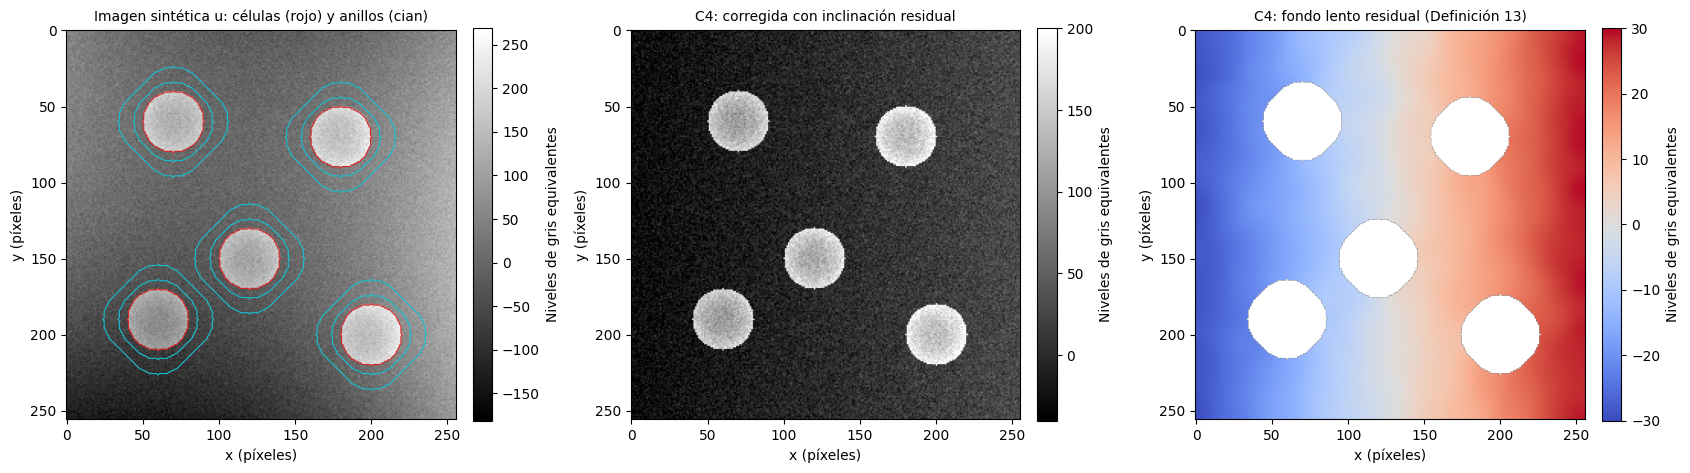

In [46]:
# 6.2.2 Verificación con valores conocidos (casos C1–C5)
u_s, fondo_s, perfil_s, cel_s, fon_s = imagen_sintetica()
cels_s = celulas_evaluables(cel_s, fon_s)
CASOS = {"C1 corrección exacta": u_s - fondo_s,
         "C2 pistón": u_s - np.median(u_s),
         "C3 absorción del 40 %": u_s - fondo_s - 0.4 * perfil_s,
         "C4 inclinación residual": u_s - fondo_s + 30 * _xx,
         "C5 desplazamiento de +30": u_s - fondo_s + 30}
P6 = pd.DataFrame({k: metricas_imagen(v, u_s, cel_s, fon_s, 14.0, cels_s) for k, v in CASOS.items()}).T
guardar_tabla(P6, "M6_prueba_sintetica", index=True)
display(P6.astype(float).round(3))

c1, c2, c3, c4, c5 = CASOS
L, DH, ADH = "RMS lento (niveles eq.)", "Δh mediana (%)", "|Δh| mediana (%)"
comprobaciones = {
    "C1: RMS lento < 1 nivel, |Δh| < 1 % y Dice ≥ 0,95": P6.loc[c1, L] < 1 and P6.loc[c1, ADH] < 1 and P6.loc[c1, "Dice"] >= 0.95,
    "C2: RMS lento > 10 niveles": P6.loc[c2, L] > 10,
    "C3: Δh entre −42 % y −38 % y RMS lento < 1 nivel": -42 < P6.loc[c3, DH] < -38 and P6.loc[c3, L] < 1,
    "C4: Δh igual al de C1 (Proposición 5) y RMS lento > 10 niveles": abs(P6.loc[c4, DH] - P6.loc[c1, DH]) < 0.01 and P6.loc[c4, L] > 10,
    "C5: μ_B y RMS lento entre 29 y 31 niveles, Δh igual al de C1":
        29 < P6.loc[c5, "μ_B"] < 31 and 29 < P6.loc[c5, L] < 31 and abs(P6.loc[c5, DH] - P6.loc[c1, DH]) < 0.01,
}
for k, ok in comprobaciones.items():
    print("✔" if ok else "✘", k)
assert all(comprobaciones.values()), "Alguna métrica no se comporta como predice la teoría"
print(f"Correlación mediana: C1 = {P6.loc[c1, 'correlación mediana']:.3f} frente a C3 = {P6.loc[c3, 'correlación mediana']:.3f}")

anillos_s = np.any([a for _, a in cels_s], axis=0)
lento_c4, _ = fondo_lento(CASOS[c4], fon_s)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
im = ax[0].imshow(u_s); ax[0].contour(cel_s, [0.5], colors="tab:red", linewidths=0.8)
ax[0].contour(anillos_s, [0.5], colors="tab:cyan", linewidths=0.8)
ax[0].set_title("Imagen sintética u: células (rojo) y anillos (cian)"); barra_color(im, ax[0], "Niveles de gris equivalentes")
im = ax[1].imshow(CASOS[c4], vmin=-40, vmax=200); ax[1].set_title("C4: corregida con inclinación residual")
barra_color(im, ax[1], "Niveles de gris equivalentes")
im = ax[2].imshow(lento_c4, cmap="coolwarm", vmin=-30, vmax=30); ax[2].set_title("C4: fondo lento residual (Definición 13)")
barra_color(im, ax[2], "Niveles de gris equivalentes")
for a in ax:
    a.set_xlabel("x (píxeles)"); a.set_ylabel("y (píxeles)")
fig.tight_layout(); plt.show()
guardar_figura(fig, "M6", "prueba_sintetica_metricas")

**Lectura de la salida (6.2).**
- **Las cinco comprobaciones se cumplen:**
  - **C1, corrección exacta.** El fondo lento queda en 0,56 niveles, cerca del piso teórico de 0,49. El $\Delta h$ de 0,29 % es solo el efecto de la curvatura del fondo sintético. Dice = 1,00.
  - **C2, pistón.** El fondo lento sube a 56,5 niveles: el fondo sigue ahí.
  - **C3, absorción del 40 %.** $\Delta h = -39{,}7\,\%$, con el fondo lento en 0,56, igual que en C1. **Una métrica del fondo, por sí sola, calificaría C3 como perfecta.** Por eso las dos métricas principales se usan juntas.
  - **C4, inclinación residual.** $\Delta h$ es idéntico al de C1 (0,289 %): la Proposición 5 se cumple numéricamente. El fondo lento, 17,9 niveles, sí detecta la inclinación; la figura la muestra como un gradiente de −30 a +30.
  - **C5, desplazamiento.** $\mu_B$ y el fondo lento valen ≈ 30 niveles, como se esperaba, y $\Delta h$ no cambia.
- **Las métricas descriptivas no distinguen los casos que importan:**
  - $\mathrm{RMS}_B/\sigma_{\text{ruido}}$ vale 1,00 tanto en C1 como en C3.
  - Dice vale 0,999 en C3: el soporte $v > 4\sigma$ (56 niveles) sigue cubriendo la célula aunque haya perdido el 40 % de su altura.
  - La correlación es **máxima (1,00) en el pistón**, que no corrige nada, y casi igual en C1 (0,935) y C3 (0,906).

  Esto confirma que M3 y M4 no pueden ser métricas principales.
- **Células evaluables.**
  - Entrenamiento: 32 en total, entre 1 y 4 por imagen.
  - Validación: 12. Prueba: 12.
  - Generalización: 12, con un mínimo de 0. Al menos una imagen de generalización no tiene células evaluables y su $\Delta h$ no estará definido; se tendrá en cuenta en la sección 10.

  Con una mediana de 2–3 células por imagen, el $\Delta h$ de cada imagen descansa en pocas células.

### 6.3 Sensibilidad de la referencia al grado del polinomio (decisión revisable 1 de 0.6)

Las máscaras de referencia y $\sigma_{\text{ruido}}$ salen de un ajuste robusto de grado 2. Aquí se rehacen con grados 1 y 3 en las 17 imágenes de entrenamiento y validación, y se mide:
- **Dice(C₂, C₁) y Dice(C₂, C₃):** cuánto cambian las células de referencia al cambiar el grado.
- **σ_ruido g1/g2 y g3/g2:** cuánto cambia el ruido estimado.
- **Consistencia del grado 2:** la desviación del residuo de grado 2 en la región de fondo, dividida por $\sigma_{\text{ruido}}$. Si el ajuste describe bien el fondo, debería valer ≈ 1. Un valor alto indica que el ajuste robusto se quedó con una parte de la imagen y dejó fondo sin explicar. Se señalan las imágenes con un valor mayor que 1,5.

El análisis es descriptivo (6.0). La celda comprueba primero, con un `assert`, que con grado 2 se reproducen exactamente las máscaras y el $\sigma_{\text{ruido}}$ de 3.9–3.10.

Dice(C₂, C₁)               Dice(C₂, C₃)                \
                    median    min    max       median    min    max   
conjunto                                                              
entrenamiento        0.960  0.935  0.988        0.965  0.901  0.985   
validacion           0.973  0.920  0.986        0.961  0.955  0.977   

              σ_ruido g1 / g2               σ_ruido g3 / g2                \
                       median    min    max          median    min    max   
conjunto                                                                    
entrenamiento           1.243  0.888  1.547           0.824  0.742  1.065   
validacion              1.235  1.126  2.213           0.821  0.754  1.053   

              consistencia g2                
                       median    min    max  
conjunto                                     
entrenamiento           0.980  0.870  2.050  
validacion              0.946  0.877  2.585

Imágenes donde el ajuste de grado 2 no describe bien el fondo (consistencia > 1,5):


,conjunto,archivo,"Dice(C₂, C₁)","Dice(C₂, C₃)",σ_ruido g1 / g2,σ_ruido g3 / g2,consistencia g2
0,entrenamiento,2021-01-29__12-29-32_4-11,0.936,0.944,1.547,0.867,1.622
3,entrenamiento,2021-01-29__13-04-29_1-7,0.964,0.970,1.316,1.065,2.050
15,validacion,2021-01-29__13-11-36_1-12,0.920,0.955,2.213,0.996,2.585


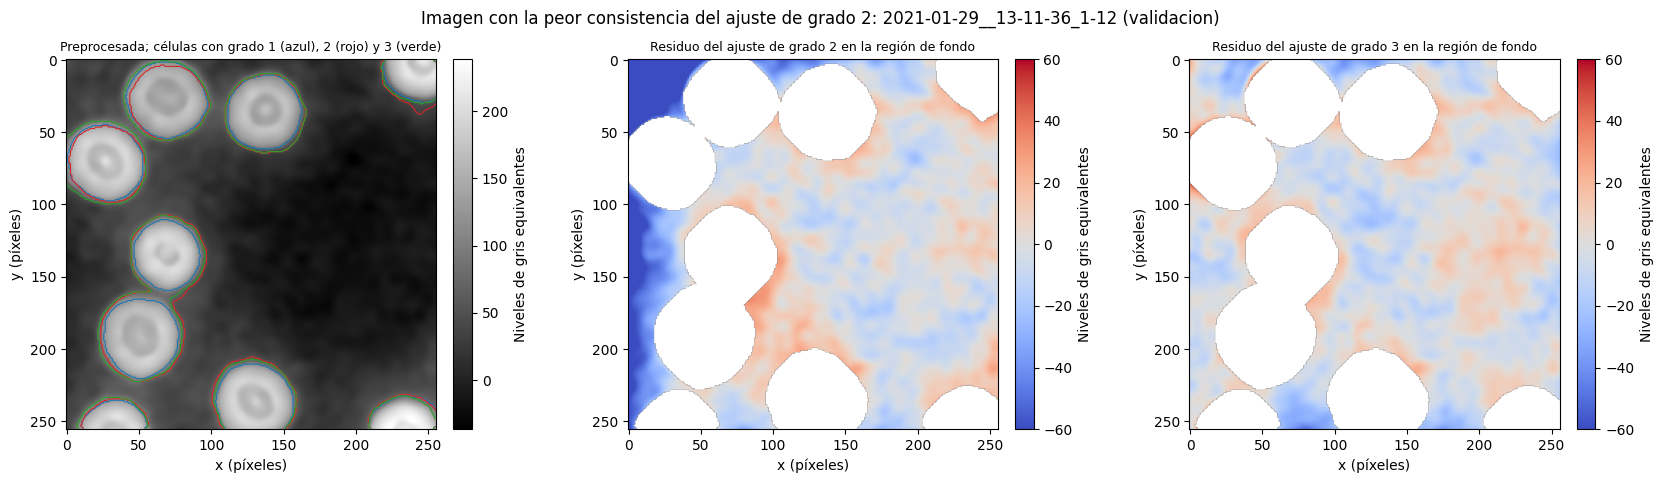

In [47]:
# 6.3.1 Sensibilidad de la referencia al grado del polinomio (entrenamiento y validación)
def ajuste_poli_residuo(phi: np.ndarray, grado: int, iteraciones: int = 8, k: float = 2.5):
    """Igual que ajuste_fondo_robusto (3.5), para cualquier grado. Devuelve (fondo, residuo, sigma)."""
    A = BASES_POLI[grado]; v = phi.ravel(); m = np.ones(v.size, bool)
    for _ in range(iteraciones):
        c = np.linalg.lstsq(A[m], v[m], rcond=None)[0]
        r = v - A @ c
        s = 1.4826 * np.median(np.abs(r[m] - np.median(r[m])))
        m = np.abs(r) < k * s
    return (A @ c).reshape(phi.shape), r.reshape(phi.shape), s

def referencia_grado(g: np.ndarray, grado: int, margen: int = 6):
    """Máscaras de referencia (3.10) y σ_ruido (3.9) construidas con un fondo polinomial del grado indicado."""
    _, res, s = ajuste_poli_residuo(desenvolver(g), grado)
    cel = mascara_celulas(res, s, -1)
    return cel, ~ndi.binary_dilation(cel, iterations=margen), s * NG_POR_RAD

filas = []
for f in ARCHIVOS_LB:
    refs = {d: referencia_grado(IMAGENES[f], d) for d in (1, 2, 3)}
    c2, b2, s2 = refs[2]
    assert np.array_equal(c2, MASCARAS[f][0]) and np.isclose(s2, SIGMA_RUIDO[f]), f"El grado 2 no reproduce la referencia de {f}"
    res2 = PREPROCESADAS[f] - ajuste_polinomial_robusto(PREPROCESADAS[f], 2)
    filas.append({"conjunto": conjunto_de[f], "archivo": f[7:-4],
                  "Dice(C₂, C₁)": dice(c2, refs[1][0]), "Dice(C₂, C₃)": dice(c2, refs[3][0]),
                  "σ_ruido g1 / g2": refs[1][2] / s2, "σ_ruido g3 / g2": refs[3][2] / s2,
                  "consistencia g2": float(res2[b2].std() / s2)})
SENS_REF = pd.DataFrame(filas)
guardar_tabla(SENS_REF, "M6_sensibilidad_referencia")
display(SENS_REF.drop(columns="archivo").groupby("conjunto").agg(["median", "min", "max"]).reindex(["entrenamiento", "validacion"]).round(3))
inconsistentes = SENS_REF[SENS_REF["consistencia g2"] > 1.5]
print("Imágenes donde el ajuste de grado 2 no describe bien el fondo (consistencia > 1,5):")
display(inconsistentes.round(3) if len(inconsistentes) else "ninguna")

# Figura: la imagen con la peor consistencia
f_peor = ARCHIVOS_LB[int(SENS_REF["consistencia g2"].values.argmax())]
u_p = PREPROCESADAS[f_peor]; b_p = MASCARAS[f_peor][1]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
im = ax[0].imshow(u_p); barra_color(im, ax[0], "Niveles de gris equivalentes")
for d, color in ((1, "tab:blue"), (2, "tab:red"), (3, "tab:green")):
    ax[0].contour(referencia_grado(IMAGENES[f_peor], d)[0], [0.5], colors=color, linewidths=0.8)
ax[0].set_title("Preprocesada; células con grado 1 (azul), 2 (rojo) y 3 (verde)", fontsize=9)
for a, d in zip(ax[1:], (2, 3)):
    r = u_p - ajuste_polinomial_robusto(u_p, d)
    im = a.imshow(np.where(b_p, r, np.nan), cmap="coolwarm", vmin=-60, vmax=60)
    a.set_title(f"Residuo del ajuste de grado {d} en la región de fondo", fontsize=9)
    barra_color(im, a, "Niveles de gris equivalentes")
for a in ax:
    a.set_xlabel("x (píxeles)"); a.set_ylabel("y (píxeles)")
fig.suptitle(f"Imagen con la peor consistencia del ajuste de grado 2: {f_peor[7:-4]} ({conjunto_de[f_peor]})")
fig.tight_layout(); plt.show()
guardar_figura(fig, "M6", "sensibilidad_referencia")

**Lectura de la salida (6.3).**
- **Las máscaras de referencia son robustas al grado.** El Dice mediano entre las máscaras de grado 2 y las de grado 1 o 3 está entre 0,96 y 0,97, con un mínimo de 0,90. En la figura, los contornos de los tres grados prácticamente coinciden, incluso en la peor imagen. Las regiones $C$ y $B$, que usan M1 y M2, casi no dependen del grado.
- **$\sigma_{\text{ruido}}$ no es robusto.** Al pasar a grado 1 aumenta un ~24 % en mediana (hasta 2,2 veces), y al pasar a grado 3 baja un ~18 %. Esto respalda la decisión de 6.1 de no usar $\sigma_{\text{ruido}}$ en las métricas principales. Lo que sí depende de él (el umbral $4\sigma$ del soporte y $\mathrm{RMS}_B/\sigma_{\text{ruido}}$) carga esa incertidumbre.
- **El grado 2 describe bien el fondo en la mayoría de las imágenes:** la consistencia mediana es 0,98 en entrenamiento y 0,95 en validación. En 3 de las 17 imágenes supera 1,5:
  - `12-29-32_4-11` (entrenamiento): 1,62.
  - `13-04-29_1-7` (entrenamiento): 2,05.
  - `13-11-36_1-12` (validación): 2,59.

  En la figura de la última, el residuo de grado 2 deja una franja de ≈ −60 niveles en el borde izquierdo y zonas de +20 a +30 en el centro, mientras que con grado 3 queda dentro de ±20. En esas imágenes el fondo tiene estructura que el grado 2 no captura y el grado 3 sí. `12-29-32_4-11` es la imagen con mayor rango del fondo usada en 4.6.

**Consecuencias:**
1. Se mantienen las máscaras de referencia.
2. La advertencia de 5.1 sobre la circularidad se acota: afecta a M3 y a las métricas con $\sigma_{\text{ruido}}$, no a M1 ni a M2.
3. Decisión revisable 12 (0.6): por ahora no se cambia el algoritmo de la referencia, porque las métricas principales no dependen de $\sigma_{\text{ruido}}$. Queda anotado.

### 6.4 Evaluación de las líneas base en validación y elección del grado

Se calculan las métricas de las seis líneas base de la sección 5 en las 5 imágenes de validación. En cada imagen, las métricas de célula son la mediana sobre sus células evaluables; entre imágenes se reporta la mediana. Con 5 imágenes no hay potencia para pruebas estadísticas, así que también se muestran los valores por imagen.

**Regla para el grado del polinomio (fijada antes de calcular).** Se elige el menor $d \in \{1, 2, 3\}$ que cumpla dos condiciones: $\lvert\Delta h\rvert$ mediana < 5 % y RMS lento mediano a no más de 2 niveles del mejor grado. Es una regla de parsimonia: si un grado menor es casi igual de bueno, se prefiere. Si ningún grado la cumple, se elige el de menor RMS lento. Advertencia: los grados 2 y 3 comparten el ajuste con la referencia (5.1).

In [48]:
# 6.4.1 Métricas de las líneas base en validación, hipótesis H6.1–H6.3 y elección del grado del polinomio
ARCHIVOS_VAL = SELECCION[SELECCION.conjunto == "validacion"].archivo.tolist()
EVAL_LB_VAL = pd.DataFrame([{"archivo": f[7:-4], "método": m,
                             **metricas_archivo(PREPROCESADAS[f] - LINEAS_BASE[f]["fondos"][m], f)}
                            for f in ARCHIVOS_VAL for m in METODOS_LB])
guardar_tabla(EVAL_LB_VAL, "LB_metricas_validacion_por_imagen")
L, DH, ADH = "RMS lento (niveles eq.)", "Δh mediana (%)", "|Δh| mediana (%)"
COLS_M = [L, DH, ADH, "μ_B", "σ_B", "RMS_B/σ_ruido", "Dice", "IoU", "correlación mediana"]
RESUMEN_LB_VAL = EVAL_LB_VAL.groupby("método")[COLS_M].median().loc[METODOS_LB]
RESUMEN_LB_VAL.insert(0, "comparte ajuste con la referencia", [m in ("Polinomio g2", "Polinomio g3") for m in METODOS_LB])
guardar_tabla(RESUMEN_LB_VAL, "LB_metricas_validacion", index=True)
print("Mediana sobre las 5 imágenes de validación:")
display(RESUMEN_LB_VAL.round(2))
print("Por imagen — RMS del fondo lento (niveles eq.):")
display(EVAL_LB_VAL.pivot(index="archivo", columns="método", values=L)[METODOS_LB].round(1))
print("Por imagen — Δh mediana (%) y número de células evaluadas:")
tabla_dh = EVAL_LB_VAL.pivot(index="archivo", columns="método", values=DH)[METODOS_LB].round(1)
tabla_dh["células evaluadas"] = EVAL_LB_VAL.groupby("archivo")["células evaluadas"].first()
display(tabla_dh)

r = RESUMEN_LB_VAL
H6_1 = bool(r.loc["Zernike (guía)", ADH] < 5)
H6_2 = bool(r.loc["SIREN ω0=1 (guía)", DH] < -10)
H6_3 = bool(r.loc["SIREN ω0=1 (guía)", L] < r.loc["Zernike (guía)", L])
for nombre, valor in (("H6.1", H6_1), ("H6.2", H6_2), ("H6.3", H6_3)):
    print(nombre + ":", "SE CUMPLE" if valor else "SE RECHAZA")

grados = ["Polinomio g1", "Polinomio g2", "Polinomio g3"]
mejor_lento = r.loc[grados, L].min()
aptos = [m for m in grados if r.loc[m, ADH] < 5 and r.loc[m, L] <= mejor_lento + 2]
GRADO_LB = aptos[0] if aptos else r.loc[grados, L].idxmin()
print(f"Grados aptos: {aptos}  →  línea base polinomial elegida: {GRADO_LB}")

Mediana sobre las 5 imágenes de validación:


,comparte ajuste con la referencia,RMS lento (niveles eq.),Δh mediana (%),|Δh| mediana (%),μ_B,σ_B,RMS_B/σ_ruido,Dice,IoU,correlación mediana
método,,,,,,,,,,
Pistón,False,22.63,0.00,0.00,-10.70,22.02,1.39,0.97,0.94,1.00
Polinomio g1,False,15.80,-0.01,0.26,-2.47,17.42,1.12,0.97,0.95,1.00
Polinomio g2,True,12.81,-0.22,0.98,-2.17,15.26,0.96,1.00,1.00,1.00
Polinomio g3,True,7.90,-1.14,1.37,-1.33,10.84,0.81,0.98,0.96,0.99
Zernike (guía),False,6.39,-2.55,2.55,0.42,9.71,0.75,0.97,0.95,0.99
SIREN ω0=1 (guía),False,3.54,-12.80,12.80,0.68,6.69,0.46,0.96,0.92,0.98


Por imagen — RMS del fondo lento (niveles eq.):


método,Pistón,Polinomio g1,Polinomio g2,Polinomio g3,Zernike (guía),SIREN ω0=1 (guía)
archivo,,,,,,
2021-01-29__12-33-19_3-8,27.4,15.8,12.8,12.8,10.9,4.0
2021-01-29__13-01-51_2-8,22.6,16.4,13.1,10.2,8.7,4.1
2021-01-29__13-05-53_3-6,13.8,11.7,8.5,6.2,5.1,3.2
2021-01-29__13-11-36_1-12,29.9,15.9,25.0,7.9,5.7,3.5
2021-01-29__13-26-28_4-11,17.6,12.1,10.6,7.8,6.4,3.5


Por imagen — Δh mediana (%) y número de células evaluadas:


método,Pistón,Polinomio g1,Polinomio g2,Polinomio g3,Zernike (guía),SIREN ω0=1 (guía),células evaluadas
archivo,,,,,,,
2021-01-29__12-33-19_3-8,0.0,0.2,-0.2,-0.2,-2.6,-26.5,3
2021-01-29__13-01-51_2-8,0.0,-0.2,-1.0,-1.1,-2.6,-9.2,3
2021-01-29__13-05-53_3-6,0.0,0.0,0.0,-1.0,-1.1,-9.3,2
2021-01-29__13-11-36_1-12,-0.0,-0.3,3.3,-2.5,-4.6,-12.8,1
2021-01-29__13-26-28_4-11,0.0,-0.0,-1.0,-1.8,-1.6,-14.9,3


H6.1: SE CUMPLE
H6.2: SE CUMPLE
H6.3: SE CUMPLE
Grados aptos: ['Polinomio g3']  →  línea base polinomial elegida: Polinomio g3


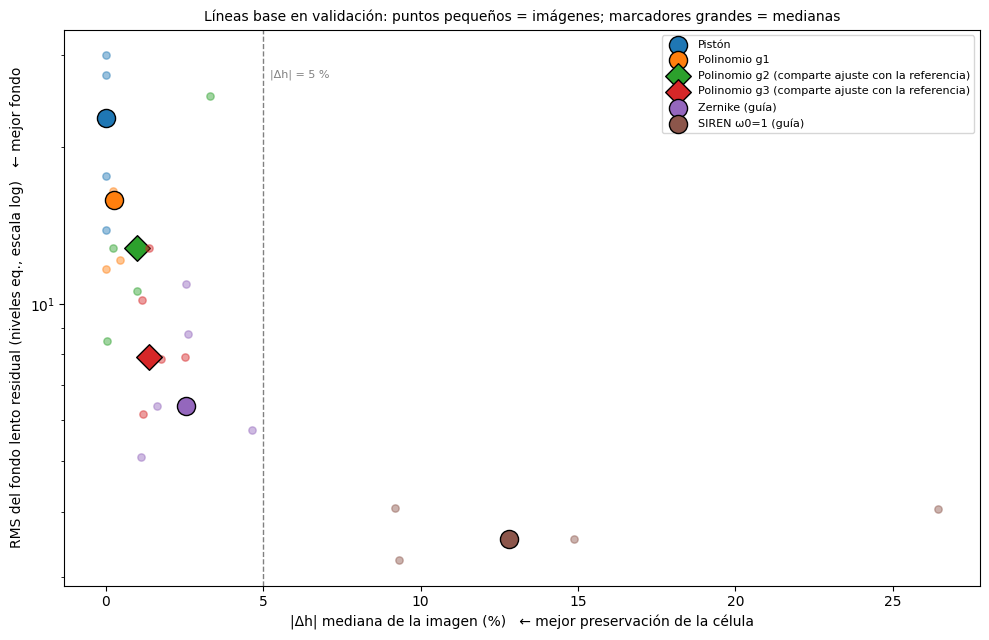

In [49]:
# 6.4.2 Figura: compromiso entre fondo lento residual y preservación de la célula en validación
fig, ax = plt.subplots(figsize=(10, 6.5))
for j, m in enumerate(METODOS_LB):
    t = EVAL_LB_VAL[EVAL_LB_VAL["método"] == m]
    circular = RESUMEN_LB_VAL.loc[m, "comparte ajuste con la referencia"]
    ax.scatter(t[ADH], t[L], color=f"C{j}", alpha=0.45, s=28)
    ax.scatter(RESUMEN_LB_VAL.loc[m, ADH], RESUMEN_LB_VAL.loc[m, L], color=f"C{j}", s=170, edgecolor="k",
               marker="D" if circular else "o", label=m + (" (comparte ajuste con la referencia)" if circular else ""))
ax.axvline(5, ls="--", color="gray", lw=1)
ax.text(5.2, ax.get_ylim()[1] * 0.9, "|Δh| = 5 %", color="gray", fontsize=8, va="top")
ax.set_yscale("log")
ax.set_xlabel("|Δh| mediana de la imagen (%)   ← mejor preservación de la célula")
ax.set_ylabel("RMS del fondo lento residual (niveles eq., escala log)   ← mejor fondo")
ax.set_title("Líneas base en validación: puntos pequeños = imágenes; marcadores grandes = medianas", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
guardar_figura(fig, "LB", "compromiso_fondo_celula_validacion")

**Lectura de la salida (6.4).** Medianas sobre las 5 imágenes de validación:

| Método | Fondo lento (niveles eq.) | $\lvert\Delta h\rvert$ (%) |
|---|---|---|
| Pistón | 22,6 | 0,00 |
| Polinomio g1 | 15,8 | 0,26 |
| Polinomio g2 | 12,8 | 0,98 |
| Polinomio g3 | 7,9 | 1,37 |
| Zernike (guía) | 6,4 | 2,55 |
| SIREN $\omega_0 = 1$ (guía) | 3,5 | 12,80 |

- **El compromiso entre fondo y célula ya está medido.** Cuanto más flexible es el método, menos fondo lento deja y más altura le quita a las células. En la figura, los métodos se ordenan de arriba a la izquierda hacia abajo a la derecha.
- **H6.1 se cumple.** El Zernike tiene un $\lvert\Delta h\rvert$ mediano de 2,55 % (entre 1,1 % y 4,6 % por imagen). Que en 4.6 la métrica global diera −18 a −23 % es consistente con que esa caída fuera sobre todo un artefacto de la métrica global; eran otras imágenes, así que no es una comparación directa. Aviso: en `13-11-36_1-12` llega a 4,6 %, cerca del umbral, con una sola célula evaluable.
- **H6.2 se cumple.** La SIREN tiene un $\Delta h$ mediano de −12,8 % (entre −9,2 % y −26,5 %). El peor caso es `12-33-19_3-8`, la imagen de 5.3, consistente con los 30–50 niveles que se leyeron en su perfil. Su $\mathrm{RMS}_B/\sigma_{\text{ruido}} = 0{,}46$, por debajo del piso del ruido: también ajusta textura, como en 4.6.
- **H6.3 se cumple.** La SIREN deja menos fondo lento que el Zernike en las 5 imágenes (3,2–4,1 frente a 5,1–10,9 niveles).
- **Grado del polinomio.** Solo el grado 3 cumple la regla: el umbral era 7,9 + 2 = 9,9 y el grado 2 dio 12,8. **La línea base polinomial es la de grado 3.** En `13-11-36_1-12`, el grado 2 deja 25,0 niveles de fondo lento, más que el grado 1 (15,9): es el ajuste que no converge, visto en 6.3.
- **Ni el mejor método está cerca del piso.** La SIREN deja 3,5 niveles, frente al piso de ~0,5 por el ruido: queda estructura lenta que ninguna línea base quita sin tocar las células.
- **Dice e IoU no discriminan entre líneas base:** valen entre 0,96 y 1,00 en todos los métodos.

**Límite:** son 5 imágenes con 1–3 células evaluables cada una (12 en total). Las conclusiones se expresan como "consistente con".

**Implicación para el modelo (criterio 6.5).** En validación, la mejor línea base que cumple $\lvert\Delta h\rvert \le 5\,\%$ es el Zernike: 6,4 niveles de fondo lento y 2,55 % de cambio de altura. **El espacio que el modelo debe ganar está entre el Zernike y la SIREN:** dejar tan poco fondo lento como la SIREN sin su absorción. La SIREN del código guía absorbe porque su pérdida ($L_1$ recortada sobre una fracción $\rho$ de los píxeles) no impide que la red ajuste las células. Las restricciones físicas de 4.2–4.3, en particular la esparsidad (S2) y el signo (S3), apuntan precisamente a eso. Ese es el punto de partida de la sección 7.

### 6.5 Criterio de éxito del modelo (fijado antes de entrenarlo)

Se evalúa en el conjunto de prueba (sección 9) con las métricas principales M1 y M2:
1. **Preservación:** $\lvert\Delta h\rvert$ mediana ≤ 5 %, la cota del cambio legítimo por curvatura (6.1).
2. **Fondo:** RMS lento mediano menor o igual que el de la mejor línea base que cumpla la condición 1, entre L0, L1 con el grado elegido en 6.4, L2 y L3.
3. **Consistencia:** se reporta en cuántas de las 5 imágenes de prueba el modelo supera a esa línea base en las dos métricas a la vez.

Con 5 imágenes, un resultado favorable se describirá como "consistente con una mejora" y no como una mejora demostrada. Este criterio puede ajustarse con el grupo **antes** de entrenar, nunca después de mirar prueba (0.6).

### 6.6 Contraste de las hipótesis de la sección 6

In [50]:
# 6.6 Resumen automático del contraste de hipótesis de la sección 6
contraste_6 = pd.DataFrame([
    ("H6.1", "Zernike (guía), medido localmente, preserva la célula: |Δh| mediana < 5 %", estado(H6_1), "6.4"),
    ("H6.2", "SIREN (guía) absorbe parte de la célula: Δh mediana < −10 %", estado(H6_2), "6.4"),
    ("H6.3", "SIREN (guía) deja menos fondo lento que Zernike (guía)", estado(H6_3), "6.4"),
], columns=["ID", "Hipótesis", "Resultado", "Sección"])
guardar_tabla(contraste_6, "M6_contraste_hipotesis")
contraste_6

,ID,Hipótesis,Resultado,Sección
0,H6.1,"Zernike (guía), medido localmente, preserva la...",Se cumple,6.4
1,H6.2,SIREN (guía) absorbe parte de la célula: Δh me...,Se cumple,6.4
2,H6.3,SIREN (guía) deja menos fondo lento que Zernik...,Se cumple,6.4


**Lectura de la salida (6.6).** Las tres hipótesis se cumplen. Las métricas definitivas confirman el diagnóstico de la etapa E2 y lo corrigen en un punto:
- el Zernike del código guía **sí** preserva las células, si se mide localmente;
- la SIREN del código guía **sí** las absorbe;
- entre los dos hay un compromiso medible.

**Lo que no se puede concluir:** que el orden se mantenga en prueba o en generalización, ni la magnitud exacta de las diferencias. Son 5 imágenes con 12 células evaluables.

## 7. Arquitectura del modelo  *(lineamiento B · etapa E3)*
### 7.1 Alternativas evaluadas
- **A:** red implícita optimizada por imagen (código guía; Tang et al., 2023).
- **B:** una sola red entrenada sobre el conjunto de entrenamiento.
- **C:** red que, a partir de la imagen, predice los parámetros del fondo.

> ⏳ **Pendiente** — Hipótesis, prueba rápida en validación y decisión, con sus limitaciones (semillas y presupuesto).

In [51]:
# 7.1 Prueba rápida comparativa A / B / C

### 7.2 Arquitectura elegida: diagrama, bloques, dimensiones y parámetros entrenables
> ⏳ **Pendiente** — Diagrama, función de cada bloque, entrada y salida, conteo de parámetros, referencia original y modificaciones.

In [52]:
# 7.2 Definición del modelo y resumen de parámetros

## 8. Entrenamiento y configuración experimental  *(lineamientos B y C · etapa E4)*

### 8.1 Hiperparámetros, función de pérdida, optimizador y su justificación

In [53]:
# 8.1 Configuración de la corrida (se guarda en results/runs/<id>/config.json)

### 8.2 Entrenamiento

In [54]:
# 8.2 Bucle de entrenamiento con registro de métricas de entrenamiento y validación

### 8.3 Curvas de aprendizaje (entrenamiento y validación) y análisis de sobreajuste o subajuste

In [55]:
# 8.3 Curvas de pérdida y de métricas por época

### 8.4 Selección del mejor modelo, tiempos de entrenamiento e inferencia

In [56]:
# 8.4 Criterio de selección en validación y tiempos medidos

## 9. Resultados cuantitativos en el conjunto de prueba  *(lineamiento C · objetivo específico 3 · etapa E5)*

### 9.1 Tabla de métricas: modelo frente a líneas base

In [57]:
# 9.1 Métricas en prueba (media ± desviación por imagen)

### 9.2 Perfiles de intensidad por cortes antes y después

In [58]:
# 9.2 Cortes en línea recta sobre los mismos píxeles, cruzando fondo y eritrocitos

### 9.3 Ejemplos visuales y mapas de error

In [59]:
# 9.3 Entrada, fondo estimado, imagen corregida y visualización con fondo negro

### 9.4 Análisis de errores, fortalezas y limitaciones
> ⏳ **Pendiente** — Casos donde falla, sus posibles causas y lo que se puede y no se puede concluir.

## 10. Generalización con datos no vistos  *(lineamiento D)*
> ⏳ **Pendiente** — Procedencia de las muestras (adquisiciones no usadas y de menor calidad del fondo), en qué se diferencian, comparación con el desempeño en prueba y discusión de causas. Imágenes sintéticas solo si se justifica.

In [60]:
# 10.1 Evaluación sobre el conjunto de generalización

In [61]:
# 10.2 Comparación prueba frente a generalización y ejemplos

## 11. Discusión: compromiso entre desempeño, complejidad y tiempo
> ⏳ **Pendiente** — Tabla con métrica, parámetros, tiempo de entrenamiento e inferencia por método.

## 12. Conclusiones  *(lineamiento E)*
### 12.1 Principales hallazgos
> ⏳ **Pendiente** — 

### 12.2 Cumplimiento de los objetivos
| Objetivo | Evidencia (sección) | ¿Se cumplió? | Comentario |
|---|---|---|---|
| General | | | |
| Específico 1 | | | |
| Específico 2 | | | |
| Específico 3 | | | |

### 12.3 Limitaciones
> ⏳ **Pendiente** — 

### 12.4 Trabajo futuro
> ⏳ **Pendiente** — 

## 13. Referencias
1. R. Castañeda, C. Trujillo y A. Doblas (2024). A human erythrocytes hologram dataset for learning-based model training. *Data in Brief*, 54, 110424. https://doi.org/10.1016/j.dib.2024.110424
2. D. Xu, L. Cao y H. Sun (2025). Adaptive aberration-corrected quantitative phase microscopy via physics-informed deep learning. *Advanced Photonics*, 7(6), 066013. https://doi.org/10.1117/1.AP.7.6.066013
3. J. Tang, J. Zhang, S. Zhang, S. Mao, Z. Ren, J. Di y J. Zhao (2023). Phase aberration compensation via a self-supervised sparse constraint network in digital holographic microscopy. *Optics and Lasers in Engineering*, 168, 107671. https://doi.org/10.1016/j.optlaseng.2023.107671
4. Z. Huang y L. Cao (2023). Phase aberration separation for holographic microscopy by alternating direction sparse optimization. *Optics Express*, 31(8), 12520–12533. https://doi.org/10.1364/OE.488201
5. V. Sitzmann, J. N. P. Martel, A. W. Bergman, D. B. Lindell y G. Wetzstein (2020). Implicit Neural Representations with Periodic Activation Functions. arXiv:2006.09661. https://arxiv.org/abs/2006.09661
6. M. Tancik et al. (2020). Fourier Features Let Networks Learn High Frequency Functions in Low Dimensional Domains. arXiv:2006.10739. https://arxiv.org/abs/2006.10739
7. Código guía del curso (`main.py`, `siren.py`, `reliability.py`, `losses.py`, `unwrapper.py`, `test_siren.py`), incorporado en la sección 4.4.